In [ ]:
import os

os.listdir("/content")

['.config', 'DSE_Data.csv', 'sample_data']

In [ ]:
import pandas as pd

dse = pd.read_csv("/content/DSE_Data.csv")

print("Shape:", dse.shape)
dse.head()

Shape: (1523921, 7)


,Trading_Code,Date,Open,High,Low,Close,Volume
0,SIBL,2025-04-08,9.9,10.0,9.8,9.9,359773.0
1,MEGHNALIFE,2025-04-08,54.5,56.6,54.1,56.1,610711.0
2,BPML,2025-04-08,41.1,41.7,40.0,40.2,482031.0
3,CROWNCEMNT,2025-04-08,47.9,50.9,47.5,50.0,104860.0
4,ATCSLGF,2025-04-08,0.0,0.0,0.0,7.5,0.0


In [ ]:
dse.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1523921 entries, 0 to 1523920
Data columns (total 7 columns):
 #   Column        Non-Null Count    Dtype  
---  ------        --------------    -----  
 0   Trading_Code  1523921 non-null  object 
 1   Date          1523921 non-null  object 
 2   Open          1523921 non-null  float64
 3   High          1523921 non-null  float64
 4   Low           1523921 non-null  float64
 5   Close         1523921 non-null  float64
 6   Volume        1523919 non-null  float64
dtypes: float64(5), object(2)
memory usage: 81.4+ MB


In [ ]:
dse.isnull().sum()

,0
Trading_Code,0
Date,0
Open,0
High,0
Low,0
Close,0
Volume,2


In [ ]:
dse["Date"] = pd.to_datetime(dse["Date"], errors="coerce")

print(dse["Date"].min())
print(dse["Date"].max())
print("Invalid dates:", dse["Date"].isna().sum())

1999-01-02 00:00:00
2025-04-08 00:00:00
Invalid dates: 0


In [ ]:
duplicates = dse.duplicated(
    subset=["Trading_Code", "Date"]
).sum()

print("Duplicate stock-date records:", duplicates)

Duplicate stock-date records: 68739


In [ ]:
invalid_ohlc = (
    (dse["High"] < dse["Low"]) |
    (dse["High"] < dse["Open"]) |
    (dse["High"] < dse["Close"]) |
    (dse["Low"] > dse["Open"]) |
    (dse["Low"] > dse["Close"])
)

print("Invalid OHLC rows:", invalid_ohlc.sum())

Invalid OHLC rows: 22517


In [ ]:
dse[dse["Volume"].isna()]

,Trading_Code,Date,Open,High,Low,Close,Volume
884561,PREMIERBAN,2015-09-03,9.6,9.7,9.5,9.6,NaN
921570,ARAMIT,2015-03-08,251.0,264.0,251.0,255.5,NaN


In [ ]:
zero_price = dse[
    (dse["Open"] <= 0) |
    (dse["High"] <= 0) |
    (dse["Low"] <= 0) |
    (dse["Close"] <= 0)
]

print("Rows containing zero/non-positive prices:", len(zero_price))

Rows containing zero/non-positive prices: 22000


In [ ]:
zero_price.head(20)

,Trading_Code,Date,Open,High,Low,Close,Volume
4,ATCSLGF,2025-04-08,0.0,0.0,0.0,7.5,0.0
38,BDSERVICE,2025-04-08,0.0,0.0,0.0,5.2,0.0
43,MTBPBOND,2025-04-08,0.0,0.0,0.0,1000000.0,0.0
116,SJIBLPBOND,2025-04-08,0.0,0.0,0.0,4500.0,0.0
134,PBLPBOND,2025-04-08,0.0,0.0,0.0,4700.0,0.0
152,BANKASI1PB,2025-04-08,0.0,0.0,0.0,4650.0,0.0
154,ABBLPBOND,2025-04-08,0.0,0.0,0.0,950.0,0.0
175,DEBBDWELD,2025-04-08,0.0,0.0,0.0,1418.5,0.0
176,MBPLCPBOND,2025-04-08,0.0,0.0,0.0,4850.0,0.0
183,SAVAREFR,2025-04-08,0.0,0.0,0.0,215.5,0.0


In [ ]:
zero_price["Trading_Code"].nunique()

424

In [ ]:
print(
    "Unique companies:",
    dse["Trading_Code"].nunique()
)

Unique companies: 534


In [ ]:
company_counts = (
    dse.groupby("Trading_Code")
       .size()
       .sort_values(ascending=False)
)

company_counts.head(20)

,0
Trading_Code,
ACI,6585
BXPHARMA,6577
EHL,6571
AMCL(PRAN),6558
SQURPHARMA,6555
APEXFOODS,6544
AFTABAUTO,6541
BDLAMPS,6540
ECABLES,6534


In [ ]:
daily_counts = dse.groupby("Date").size()

daily_counts.describe()

,0
count,6429.000000
mean,237.038575
std,151.635756
min,1.000000
25%,82.000000
50%,251.000000
75%,337.000000
max,1151.000000


In [ ]:
daily_counts.head()

,0
Date,
1999-01-02,42
1999-01-03,46
1999-01-04,41
1999-01-06,34
1999-01-08,42


In [ ]:
dup_mask = dse.duplicated(
    subset=["Trading_Code", "Date"],
    keep=False
)

duplicates = dse[dup_mask].sort_values(
    ["Trading_Code", "Date"]
)

print("Duplicate rows:", len(duplicates))
duplicates.head(30)

Duplicate rows: 132641


,Trading_Code,Date,Open,High,Low,Close,Volume
1129121,1JANATAMF,2012-01-10,8.0,8.8,8.0,8.6,1536500.0
1129126,1JANATAMF,2012-01-10,8.0,8.8,8.0,8.6,1536500.0
330519,1JANATAMF,2022-07-18,6.3,6.3,6.2,6.3,313622.0
331038,1JANATAMF,2022-07-18,6.3,6.3,6.2,6.3,313622.0
329753,1JANATAMF,2022-07-19,6.2,6.2,6.2,6.2,241252.0
330136,1JANATAMF,2022-07-19,6.2,6.2,6.2,6.2,241252.0
328965,1JANATAMF,2022-07-20,6.1,6.3,6.1,6.2,132657.0
329372,1JANATAMF,2022-07-20,6.1,6.3,6.1,6.2,132657.0
328367,1JANATAMF,2022-07-21,6.2,6.3,6.2,6.2,279669.0
328748,1JANATAMF,2022-07-21,6.2,6.3,6.2,6.2,279669.0


In [ ]:
duplicates["Trading_Code"].value_counts().head(20)

,count
Trading_Code,
ABBANK,388
SHAHJABANK,386
ASIAINS,386
ASIAPACINS,386
NHFIL,386
PRAGATIINS,386
ONEBANKLTD,386
PADMALIFE,386
PUBALIBANK,386


In [ ]:
duplicates.groupby(
    ["Trading_Code", "Date"]
).size().value_counts()

,count
2,59071
3,4825
4,6


In [ ]:
invalid_rows = dse[invalid_ohlc].copy()

invalid_rows[
    [
        "Trading_Code",
        "Date",
        "Open",
        "High",
        "Low",
        "Close",
        "Volume"
    ]
].head(30)

,Trading_Code,Date,Open,High,Low,Close,Volume
4,ATCSLGF,2025-04-08,0.0,0.0,0.0,7.5,0.0
38,BDSERVICE,2025-04-08,0.0,0.0,0.0,5.2,0.0
43,MTBPBOND,2025-04-08,0.0,0.0,0.0,1000000.0,0.0
116,SJIBLPBOND,2025-04-08,0.0,0.0,0.0,4500.0,0.0
134,PBLPBOND,2025-04-08,0.0,0.0,0.0,4700.0,0.0
152,BANKASI1PB,2025-04-08,0.0,0.0,0.0,4650.0,0.0
154,ABBLPBOND,2025-04-08,0.0,0.0,0.0,950.0,0.0
175,DEBBDWELD,2025-04-08,0.0,0.0,0.0,1418.5,0.0
176,MBPLCPBOND,2025-04-08,0.0,0.0,0.0,4850.0,0.0
183,SAVAREFR,2025-04-08,0.0,0.0,0.0,215.5,0.0


In [ ]:
invalid_rows["Trading_Code"].value_counts().head(20)

,count
Trading_Code,
BDSERVICE,470
DEBBDWELD,470
DEBBXTEX,470
DEBBDZIPP,470
DEBBXKNI,470
DEBBXFISH,470
CBLPBOND,470
DEBARACEM,470
DEBBDLUGG,470


In [ ]:
invalid_rows["Date"].dt.year.value_counts().sort_index()

,count
Date,
1999,14
2000,26
2001,8
2002,82
2003,157
2004,101
2005,43
2006,32
2007,9


In [ ]:
zero_rows = dse[
    (dse["Open"] <= 0) |
    (dse["High"] <= 0) |
    (dse["Low"] <= 0) |
    (dse["Close"] <= 0)
].copy()

In [ ]:
zero_rows["Trading_Code"].value_counts().head(30)

,count
Trading_Code,
BDSERVICE,470
DEBBXDENIM,470
DEBBXKNI,470
DEBBDLUGG,470
DEBBDWELD,470
CBLPBOND,470
DEBARACEM,470
DEBBDZIPP,470
DEBBXFISH,470


In [ ]:
zero_rows["Date"].dt.year.value_counts().sort_index()

,count
Date,
2023,13594
2024,6794
2025,1612


In [ ]:
duplicates.head(30)
duplicates["Trading_Code"].value_counts().head(20)

,count
Trading_Code,
ABBANK,388
SHAHJABANK,386
ASIAINS,386
ASIAPACINS,386
NHFIL,386
PRAGATIINS,386
ONEBANKLTD,386
PADMALIFE,386
PUBALIBANK,386


In [ ]:
invalid_rows.head(30)
invalid_rows["Trading_Code"].value_counts().head(20)

,count
Trading_Code,
BDSERVICE,470
DEBBDWELD,470
DEBBXTEX,470
DEBBDZIPP,470
DEBBXKNI,470
DEBBXFISH,470
CBLPBOND,470
DEBARACEM,470
DEBBDLUGG,470


In [ ]:
zero_rows["Trading_Code"].value_counts().head(30)

,count
Trading_Code,
BDSERVICE,470
DEBBXDENIM,470
DEBBXKNI,470
DEBBDLUGG,470
DEBBDWELD,470
CBLPBOND,470
DEBARACEM,470
DEBBDZIPP,470
DEBBXFISH,470


In [ ]:
with open("/content/Instruments.txt", "r", encoding="utf-8") as f:
    instruments_text = f.read()

print(instruments_text)

1JANATAMF
AAMRANET
AAMRATECH
ABB1STMF
ABBANK
ABBLPBOND
ACFL
ACI
ACIFORMULA
ACIZCBOND
ACMELAB
ACMEPL
ACTIVEFINE
ADNTEL
ADVENT
AFCAGRO
AFTABAUTO
AGNISYSL
AGRANINS
AIBL1STIMF
AIBLPBOND
AIL
AIMS1STMF
AL-HAJTEX
ALAMINCHEM
ALARABANK
ALIF
ALLTEX
ALPHATOBA
AMAMSEAFD
AMANFEED
AMBEEPHA
AMCL(PRAN)
ANLIMAYARN
ANWARGALV
AOL
APEXADELFT
APEXFOODS
APEXFOOT
APEXSPINN
APEXTANRY
APEXWEAV
APOLOISPAT
APSCLBOND
ARAMIT
ARAMITCEM
ARAMITCEM
ARGONDENIM
ASHRAFTEX
ASIAINS
ASIAPACINS
ASIATICLAB
ATCSLGF
ATLASBANG
AZIZPIPES
AZIZPIPES
BANGAS
BANGLAPRO
BANKASI1PB
BANKASIA
BARKAPOWER
BATASHOE
BATBC
BAYLEASING
BBS
BBSCABLES
BCIL
BDAUTOCA
BDBUILDING
BDCOM
BDDYE
BDFINANCE
BDHOTELS
BDLAMPS
BDLUGGAGE
BDONLINE
BDPLANT
BDSERVICE
BDTHAI
BDTHAIFOOD
BDWELDING
BDZIPPER
BEACHHATCH
BEACONPHAR
BEDL
BEMCO
BENGALBISC
BENGALFINE
BENGALWTL
BERGERPBL
BESTHLDNG
BEXGSUKUK
BEXIMCO
BEXTEX
BGIC
BIFC
BIONICFOOD
BLTC
BNICL
BOC
BPML
BPPL
BRACBANK
BRACSCBOND
BSC
BSCCL
BSCPLC
BSRMLTD
BSRMSTEEL
BXFISHERY
BXPHARMA
BXSYNTH
CAPITECGBF
CAPMBDBLMF
CAPMI

In [ ]:
exclude_keywords = [
    "BOND",
    "DEB",
    "MF",
    "1STMF",
    "2NDMF",
    "3RDMF",
    "1STNRB",
    "2NDNRB",
    "3RDNRB",
]

candidate_codes = dse["Trading_Code"].unique()

excluded = [
    code for code in candidate_codes
    if any(keyword in code for keyword in exclude_keywords)
]

print("Potentially excluded instruments:", len(excluded))
print(excluded)

Potentially excluded instruments: 54
['GLDNJMF', 'MTBPBOND', 'ICBEPMF1S1', 'ABB1STMF', 'PF1STMF', 'POPULAR1MF', 'SJIBLPBOND', 'EBL1STMF', 'PBLPBOND', 'LRGLOBMF1', 'ABBLPBOND', 'EBLNRBMF', 'DEBBDWELD', 'MBPLCPBOND', 'TRUSTB1MF', 'ICB3RDNRB', 'IBBLPBOND', 'DEBBDLUGG', 'DEBBXDENIM', 'DEBBXKNI', 'DEBBXFISH', 'MBL1STMF', 'DEBBDZIPP', 'DEBBXTEX', 'SEB1PBOND', 'GREENDELMF', 'NCCBLMF1', 'AIBL1STIMF', 'UCB2PBOND', 'DEBARACEM', 'SEMLLECMF', 'DBH1STMF', 'PREBPBOND', 'APSCLBOND', 'AIBLPBOND', 'IBBL2PBOND', 'DBLPBOND', 'PHPMF1', 'EXIM1STMF', '1JANATAMF', 'CAPMIBBLMF', 'LINDEBD', 'IFIC1STMF', 'IFILISLMF1', 'CBLPBOND', 'CAPMBDBLMF', 'VAMLBDMF1', 'NLI1STMF', 'SEBL1STMF', 'ICB2NDNRB', 'BRACSCBOND', 'ICB1STNRB', 'AIMS1STMF', 'ACIZCBOND']


In [ ]:
index_codes = ["DSEX", "DSES", "DS30"]

print(
    dse[dse["Trading_Code"].isin(index_codes)]["Trading_Code"]
    .unique()
)

['DSES' 'DS30' 'DSEX']


In [ ]:
equity_candidates = dse[
    ~dse["Trading_Code"].isin(excluded)
    & ~dse["Trading_Code"].isin(index_codes)
].copy()

print("Original rows:", len(dse))
print("Candidate rows:", len(equity_candidates))
print(
    "Candidate companies:",
    equity_candidates["Trading_Code"].nunique()
)

Original rows: 1523921
Candidate rows: 1413093
Candidate companies: 477


In [ ]:
stock_stats = (
    equity_candidates
    .groupby("Trading_Code")
    .agg(
        observations=("Date", "count"),
        first_date=("Date", "min"),
        last_date=("Date", "max"),
        avg_volume=("Volume", "mean")
    )
    .sort_values("observations", ascending=False)
)

stock_stats.head(30)

,observations,first_date,last_date,avg_volume
Trading_Code,,,,
ACI,6585,1999-01-02,2025-04-08,4.904773e+04
BXPHARMA,6577,1999-01-02,2025-04-08,6.223274e+05
EHL,6571,1999-01-02,2025-04-08,3.319289e+05
AMCL(PRAN),6558,1999-01-02,2025-04-08,1.615860e+04
SQURPHARMA,6555,1999-01-02,2025-04-08,2.122727e+05
APEXFOODS,6544,1999-01-02,2025-04-08,3.186506e+04
AFTABAUTO,6541,1999-01-02,2025-04-08,2.279190e+05
BDLAMPS,6540,1999-01-02,2025-04-08,2.295829e+04
ECABLES,6534,1999-01-02,2025-04-08,2.284627e+04


In [ ]:
dup_mask = dse.duplicated(
    subset=["Trading_Code", "Date"],
    keep=False
)

duplicates = (
    dse[dup_mask]
    .sort_values(["Trading_Code", "Date"])
)

print("Total duplicate rows:", len(duplicates))

Total duplicate rows: 132641


In [ ]:
duplicate_groups = (
    duplicates
    .groupby(["Trading_Code", "Date"])
    .size()
    .reset_index(name="count")
)

print("Duplicate stock-date groups:", len(duplicate_groups))
print("Largest duplicate group:")
print(duplicate_groups.sort_values("count", ascending=False).head(20))

Duplicate stock-date groups: 63902
Largest duplicate group:
      Trading_Code       Date  count
23839          GIB 2022-11-23      4
23838          GIB 2022-11-22      4
23837          GIB 2022-11-21      4
23836          GIB 2022-11-20      4
23835          GIB 2022-11-17      4
39056   NAVANAPHAR 2022-10-19      4
15396          DBH 2022-12-05      3
15397          DBH 2022-12-07      3
5766    APOLOISPAT 2022-10-04      3
57186   SOUTHEASTB 2022-11-01      3
58584   STANDBANKL 2022-11-01      3
13701   CITYGENINS 2022-11-01      3
60735   UNILEVERCL 2022-11-01      3
51250    RUPALIINS 2022-11-01      3
3432     ALARABANK 2022-08-03      3
3431     ALARABANK 2022-08-02      3
35916   MERCANBANK 2022-10-04      3
35915   MERCANBANK 2022-10-03      3
35914   MERCANBANK 2022-10-02      3
37760    MONNOCERA 2022-09-01      3


In [ ]:
duplicates.head(50)

,Trading_Code,Date,Open,High,Low,Close,Volume
1129121,1JANATAMF,2012-01-10,8.0,8.8,8.0,8.6,1536500.0
1129126,1JANATAMF,2012-01-10,8.0,8.8,8.0,8.6,1536500.0
330519,1JANATAMF,2022-07-18,6.3,6.3,6.2,6.3,313622.0
331038,1JANATAMF,2022-07-18,6.3,6.3,6.2,6.3,313622.0
329753,1JANATAMF,2022-07-19,6.2,6.2,6.2,6.2,241252.0
330136,1JANATAMF,2022-07-19,6.2,6.2,6.2,6.2,241252.0
328965,1JANATAMF,2022-07-20,6.1,6.3,6.1,6.2,132657.0
329372,1JANATAMF,2022-07-20,6.1,6.3,6.1,6.2,132657.0
328367,1JANATAMF,2022-07-21,6.2,6.3,6.2,6.2,279669.0
328748,1JANATAMF,2022-07-21,6.2,6.3,6.2,6.2,279669.0


In [ ]:
# Exact duplicate rows
exact_dup_count = dse.duplicated(keep=False).sum()

# Number of exact duplicate rows that would actually be removed
exact_dup_remove = dse.duplicated(keep="first").sum()

print("Exact duplicate rows:", exact_dup_count)
print("Rows removable as exact duplicates:", exact_dup_remove)

Exact duplicate rows: 127816
Rows removable as exact duplicates: 63914


In [ ]:
ohlcv_cols = [
    "Open",
    "High",
    "Low",
    "Close",
    "Volume"
]

conflicting_groups = (
    dse.groupby(["Trading_Code", "Date"])[ohlcv_cols]
       .nunique()
       .max(axis=1)
)

conflicting_groups = conflicting_groups[
    conflicting_groups > 1
]

print(
    "Stock-date groups with conflicting OHLCV:",
    len(conflicting_groups)
)

Stock-date groups with conflicting OHLCV: 4825


In [ ]:
print(conflicting_groups.head(20))

Trading_Code  Date      
1JANATAMF     2022-08-02    2
              2022-08-03    2
              2022-09-01    2
              2022-09-05    2
              2022-10-02    2
              2022-10-03    2
              2022-10-04    2
              2022-11-01    2
              2022-12-01    2
              2022-12-04    2
              2022-12-05    2
              2022-12-07    2
AAMRANET      2022-08-02    2
              2022-08-03    2
              2022-09-01    2
              2022-09-05    2
              2022-09-06    2
              2022-10-02    2
              2022-10-03    2
              2022-10-04    2
dtype: int64


In [ ]:
conflict_index = conflicting_groups.index

conflicts = (
    dse.set_index(["Trading_Code", "Date"])
       .loc[conflict_index]
       .reset_index()
)

conflicts.head(50)

,Trading_Code,Date,Open,High,Low,Close,Volume
0,1JANATAMF,2022-08-02,6.3,6.4,6.2,6.3,439037.0
1,1JANATAMF,2022-08-02,6.4,6.4,6.3,6.4,163971.0
2,1JANATAMF,2022-08-02,6.3,6.4,6.2,6.3,439037.0
3,1JANATAMF,2022-08-03,6.1,6.2,6.0,6.2,611057.0
4,1JANATAMF,2022-08-03,6.3,6.4,6.3,6.3,239091.0
5,1JANATAMF,2022-08-03,6.3,6.4,6.3,6.3,239091.0
6,1JANATAMF,2022-09-01,6.4,6.4,6.2,6.3,1033087.0
7,1JANATAMF,2022-09-01,6.6,6.6,6.5,6.5,512724.0
8,1JANATAMF,2022-09-01,6.4,6.4,6.2,6.3,1033087.0
9,1JANATAMF,2022-09-05,6.3,6.4,6.2,6.2,490954.0


In [ ]:
records_per_day = (
    dse.groupby(["Trading_Code", "Date"])
       .size()
)

print(records_per_day.value_counts().sort_index())

1    1391280
2      59071
3       4825
4          6
Name: count, dtype: int64


In [ ]:
print(
    "1 record:",
    (records_per_day == 1).sum()
)

print(
    "2 records:",
    (records_per_day == 2).sum()
)

print(
    "3 records:",
    (records_per_day == 3).sum()
)

print(
    "4+ records:",
    (records_per_day >= 4).sum()
)

1 record: 1391280
2 records: 59071
3 records: 4825
4+ records: 6


In [ ]:
conflict_years = (
    conflicts.assign(
        Year=pd.to_datetime(conflicts["Date"]).dt.year
    )
    .groupby("Year")
    .size()
)

print(conflict_years)

Year
2022    14475
dtype: int64


In [ ]:
conflict_codes = (
    conflicts["Trading_Code"]
    .value_counts()
)

print(conflict_codes.head(30))

Trading_Code
ZAHINTEX      42
YPL           42
AAMRANET      42
AAMRATECH     42
WMSHIPYARD    42
ABBANK        42
ACFL          42
ACI           42
WATACHEM      42
ACMELAB       42
UTTARABANK    42
UPGDCL        42
ADNTEL        42
ADVENT        42
AFCAGRO       42
AFTABAUTO     42
AGNISYSL      42
AGRANINS      42
SINOBANGLA    42
SKICL         42
SKTRIMS       42
SONALILIFE    42
SHAHJABANK    42
SIBL          42
SAMORITA      42
SANDHANINS    42
SAPORTL       42
SEAPEARL      42
RUPALILIFE    42
SAIFPOWER     42
Name: count, dtype: int64


In [ ]:
# Number of records for each stock-date
records_per_day = (
    dse.groupby(["Trading_Code", "Date"])
       .size()
       .reset_index(name="records")
)

# Stock-date groups with multiple records
multi_records = records_per_day[
    records_per_day["records"] > 1
].copy()

# Year of each duplicated group
multi_records["Year"] = pd.to_datetime(
    multi_records["Date"]
).dt.year

print("Multiple-record stock-date groups:", len(multi_records))

print("\nBy year:")
print(
    multi_records["Year"]
    .value_counts()
    .sort_index()
)

Multiple-record stock-date groups: 63902

By year:
Year
2010        3
2012      267
2020        2
2022    40166
2023    23464
Name: count, dtype: int64


In [ ]:
import os

print(os.listdir("/content"))

['.config', 'Instruments.txt', 'DSE_Data.csv', 'sample_data']


In [ ]:
import pandas as pd

dse = pd.read_csv("/content/DSE_Data.csv")

dse["Date"] = pd.to_datetime(dse["Date"], errors="coerce")

print("Shape:", dse.shape)
print(dse.head())

Shape: (1523921, 7)
  Trading_Code       Date  Open  High   Low  Close    Volume
0         SIBL 2025-04-08   9.9  10.0   9.8    9.9  359773.0
1   MEGHNALIFE 2025-04-08  54.5  56.6  54.1   56.1  610711.0
2         BPML 2025-04-08  41.1  41.7  40.0   40.2  482031.0
3   CROWNCEMNT 2025-04-08  47.9  50.9  47.5   50.0  104860.0
4      ATCSLGF 2025-04-08   0.0   0.0   0.0    7.5       0.0


In [ ]:
print("Date range:", dse["Date"].min(), "to", dse["Date"].max())
print("Companies:", dse["Trading_Code"].nunique())

Date range: 1999-01-02 00:00:00 to 2025-04-08 00:00:00
Companies: 534


In [ ]:
# Count records for each stock-date
records_per_day = (
    dse.groupby(["Trading_Code", "Date"])
       .size()
       .reset_index(name="records")
)

multi_records = records_per_day[
    records_per_day["records"] > 1
].copy()

multi_records["Year"] = multi_records["Date"].dt.year

print("Multiple-record stock-date groups:", len(multi_records))

print("\nBy number of records:")
print(
    records_per_day["records"]
    .value_counts()
    .sort_index()
)

print("\nMultiple-record groups by year:")
print(
    multi_records["Year"]
    .value_counts()
    .sort_index()
)

Multiple-record stock-date groups: 63902

By number of records:
records
1    1391280
2      59071
3       4825
4          6
Name: count, dtype: int64

Multiple-record groups by year:
Year
2010        3
2012      267
2020        2
2022    40166
2023    23464
Name: count, dtype: int64


In [ ]:
# Show the distribution of number of records
# for stock-date combinations in 2022 and 2023

temp = dse[dse["Date"].dt.year.isin([2022, 2023])].copy()

record_counts = (
    temp.groupby(["Trading_Code", "Date"])
        .size()
        .reset_index(name="records")
)

print(record_counts["records"].value_counts().sort_index())

records
1    115788
2     58799
3      4825
4         6
Name: count, dtype: int64


In [ ]:
# Find examples where a stock has 2+ DIFFERENT records
# on the same date

conflicts = (
    temp.groupby(["Trading_Code", "Date"])
        .agg(
            records=("Close", "size"),
            unique_close=("Close", "nunique"),
            unique_volume=("Volume", "nunique"),
            unique_open=("Open", "nunique")
        )
        .reset_index()
)

conflicts = conflicts[
    (conflicts["records"] > 1) &
    (
        (conflicts["unique_close"] > 1) |
        (conflicts["unique_volume"] > 1) |
        (conflicts["unique_open"] > 1)
    )
]

print("Conflicting stock-date groups:", len(conflicts))
print(conflicts.head(20))

Conflicting stock-date groups: 4825
    Trading_Code       Date  records  unique_close  unique_volume  unique_open
120    1JANATAMF 2022-08-02        3             2              2            2
121    1JANATAMF 2022-08-03        3             2              2            2
141    1JANATAMF 2022-09-01        3             2              2            2
145    1JANATAMF 2022-09-05        3             2              2            2
165    1JANATAMF 2022-10-02        3             2              2            2
166    1JANATAMF 2022-10-03        3             2              2            2
167    1JANATAMF 2022-10-04        3             2              2            2
186    1JANATAMF 2022-11-01        3             2              2            2
209    1JANATAMF 2022-12-01        3             2              2            2
210    1JANATAMF 2022-12-04        3             2              2            2
211    1JANATAMF 2022-12-05        3             2              2            2
213    1JANATAMF

In [ ]:
# Pick the first conflicting stock-date
example = conflicts.iloc[0]

example_data = temp[
    (temp["Trading_Code"] == example["Trading_Code"]) &
    (temp["Date"] == example["Date"])
]

example_data

,Trading_Code,Date,Open,High,Low,Close,Volume
321742,1JANATAMF,2022-08-02,6.3,6.4,6.2,6.3,439037.0
322258,1JANATAMF,2022-08-02,6.4,6.4,6.3,6.4,163971.0
322509,1JANATAMF,2022-08-02,6.3,6.4,6.2,6.3,439037.0


In [ ]:
# Look at ALL records for 1JANATAMF around this period
sample = dse[
    (dse["Trading_Code"] == "1JANATAMF") &
    (dse["Date"].between("2022-07-25", "2022-08-10"))
].sort_values("Date")

sample

,Trading_Code,Date,Open,High,Low,Close,Volume
327086,1JANATAMF,2022-07-25,6.1,6.2,6.1,6.1,642102.0
326583,1JANATAMF,2022-07-25,6.1,6.2,6.1,6.1,642102.0
326328,1JANATAMF,2022-07-26,6.2,6.3,6.1,6.2,177810.0
325945,1JANATAMF,2022-07-26,6.2,6.3,6.1,6.2,177810.0
325695,1JANATAMF,2022-07-27,6.3,6.3,6.1,6.1,510090.0
325316,1JANATAMF,2022-07-27,6.3,6.3,6.1,6.1,510090.0
324934,1JANATAMF,2022-07-28,6.2,6.2,6.1,6.2,129167.0
324571,1JANATAMF,2022-07-28,6.2,6.2,6.1,6.2,129167.0
324289,1JANATAMF,2022-07-31,6.2,6.3,6.2,6.3,83119.0
323925,1JANATAMF,2022-07-31,6.2,6.3,6.2,6.3,83119.0


In [ ]:
# Count records per date for 1JANATAMF
sample.groupby("Date").size()

,0
Date,
2022-07-25,2
2022-07-26,2
2022-07-27,2
2022-07-28,2
2022-07-31,2
2022-08-01,2
2022-08-02,3
2022-08-03,3
2022-08-04,2


In [ ]:
# Separate exact duplicates from genuine conflicts

grouped = (
    dse.groupby(["Trading_Code", "Date"])
       .agg(
           total_records=("Close", "size"),
           unique_open=("Open", "nunique"),
           unique_high=("High", "nunique"),
           unique_low=("Low", "nunique"),
           unique_close=("Close", "nunique"),
           unique_volume=("Volume", "nunique")
       )
       .reset_index()
)

# Genuine conflicts:
# same stock/date but at least one OHLCV field differs
genuine_conflicts = grouped[
    (grouped["total_records"] > 1) &
    (
        (grouped["unique_open"] > 1) |
        (grouped["unique_high"] > 1) |
        (grouped["unique_low"] > 1) |
        (grouped["unique_close"] > 1) |
        (grouped["unique_volume"] > 1)
    )
]

print("Genuine conflicting stock-date groups:",
      len(genuine_conflicts))

print("\nBy year:")
print(
    pd.to_datetime(genuine_conflicts["Date"])
      .dt.year
      .value_counts()
      .sort_index()
)

Genuine conflicting stock-date groups: 4825

By year:
Date
2022    4825
Name: count, dtype: int64


In [ ]:
conflict_by_stock = (
    genuine_conflicts
    .groupby("Trading_Code")
    .size()
    .sort_values(ascending=False)
)

print(conflict_by_stock.head(30))

Trading_Code
ZAHINTEX      14
YPL           14
AAMRANET      14
AAMRATECH     14
WMSHIPYARD    14
ABBANK        14
ACFL          14
ACI           14
WATACHEM      14
ACMELAB       14
UCB           14
TITASGAS      14
TAMIJTEX      14
TAKAFULINS    14
SUNLIFEINS    14
SUMITPOWER    14
STYLECRAFT    14
SSSTEEL       14
ASIAPACINS    14
ASIAINS       14
APEXFOOT      14
APEXFOODS     14
AOL           14
ANWARGALV     14
ANLIMAYARN    14
SQURPHARMA    14
SQUARETEXT    14
SPCERAMICS    14
SONARBAINS    14
SONALIPAPR    14
dtype: int64


In [ ]:
# Inspect genuine conflicts for 1JANATAMF

janata_conflicts = genuine_conflicts[
    genuine_conflicts["Trading_Code"] == "1JANATAMF"
]

janata_conflicts.head(20)

,Trading_Code,Date,total_records,unique_open,unique_high,unique_low,unique_close,unique_volume
2581,1JANATAMF,2022-08-02,3,2,1,2,2,2
2582,1JANATAMF,2022-08-03,3,2,2,2,2,2
2602,1JANATAMF,2022-09-01,3,2,2,2,2,2
2606,1JANATAMF,2022-09-05,3,2,2,2,2,2
2626,1JANATAMF,2022-10-02,3,2,2,2,2,2
2627,1JANATAMF,2022-10-03,3,2,2,2,2,2
2628,1JANATAMF,2022-10-04,3,2,2,2,2,2
2647,1JANATAMF,2022-11-01,3,2,2,2,2,2
2670,1JANATAMF,2022-12-01,3,2,2,2,2,2
2671,1JANATAMF,2022-12-04,3,2,2,2,2,2


In [ ]:
# Show the actual conflicting observations

conflict_dates = janata_conflicts["Date"].tolist()

dse[
    (dse["Trading_Code"] == "1JANATAMF") &
    (dse["Date"].isin(conflict_dates))
].sort_values("Date")

,Trading_Code,Date,Open,High,Low,Close,Volume
322509,1JANATAMF,2022-08-02,6.3,6.4,6.2,6.3,439037.0
322258,1JANATAMF,2022-08-02,6.4,6.4,6.3,6.4,163971.0
321742,1JANATAMF,2022-08-02,6.3,6.4,6.2,6.3,439037.0
321613,1JANATAMF,2022-08-03,6.3,6.4,6.3,6.3,239091.0
321467,1JANATAMF,2022-08-03,6.3,6.4,6.3,6.3,239091.0
321077,1JANATAMF,2022-08-03,6.1,6.2,6.0,6.2,611057.0
306485,1JANATAMF,2022-09-01,6.4,6.4,6.2,6.3,1033087.0
306040,1JANATAMF,2022-09-01,6.6,6.6,6.5,6.5,512724.0
305686,1JANATAMF,2022-09-01,6.4,6.4,6.2,6.3,1033087.0
303231,1JANATAMF,2022-09-05,6.4,6.5,6.3,6.3,659804.0


In [ ]:
# Remove exact duplicate rows temporarily for analysis
dse_unique = dse.drop_duplicates(
    subset=[
        "Trading_Code",
        "Date",
        "Open",
        "High",
        "Low",
        "Close",
        "Volume"
    ]
).copy()

print("Original rows:", len(dse))
print("After exact duplicate removal:", len(dse_unique))
print("Exact duplicates removed:", len(dse) - len(dse_unique))


# Count remaining records per stock-date
unique_daily_counts = (
    dse_unique
    .groupby(["Trading_Code", "Date"])
    .size()
    .reset_index(name="records")
)

# Genuine conflicts = still more than one observation
genuine_conflicts = unique_daily_counts[
    unique_daily_counts["records"] > 1
].copy()

genuine_conflicts["Year"] = (
    pd.to_datetime(genuine_conflicts["Date"]).dt.year
)

print("\nGenuine conflicting stock-date groups:",
      len(genuine_conflicts))

print("\nBy year:")
print(
    genuine_conflicts["Year"]
    .value_counts()
    .sort_index()
)

Original rows: 1523921
After exact duplicate removal: 1460007
Exact duplicates removed: 63914

Genuine conflicting stock-date groups: 4825

By year:
Year
2022    4825
Name: count, dtype: int64


In [ ]:
conflict_by_stock = (
    genuine_conflicts
    .groupby("Trading_Code")
    .size()
    .sort_values(ascending=False)
)

print(conflict_by_stock.head(30))

Trading_Code
ZAHINTEX      14
YPL           14
AAMRANET      14
AAMRATECH     14
WMSHIPYARD    14
ABBANK        14
ACFL          14
ACI           14
WATACHEM      14
ACMELAB       14
UCB           14
TITASGAS      14
TAMIJTEX      14
TAKAFULINS    14
SUNLIFEINS    14
SUMITPOWER    14
STYLECRAFT    14
SSSTEEL       14
ASIAPACINS    14
ASIAINS       14
APEXFOOT      14
APEXFOODS     14
AOL           14
ANWARGALV     14
ANLIMAYARN    14
SQURPHARMA    14
SQUARETEXT    14
SPCERAMICS    14
SONARBAINS    14
SONALIPAPR    14
dtype: int64


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
import os

os.listdir('/content')

['.config', 'DSE_Data.csv', 'drive', 'sample_data']

In [ ]:
print("Data types:")
print(dse.dtypes)

print("\nMissing values:")
print(dse.isnull().sum())

print("\nDuplicate rows:")
print(dse.duplicated().sum())

Data types:
Trading_Code     object
Date             object
Open            float64
High            float64
Low             float64
Close           float64
Volume          float64
dtype: object

Missing values:
Trading_Code    0
Date            0
Open            0
High            0
Low             0
Close           0
Volume          2
dtype: int64

Duplicate rows:
63914


In [ ]:
# Convert Date to datetime
dse["Date"] = pd.to_datetime(dse["Date"], errors="coerce")

print("Date dtype:", dse["Date"].dtype)
print("Invalid dates:", dse["Date"].isna().sum())

print("\nDate range:")
print("First date:", dse["Date"].min())
print("Last date:", dse["Date"].max())

print("\nSample dates:")
print(dse["Date"].head(10))

Date dtype: datetime64[ns]
Invalid dates: 0

Date range:
First date: 1999-01-02 00:00:00
Last date: 2025-04-08 00:00:00

Sample dates:
0   2025-04-08
1   2025-04-08
2   2025-04-08
3   2025-04-08
4   2025-04-08
5   2025-04-08
6   2025-04-08
7   2025-04-08
8   2025-04-08
9   2025-04-08
Name: Date, dtype: datetime64[ns]


In [ ]:
missing_volume = dse[dse["Volume"].isna()]

print("Rows with missing Volume:", len(missing_volume))
print()

display(missing_volume)

Rows with missing Volume: 2



,Trading_Code,Date,Open,High,Low,Close,Volume
884561,PREMIERBAN,2015-09-03,9.6,9.7,9.5,9.6,NaN
921570,ARAMIT,2015-03-08,251.0,264.0,251.0,255.5,NaN


In [ ]:
non_positive_prices = dse[
    (dse["Open"] <= 0) |
    (dse["High"] <= 0) |
    (dse["Low"] <= 0) |
    (dse["Close"] <= 0)
]

print("Rows containing zero/non-positive prices:", len(non_positive_prices))

display(non_positive_prices.head(20))

Rows containing zero/non-positive prices: 22000


,Trading_Code,Date,Open,High,Low,Close,Volume
4,ATCSLGF,2025-04-08,0.0,0.0,0.0,7.5,0.0
38,BDSERVICE,2025-04-08,0.0,0.0,0.0,5.2,0.0
43,MTBPBOND,2025-04-08,0.0,0.0,0.0,1000000.0,0.0
116,SJIBLPBOND,2025-04-08,0.0,0.0,0.0,4500.0,0.0
134,PBLPBOND,2025-04-08,0.0,0.0,0.0,4700.0,0.0
152,BANKASI1PB,2025-04-08,0.0,0.0,0.0,4650.0,0.0
154,ABBLPBOND,2025-04-08,0.0,0.0,0.0,950.0,0.0
175,DEBBDWELD,2025-04-08,0.0,0.0,0.0,1418.5,0.0
176,MBPLCPBOND,2025-04-08,0.0,0.0,0.0,4850.0,0.0
183,SAVAREFR,2025-04-08,0.0,0.0,0.0,215.5,0.0


In [ ]:
import pandas as pd

file_path = "/content/DSE_Data.csv"

dse_raw = pd.read_csv(file_path)

print("Loaded successfully!")
print("Shape:", dse_raw.shape)
print("Columns:", dse_raw.columns.tolist())

Loaded successfully!
Shape: (1523921, 7)
Columns: ['Trading_Code', 'Date', 'Open', 'High', 'Low', 'Close', 'Volume']


In [ ]:
import shutil
import os

drive_path = "/content/drive/MyDrive/DSE_Data.csv"

shutil.copy2("/content/DSE_Data.csv", drive_path)

print("Saved to Drive!")
print(drive_path)

Saved to Drive!
/content/drive/MyDrive/DSE_Data.csv


In [ ]:
dse = dse_raw.copy()

dse["Date"] = pd.to_datetime(dse["Date"], errors="coerce")

numeric_cols = ["Open", "High", "Low", "Close", "Volume"]

for col in numeric_cols:
    dse[col] = pd.to_numeric(dse[col], errors="coerce")

print("Shape:", dse.shape)
print(dse.dtypes)

Shape: (1523921, 7)
Trading_Code            object
Date            datetime64[ns]
Open                   float64
High                   float64
Low                    float64
Close                  float64
Volume                 float64
dtype: object


In [ ]:
print("Missing values:")
print(dse.isna().sum())

print("\nExact duplicate rows:")
print(dse.duplicated().sum())

print("\nDate range:")
print("First:", dse["Date"].min())
print("Last :", dse["Date"].max())

print("\nNumber of trading codes:")
print(dse["Trading_Code"].nunique())

Missing values:
Trading_Code    0
Date            0
Open            0
High            0
Low             0
Close           0
Volume          2
dtype: int64

Exact duplicate rows:
63914

Date range:
First: 1999-01-02 00:00:00
Last : 2025-04-08 00:00:00

Number of trading codes:
534


In [ ]:
before = len(dse)

dse_clean = dse.drop_duplicates().copy()

after = len(dse_clean)

print("Original rows:", before)
print("After exact duplicate removal:", after)
print("Exact duplicates removed:", before - after)

Original rows: 1523921
After exact duplicate removal: 1460007
Exact duplicates removed: 63914


In [ ]:
print(dse_clean.shape)

(1460007, 7)


In [ ]:
records_per_day = (
    dse_clean
    .groupby(["Trading_Code", "Date"])
    .size()
    .reset_index(name="records")
)

print("Stock-date groups with multiple records:",
      (records_per_day["records"] > 1).sum())

print("\nRecords per stock-date group:")
print(records_per_day["records"].value_counts().sort_index())

Stock-date groups with multiple records: 4825

Records per stock-date group:
records
1    1450357
2       4825
Name: count, dtype: int64


In [ ]:
conflict_summary = (
    dse_clean
    .groupby(["Trading_Code", "Date"])
    .agg(
        total_records=("Trading_Code", "size"),
        unique_open=("Open", "nunique"),
        unique_high=("High", "nunique"),
        unique_low=("Low", "nunique"),
        unique_close=("Close", "nunique"),
        unique_volume=("Volume", "nunique")
    )
    .reset_index()
)

conflict_groups = conflict_summary[
    conflict_summary["total_records"] > 1
].copy()

print("Multiple-record groups:", len(conflict_groups))

print("\nSummary of differences:")
print(
    conflict_groups[
        [
            "unique_open",
            "unique_high",
            "unique_low",
            "unique_close",
            "unique_volume"
        ]
    ].value_counts()
)

Multiple-record groups: 4825

Summary of differences:
unique_open  unique_high  unique_low  unique_close  unique_volume
2            2            2           2             2                4639
                          1           2             2                  39
                          2           1             2                  33
             1            2           2             2                  31
1            2            2           2             2                  26
             1            2           2             2                   9
             2            1           2             2                   8
2            2            1           1             2                   8
1            1            1           1             2                   7
2            1            2           1             2                   7
1            2            1           1             2                   6
             1            2           1             2             

In [ ]:
conflict_groups.head(20)

,Trading_Code,Date,total_records,unique_open,unique_high,unique_low,unique_close,unique_volume
2581,1JANATAMF,2022-08-02,2,2,1,2,2,2
2582,1JANATAMF,2022-08-03,2,2,2,2,2,2
2602,1JANATAMF,2022-09-01,2,2,2,2,2,2
2606,1JANATAMF,2022-09-05,2,2,2,2,2,2
2626,1JANATAMF,2022-10-02,2,2,2,2,2,2
2627,1JANATAMF,2022-10-03,2,2,2,2,2,2
2628,1JANATAMF,2022-10-04,2,2,2,2,2,2
2647,1JANATAMF,2022-11-01,2,2,2,2,2,2
2670,1JANATAMF,2022-12-01,2,2,2,2,2,2
2671,1JANATAMF,2022-12-04,2,2,2,2,2,2


In [ ]:
conflict_keys = conflict_groups[["Trading_Code", "Date"]]

conflicting_rows = dse_clean.merge(
    conflict_keys,
    on=["Trading_Code", "Date"],
    how="inner"
).sort_values(["Trading_Code", "Date"])

print("Rows in conflicting groups:", len(conflicting_rows))

conflicting_rows.head(30)

Rows in conflicting groups: 9650


,Trading_Code,Date,Open,High,Low,Close,Volume
9015,1JANATAMF,2022-08-02,6.3,6.4,6.2,6.3,439037.0
9527,1JANATAMF,2022-08-02,6.4,6.4,6.3,6.4,163971.0
8738,1JANATAMF,2022-08-03,6.1,6.2,6.0,6.2,611057.0
8880,1JANATAMF,2022-08-03,6.3,6.4,6.3,6.3,239091.0
7465,1JANATAMF,2022-09-01,6.4,6.4,6.2,6.3,1033087.0
7814,1JANATAMF,2022-09-01,6.6,6.6,6.5,6.5,512724.0
6719,1JANATAMF,2022-09-05,6.3,6.4,6.2,6.2,490954.0
6919,1JANATAMF,2022-09-05,6.4,6.5,6.3,6.3,659804.0
5295,1JANATAMF,2022-10-02,6.5,6.5,6.4,6.4,162796.0
5535,1JANATAMF,2022-10-02,6.1,6.1,6.1,6.1,27056.0


In [ ]:
# Which trading codes have conflicting stock-date groups?

conflict_code_counts = (
    conflict_groups
    .groupby("Trading_Code")
    .size()
    .sort_values(ascending=False)
)

print(conflict_code_counts)

Trading_Code
ZAHINTEX      14
YPL           14
AAMRANET      14
AAMRATECH     14
WMSHIPYARD    14
              ..
PRIME1ICBA     5
CROWNCEMNT     4
RELIANCE1      4
APSCLBOND      4
MEGHNAINS      3
Length: 383, dtype: int64


In [ ]:
print("Number of affected trading codes:",
      conflict_code_counts.size)

print("\nTotal conflicting groups:",
      conflict_code_counts.sum())

Number of affected trading codes: 383

Total conflicting groups: 4825


In [ ]:
date_conflict_counts = (
    conflict_groups
    .groupby("Date")
    .size()
    .sort_index()
)

print(date_conflict_counts)

Date
2022-08-02    379
2022-08-03    379
2022-09-01    375
2022-09-05    367
2022-09-06    367
2022-10-02    369
2022-10-03    370
2022-10-04    365
2022-11-01    351
2022-12-01    309
2022-12-04    293
2022-12-05    295
2022-12-06    297
2022-12-07    309
dtype: int64


In [ ]:
conflicting_rows["Year"] = conflicting_rows["Date"].dt.year

conflicting_rows.groupby("Year").size()

,0
Year,
2022,9650


In [ ]:
print(
    conflicting_rows["Trading_Code"].nunique(),
    "trading codes affected"
)

383 trading codes affected


In [ ]:
# Recreate stock-date record counts
records_per_day = (
    dse.groupby(["Trading_Code", "Date"])
      .size()
      .reset_index(name="records")
)

# Keep only stock-date combinations having multiple records
conflicting_groups = records_per_day[
    records_per_day["records"] > 1
].copy()

# Add year
conflicting_groups["Year"] = (
    pd.to_datetime(conflicting_groups["Date"]).dt.year
)

print("Multiple-record stock-date groups:", len(conflicting_groups))
print("\nBy year:")
print(conflicting_groups.groupby("Year").size())

Multiple-record stock-date groups: 63902

By year:
Year
2010        3
2012      267
2020        2
2022    40166
2023    23464
dtype: int64


In [ ]:
# Number of affected trading codes by year
affected_codes_year = (
    conflicting_groups
    .groupby("Year")["Trading_Code"]
    .nunique()
    .sort_index()
)

print("Affected trading codes by year:")
print(affected_codes_year)

Affected trading codes by year:
Year
2010      1
2012    267
2020      2
2022    389
2023    390
Name: Trading_Code, dtype: int64


In [ ]:
# Top 30 trading codes with the most conflicting dates
top_affected = (
    conflicting_groups["Trading_Code"]
    .value_counts()
    .head(30)
)

print("Top 30 affected trading codes:")
print(top_affected)

Top 30 affected trading codes:
Trading_Code
ABBANK        187
ASIAPACINS    186
ASIAINS       186
BDWELDING     186
BRACBANK      186
IFIC          186
BGIC          186
ISLAMIBANK    186
MERCANBANK    186
KARNAPHULI    186
KEYACOSMET    186
PRIMEBANK     186
PADMALIFE     186
NHFIL         186
ONEBANKLTD    186
PRAGATIINS    186
PREMIERBAN    186
PUBALIBANK    186
SHAHJABANK    186
FAREASTLIF    186
CITYBANK      186
DUTCHBANGL    186
EBL           186
RUPALILIFE    185
SAMORITA      185
SINOBANGLA    185
SAPORTL       185
AGNISYSL      185
SQURPHARMA    185
SONALIANSH    185
Name: count, dtype: int64


In [ ]:
# Find the dates with the most conflicting stock-date groups

conflict_dates = (
    conflicting_groups
    .groupby("Date")
    .size()
    .sort_values(ascending=False)
)

print("Top conflicting dates:")
print(conflict_dates.head(30))

Top conflicting dates:
Date
2022-07-26    383
2022-08-03    383
2022-08-29    383
2022-07-19    382
2022-07-31    382
2022-07-24    382
2022-08-02    382
2022-08-01    382
2022-08-21    382
2022-07-18    382
2022-08-28    382
2022-09-01    382
2022-07-28    381
2022-08-04    381
2022-08-23    381
2022-08-22    381
2022-08-17    381
2022-08-16    381
2022-08-08    381
2022-08-14    381
2022-07-20    381
2022-07-21    381
2022-08-30    381
2022-08-31    381
2022-07-25    380
2022-08-07    380
2022-08-24    380
2022-08-10    380
2022-07-27    380
2022-08-25    379
dtype: int64


In [ ]:
# How many unique conflicting dates are there?

print("Number of dates containing conflicts:",
      conflicting_groups["Date"].nunique())

Number of dates containing conflicts: 190


In [ ]:
# Show the range of conflicting dates

print("First conflicting date:",
      conflicting_groups["Date"].min())

print("Last conflicting date:",
      conflicting_groups["Date"].max())

First conflicting date: 2010-07-21 00:00:00
Last conflicting date: 2023-04-16 00:00:00


In [ ]:
from google.colab import drive

drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
import os

matches = []

for root, dirs, files in os.walk('/content/drive/MyDrive'):
    if 'DSE_Data.csv' in files:
        matches.append(os.path.join(root, 'DSE_Data.csv'))

print(matches)

['/content/drive/MyDrive/DSE_Data.csv']


In [ ]:
import pandas as pd

file_path = matches[0]   # if the search found exactly one
dse = pd.read_csv(file_path)

dse["Date"] = pd.to_datetime(dse["Date"])

print("Shape:", dse.shape)
print(dse.head())

Shape: (1523921, 7)
  Trading_Code       Date  Open  High   Low  Close    Volume
0         SIBL 2025-04-08   9.9  10.0   9.8    9.9  359773.0
1   MEGHNALIFE 2025-04-08  54.5  56.6  54.1   56.1  610711.0
2         BPML 2025-04-08  41.1  41.7  40.0   40.2  482031.0
3   CROWNCEMNT 2025-04-08  47.9  50.9  47.5   50.0  104860.0
4      ATCSLGF 2025-04-08   0.0   0.0   0.0    7.5       0.0


In [ ]:
# Remove only completely identical rows
dse = dse.drop_duplicates().copy()

print("Shape after exact duplicate removal:", dse.shape)

Shape after exact duplicate removal: (1460007, 7)


In [ ]:
# Count records for each Trading_Code + Date
records_per_day = (
    dse.groupby(["Trading_Code", "Date"])
      .size()
      .reset_index(name="records")
)

# Keep only stock-date combinations with >1 record
conflicting_groups = records_per_day[
    records_per_day["records"] > 1
].copy()

print("Stock-date groups with multiple records:",
      len(conflicting_groups))

print("\nRecords per stock-date group:")
print(records_per_day["records"].value_counts().sort_index())

Stock-date groups with multiple records: 4825

Records per stock-date group:
records
1    1450357
2       4825
Name: count, dtype: int64


In [ ]:
# Create a MultiIndex of conflicting Trading_Code + Date combinations
conflict_keys = pd.MultiIndex.from_frame(
    conflicting_groups[["Trading_Code", "Date"]]
)

# Select the actual rows belonging to those groups
conflicting_rows = (
    dse.set_index(["Trading_Code", "Date"])
      .loc[conflict_keys]
      .reset_index()
)

print("Rows in conflicting groups:", len(conflicting_rows))

Rows in conflicting groups: 9650


In [ ]:
stock = "ABBANK"

abbank = (
    dse[dse["Trading_Code"] == stock]
    .sort_values("Date")
)

abbank_2022 = abbank[
    (abbank["Date"] >= "2022-07-15") &
    (abbank["Date"] <= "2022-09-05")
]

print(abbank_2022.to_string(index=False))

Trading_Code       Date  Open  High  Low  Close    Volume
      ABBANK 2022-07-17  10.2  10.3 10.2   10.2  355804.0
      ABBANK 2022-07-18  10.1  10.2 10.0   10.0  970199.0
      ABBANK 2022-07-19  10.0  10.0  9.8    9.9  763577.0
      ABBANK 2022-07-20   9.9  10.1  9.8    9.9  580036.0
      ABBANK 2022-07-21  10.0  10.1  9.9   10.0  221135.0
      ABBANK 2022-07-24  10.1  10.1  9.8    9.8  315109.0
      ABBANK 2022-07-25   9.9  10.0  9.8   10.0  622397.0
      ABBANK 2022-07-26  10.2  10.2 10.0   10.0  734439.0
      ABBANK 2022-07-27  10.1  10.1  9.8    9.9 1058029.0
      ABBANK 2022-07-28   9.9   9.9  9.8    9.9 2009556.0
      ABBANK 2022-07-31   9.9  10.1  9.9   10.0  317823.0
      ABBANK 2022-08-01  10.1  10.1  9.9   10.1  428402.0
      ABBANK 2022-08-02  13.1  13.3 13.0   13.1 1236968.0
      ABBANK 2022-08-02  10.1  10.3 10.0   10.2  661829.0
      ABBANK 2022-08-03  10.3  11.0 10.3   10.8 2666263.0
      ABBANK 2022-08-03  11.8  11.8 11.4   11.6  672189.0
      ABBANK 2

In [ ]:
abbank_counts = (
    abbank_2022
    .groupby("Date")
    .size()
)

print("\nRecords per date:")
print(abbank_counts)


Records per date:
Date
2022-07-17    1
2022-07-18    1
2022-07-19    1
2022-07-20    1
2022-07-21    1
2022-07-24    1
2022-07-25    1
2022-07-26    1
2022-07-27    1
2022-07-28    1
2022-07-31    1
2022-08-01    1
2022-08-02    2
2022-08-03    2
2022-08-04    1
2022-08-05    1
2022-08-06    1
2022-08-07    1
2022-08-08    1
2022-08-10    1
2022-08-11    1
2022-08-14    1
2022-08-16    1
2022-08-17    1
2022-08-21    1
2022-08-22    1
2022-08-23    1
2022-08-24    1
2022-08-25    1
2022-08-28    1
2022-08-29    1
2022-08-30    1
2022-08-31    1
2022-09-01    2
2022-09-02    1
2022-09-03    1
2022-09-04    1
2022-09-05    2
dtype: int64


In [ ]:
# Show ABBANK's actual conflicting records

abbank_conflicts = (
    abbank_2022[
        abbank_2022.duplicated(
            subset=["Date"],
            keep=False
        )
    ]
    .sort_values("Date")
)

print(abbank_conflicts.to_string(index=False))

Trading_Code       Date  Open  High  Low  Close    Volume
      ABBANK 2022-08-02  13.1  13.3 13.0   13.1 1236968.0
      ABBANK 2022-08-02  10.1  10.3 10.0   10.2  661829.0
      ABBANK 2022-08-03  10.3  11.0 10.3   10.8 2666263.0
      ABBANK 2022-08-03  11.8  11.8 11.4   11.6  672189.0
      ABBANK 2022-09-01  14.0  14.1 13.8   13.9  940311.0
      ABBANK 2022-09-01  10.5  10.7 10.5   10.6  623821.0
      ABBANK 2022-09-05  11.3  11.5 11.3   11.4  531173.0
      ABBANK 2022-09-05  10.5  10.7 10.4   10.5  757159.0


In [ ]:
# Compare the two records for each conflicting date

for date, group in abbank_conflicts.groupby("Date"):
    print(f"\n===== {date.date()} =====")
    print(group[["Open", "High", "Low", "Close", "Volume"]].to_string(index=False))


===== 2022-08-02 =====
 Open  High  Low  Close    Volume
 13.1  13.3 13.0   13.1 1236968.0
 10.1  10.3 10.0   10.2  661829.0

===== 2022-08-03 =====
 Open  High  Low  Close    Volume
 10.3  11.0 10.3   10.8 2666263.0
 11.8  11.8 11.4   11.6  672189.0

===== 2022-09-01 =====
 Open  High  Low  Close   Volume
 14.0  14.1 13.8   13.9 940311.0
 10.5  10.7 10.5   10.6 623821.0

===== 2022-09-05 =====
 Open  High  Low  Close   Volume
 11.3  11.5 11.3   11.4 531173.0
 10.5  10.7 10.4   10.5 757159.0


In [ ]:
# Reload the original data so we can preserve its original row order
original = pd.read_csv(file_path)
original["Date"] = pd.to_datetime(original["Date"])

# Look specifically at ABBANK around the conflicting dates
abbank_original = original[
    (original["Trading_Code"] == "ABBANK") &
    (original["Date"].between("2022-07-15", "2022-09-05"))
].copy()

print(abbank_original.to_string())

       Trading_Code       Date  Open  High   Low  Close     Volume
303026       ABBANK 2022-09-05  11.3  11.5  11.3   11.4   531173.0
303215       ABBANK 2022-09-05  10.5  10.7  10.4   10.5   757159.0
303591       ABBANK 2022-09-05  10.5  10.7  10.4   10.5   757159.0
304155       ABBANK 2022-09-04  10.5  10.9  10.5   10.6  1202548.0
304356       ABBANK 2022-09-04  10.5  10.9  10.5   10.6  1202548.0
304918       ABBANK 2022-09-03  11.8  12.0  11.7   11.9   728173.0
305552       ABBANK 2022-09-02  13.3  13.3  13.0   13.1  1386525.0
305682       ABBANK 2022-09-01  10.5  10.7  10.5   10.6   623821.0
306036       ABBANK 2022-09-01  14.0  14.1  13.8   13.9   940311.0
306489       ABBANK 2022-09-01  10.5  10.7  10.5   10.6   623821.0
307103       ABBANK 2022-08-31  10.6  10.7  10.4   10.5  1313961.0
307259       ABBANK 2022-08-31  10.6  10.7  10.4   10.5  1313961.0
307766       ABBANK 2022-08-30  10.6  10.6  10.3   10.5   747333.0
308149       ABBANK 2022-08-30  10.6  10.6  10.3   10.5   7473

In [ ]:
# Show original dataframe indices for ABBANK conflicts

abbank_original["original_index"] = abbank_original.index

print(
    abbank_original[
        abbank_original.duplicated(
            subset=["Date"],
            keep=False
        )
    ][
        ["original_index", "Trading_Code", "Date",
         "Open", "High", "Low", "Close", "Volume"]
    ].to_string(index=False)
)

 original_index Trading_Code       Date  Open  High  Low  Close    Volume
         303026       ABBANK 2022-09-05  11.3  11.5 11.3   11.4  531173.0
         303215       ABBANK 2022-09-05  10.5  10.7 10.4   10.5  757159.0
         303591       ABBANK 2022-09-05  10.5  10.7 10.4   10.5  757159.0
         304155       ABBANK 2022-09-04  10.5  10.9 10.5   10.6 1202548.0
         304356       ABBANK 2022-09-04  10.5  10.9 10.5   10.6 1202548.0
         305682       ABBANK 2022-09-01  10.5  10.7 10.5   10.6  623821.0
         306036       ABBANK 2022-09-01  14.0  14.1 13.8   13.9  940311.0
         306489       ABBANK 2022-09-01  10.5  10.7 10.5   10.6  623821.0
         307103       ABBANK 2022-08-31  10.6  10.7 10.4   10.5 1313961.0
         307259       ABBANK 2022-08-31  10.6  10.7 10.4   10.5 1313961.0
         307766       ABBANK 2022-08-30  10.6  10.6 10.3   10.5  747333.0
         308149       ABBANK 2022-08-30  10.6  10.6 10.3   10.5  747333.0
         308402       ABBANK 2022-08-2

In [ ]:
import pandas as pd
from google.colab import drive

# Mount Google Drive
drive.mount('/content/drive')

# Find DSE_Data.csv automatically
import os

matches = []
for root, dirs, files in os.walk('/content/drive/MyDrive'):
    if 'DSE_Data.csv' in files:
        matches.append(os.path.join(root, 'DSE_Data.csv'))

print("Found:", matches)

# Load the dataset
file_path = matches[0]
dse_raw = pd.read_csv(file_path)

# Convert Date
dse_raw["Date"] = pd.to_datetime(dse_raw["Date"])

# Remove exact duplicate rows
dse_clean = dse_raw.drop_duplicates().reset_index(drop=True)

# Analyze stock-date groups
conflict_check = (
    dse_clean
    .groupby(["Trading_Code", "Date"])
    .agg(
        records=("Trading_Code", "size"),
        unique_open=("Open", "nunique"),
        unique_high=("High", "nunique"),
        unique_low=("Low", "nunique"),
        unique_close=("Close", "nunique"),
        unique_volume=("Volume", "nunique")
    )
    .reset_index()
)

# Multiple-record groups
conflict_check = conflict_check[conflict_check["records"] > 1]

# Genuine conflicts
genuine_conflicts = conflict_check[
    (conflict_check["unique_open"] > 1) |
    (conflict_check["unique_high"] > 1) |
    (conflict_check["unique_low"] > 1) |
    (conflict_check["unique_close"] > 1) |
    (conflict_check["unique_volume"] > 1)
]

print("\nOriginal rows:", len(dse_raw))
print("After exact duplicate removal:", len(dse_clean))
print("Exact duplicates removed:", len(dse_raw) - len(dse_clean))
print("Multiple-record stock-date groups:", len(conflict_check))
print("Genuine conflicting groups:", len(genuine_conflicts))

print("\nSample genuine conflicts:")
display(genuine_conflicts.head(30))

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Found: ['/content/drive/MyDrive/DSE_Data.csv']

Original rows: 1523921
After exact duplicate removal: 1460007
Exact duplicates removed: 63914
Multiple-record stock-date groups: 4825
Genuine conflicting groups: 4825

Sample genuine conflicts:


,Trading_Code,Date,records,unique_open,unique_high,unique_low,unique_close,unique_volume
2581,1JANATAMF,2022-08-02,2,2,1,2,2,2
2582,1JANATAMF,2022-08-03,2,2,2,2,2,2
2602,1JANATAMF,2022-09-01,2,2,2,2,2,2
2606,1JANATAMF,2022-09-05,2,2,2,2,2,2
2626,1JANATAMF,2022-10-02,2,2,2,2,2,2
2627,1JANATAMF,2022-10-03,2,2,2,2,2,2
2628,1JANATAMF,2022-10-04,2,2,2,2,2,2
2647,1JANATAMF,2022-11-01,2,2,2,2,2,2
2670,1JANATAMF,2022-12-01,2,2,2,2,2,2
2671,1JANATAMF,2022-12-04,2,2,2,2,2,2


In [ ]:
# Inspect the structure of the 2022 conflicting records

# Get all genuine conflicting rows
conflicting_rows = dse_clean.merge(
    genuine_conflicts[["Trading_Code", "Date"]],
    on=["Trading_Code", "Date"],
    how="inner"
).sort_values(["Trading_Code", "Date"])

print("Total rows in genuine conflicting groups:", len(conflicting_rows))
print("Affected trading codes:", conflicting_rows["Trading_Code"].nunique())
print("Date range:",
      conflicting_rows["Date"].min(),
      "to",
      conflicting_rows["Date"].max())

# Compare the two records using the price ratio
conflicting_rows["Avg_Price"] = (
    conflicting_rows["Open"] +
    conflicting_rows["High"] +
    conflicting_rows["Low"] +
    conflicting_rows["Close"]
) / 4

conflicting_rows["Group_Min_Price"] = (
    conflicting_rows
    .groupby(["Trading_Code", "Date"])["Avg_Price"]
    .transform("min")
)

conflicting_rows["Group_Max_Price"] = (
    conflicting_rows
    .groupby(["Trading_Code", "Date"])["Avg_Price"]
    .transform("max")
)

conflicting_rows["Price_Ratio"] = (
    conflicting_rows["Group_Max_Price"] /
    conflicting_rows["Group_Min_Price"]
)

print("\nPrice-ratio statistics:")
display(
    conflicting_rows["Price_Ratio"].describe()
)

print("\nSample conflicting records:")
display(
    conflicting_rows[
        ["Trading_Code", "Date",
         "Open", "High", "Low", "Close",
         "Volume", "Avg_Price", "Price_Ratio"]
    ].head(40)
)

Total rows in genuine conflicting groups: 9650
Affected trading codes: 383
Date range: 2022-08-02 00:00:00 to 2022-12-07 00:00:00

Price-ratio statistics:


,Price_Ratio
count,9650.000000
mean,1.197319
std,0.364115
min,1.000000
25%,1.046422
50%,1.110145
75%,1.237852
max,10.274159



Sample conflicting records:


,Trading_Code,Date,Open,High,Low,Close,Volume,Avg_Price,Price_Ratio
9015,1JANATAMF,2022-08-02,6.3,6.4,6.2,6.3,439037.0,6.300,1.011905
9527,1JANATAMF,2022-08-02,6.4,6.4,6.3,6.4,163971.0,6.375,1.011905
8738,1JANATAMF,2022-08-03,6.1,6.2,6.0,6.2,611057.0,6.125,1.032653
8880,1JANATAMF,2022-08-03,6.3,6.4,6.3,6.3,239091.0,6.325,1.032653
7465,1JANATAMF,2022-09-01,6.4,6.4,6.2,6.3,1033087.0,6.325,1.035573
7814,1JANATAMF,2022-09-01,6.6,6.6,6.5,6.5,512724.0,6.550,1.035573
6719,1JANATAMF,2022-09-05,6.3,6.4,6.2,6.2,490954.0,6.275,1.015936
6919,1JANATAMF,2022-09-05,6.4,6.5,6.3,6.3,659804.0,6.375,1.015936
5295,1JANATAMF,2022-10-02,6.5,6.5,6.4,6.4,162796.0,6.450,1.057377
5535,1JANATAMF,2022-10-02,6.1,6.1,6.1,6.1,27056.0,6.100,1.057377


In [ ]:
# Investigate the structure of the 2022 conflicting records

conflict_keys = (
    dse_clean
    .groupby(["Trading_Code", "Date"])
    .size()
    .reset_index(name="records")
)

conflict_keys = conflict_keys[conflict_keys["records"] > 1]

conflict_data = dse_clean.merge(
    conflict_keys[["Trading_Code", "Date"]],
    on=["Trading_Code", "Date"],
    how="inner"
).sort_values(["Trading_Code", "Date"])

# Add useful comparison features
conflict_data["Avg_Price"] = (
    conflict_data["Open"] +
    conflict_data["High"] +
    conflict_data["Low"] +
    conflict_data["Close"]
) / 4

conflict_data["Price_Level"] = (
    conflict_data.groupby(["Trading_Code", "Date"])["Avg_Price"]
    .transform("mean")
)

conflict_data["Price_Ratio"] = (
    conflict_data.groupby(["Trading_Code", "Date"])["Avg_Price"]
    .transform("max") /
    conflict_data.groupby(["Trading_Code", "Date"])["Avg_Price"]
    .transform("min")
)

print("Conflicting rows:", len(conflict_data))
print("Conflicting stock-date groups:", len(conflict_keys))
print("Affected trading codes:", conflict_data["Trading_Code"].nunique())

print("\nConflict date range:")
print("First:", conflict_data["Date"].min())
print("Last :", conflict_data["Date"].max())

print("\nPrice-ratio statistics:")
print(conflict_data["Price_Ratio"].describe())

print("\nTop 20 stocks by number of conflicting records:")
print(
    conflict_data["Trading_Code"]
    .value_counts()
    .head(20)
)

print("\nSample conflicts:")
print(
    conflict_data[
        ["Trading_Code", "Date", "Open", "High", "Low",
         "Close", "Volume", "Avg_Price", "Price_Ratio"]
    ].head(40)
)

Conflicting rows: 9650
Conflicting stock-date groups: 4825
Affected trading codes: 383

Conflict date range:
First: 2022-08-02 00:00:00
Last : 2022-12-07 00:00:00

Price-ratio statistics:
count    9650.000000
mean        1.197319
std         0.364115
min         1.000000
25%         1.046422
50%         1.110145
75%         1.237852
max        10.274159
Name: Price_Ratio, dtype: float64

Top 20 stocks by number of conflicting records:
Trading_Code
ZAHINTEX      28
YPL           28
AAMRANET      28
AAMRATECH     28
WMSHIPYARD    28
ABBANK        28
ACFL          28
ACI           28
WATACHEM      28
ACMELAB       28
UCB           28
TITASGAS      28
TAMIJTEX      28
TAKAFULINS    28
SUNLIFEINS    28
SUMITPOWER    28
STYLECRAFT    28
SSSTEEL       28
ASIAPACINS    28
ASIAINS       28
Name: count, dtype: int64

Sample conflicts:
     Trading_Code       Date  Open  High   Low  Close     Volume  Avg_Price  \
9015    1JANATAMF 2022-08-02   6.3   6.4   6.2    6.3   439037.0      6.300   
9527 

In [ ]:
# Analyze whether the conflicting records form stable price-adjustment pairs

pair_analysis = (
    conflict_data
    .groupby(["Trading_Code", "Date"])
    .agg(
        records=("Avg_Price", "size"),
        min_price=("Avg_Price", "min"),
        max_price=("Avg_Price", "max"),
        min_volume=("Volume", "min"),
        max_volume=("Volume", "max")
    )
    .reset_index()
)

pair_analysis["Price_Ratio"] = (
    pair_analysis["max_price"] / pair_analysis["min_price"]
)

# Analyze ratio stability for each stock
stock_ratio_analysis = (
    pair_analysis
    .groupby("Trading_Code")
    .agg(
        conflict_days=("Date", "count"),
        mean_ratio=("Price_Ratio", "mean"),
        median_ratio=("Price_Ratio", "median"),
        min_ratio=("Price_Ratio", "min"),
        max_ratio=("Price_Ratio", "max"),
        ratio_std=("Price_Ratio", "std")
    )
    .reset_index()
)

# How stable are the ratios?
stock_ratio_analysis["ratio_range"] = (
    stock_ratio_analysis["max_ratio"] -
    stock_ratio_analysis["min_ratio"]
)

print("=== PRICE-RATIO STABILITY ===")
print(stock_ratio_analysis["ratio_std"].describe())

print("\n=== STOCKS WITH MOST STABLE RATIOS ===")
print(
    stock_ratio_analysis
    .sort_values(["ratio_std", "conflict_days"])
    .head(30)
    .to_string(index=False)
)

print("\n=== STOCKS WITH MOST VARIABLE RATIOS ===")
print(
    stock_ratio_analysis
    .sort_values("ratio_std", ascending=False)
    .head(20)
    .to_string(index=False)
)

print("\n=== OVERALL PAIR RATIO ===")
print(pair_analysis["Price_Ratio"].describe())

print("\n=== RATIO RANGE ===")
print(pair_analysis["Price_Ratio"].quantile(
    [0, .01, .05, .10, .25, .50, .75, .90, .95, .99, 1]
))

=== PRICE-RATIO STABILITY ===
count    383.000000
mean       0.122754
std        0.195685
min        0.007165
25%        0.048227
50%        0.084547
75%        0.136182
max        2.645350
Name: ratio_std, dtype: float64

=== STOCKS WITH MOST STABLE RATIOS ===
Trading_Code  conflict_days  mean_ratio  median_ratio  min_ratio  max_ratio  ratio_std  ratio_range
  ISLAMIBANK             14    1.011864      1.010418   1.003817   1.026377   0.007165     0.022560
    EBL1STMF              7    1.014011      1.006757   1.003367   1.033670   0.011107     0.030303
    BANKASIA             12    1.029622      1.028920   1.012453   1.065963   0.013844     0.053510
   RELIANCE1              4    1.024938      1.026237   1.004484   1.042793   0.015750     0.038308
   BERGERPBL             14    1.021644      1.018528   1.001349   1.049135   0.015949     0.047786
   BEXGSUKUK             11    1.017867      1.011380   1.002813   1.057225   0.016094     0.054412
  PRIME1ICBA              5    1.04847

In [ ]:
# ============================================================
# VALIDATE CONFLICT RESOLUTION USING VOLUME
# ============================================================

import pandas as pd
import numpy as np

# Use the cleaned dataframe from the previous step
df = dse_clean.copy()

# Make sure Date is datetime
df["Date"] = pd.to_datetime(df["Date"])

# ------------------------------------------------------------
# 1. Find stock-date groups having multiple different records
# ------------------------------------------------------------

value_cols = ["Open", "High", "Low", "Close", "Volume"]

group_nunique = (
    df.groupby(["Trading_Code", "Date"])[value_cols]
      .nunique()
)

conflict_groups = group_nunique[
    (group_nunique > 1).any(axis=1)
].index

conflicts = (
    df.set_index(["Trading_Code", "Date"])
      .loc[conflict_groups]
      .reset_index()
)

# ------------------------------------------------------------
# 2. Calculate average price and price ratio
# ------------------------------------------------------------

conflicts["Avg_Price"] = (
    conflicts["Open"]
    + conflicts["High"]
    + conflicts["Low"]
    + conflicts["Close"]
) / 4

conflicts["Group_Max_Avg"] = (
    conflicts.groupby(["Trading_Code", "Date"])["Avg_Price"]
    .transform("max")
)

conflicts["Group_Min_Avg"] = (
    conflicts.groupby(["Trading_Code", "Date"])["Avg_Price"]
    .transform("min")
)

conflicts["Price_Ratio"] = (
    conflicts["Group_Max_Avg"] /
    conflicts["Group_Min_Avg"]
)

# ------------------------------------------------------------
# 3. Identify the highest-volume record in each conflict
# ------------------------------------------------------------

conflicts["Max_Volume"] = (
    conflicts.groupby(["Trading_Code", "Date"])["Volume"]
    .transform("max")
)

conflicts["Is_Highest_Volume"] = (
    conflicts["Volume"] == conflicts["Max_Volume"]
)

# ------------------------------------------------------------
# 4. Compare highest-volume vs lower-volume records
# ------------------------------------------------------------

summary = (
    conflicts
    .groupby(["Trading_Code", "Date"])
    .agg(
        records=("Volume", "size"),
        highest_volume=("Volume", "max"),
        lowest_volume=("Volume", "min"),
        highest_volume_price=(
            "Avg_Price",
            lambda x: x.loc[
                conflicts.loc[x.index, "Is_Highest_Volume"]
            ].iloc[0]
        ),
        lowest_volume_price=(
            "Avg_Price",
            lambda x: x.loc[
                conflicts.loc[x.index, "Volume"]
                == conflicts.loc[x.index, "Volume"].min()
            ].iloc[0]
        ),
        price_ratio=("Price_Ratio", "first")
    )
    .reset_index()
)

# ------------------------------------------------------------
# 5. Calculate how much volume dominates
# ------------------------------------------------------------

summary["Volume_Ratio"] = (
    summary["highest_volume"] /
    summary["lowest_volume"].replace(0, np.nan)
)

# ------------------------------------------------------------
# 6. Overall statistics
# ------------------------------------------------------------

print("=" * 70)
print("CONFLICT RESOLUTION VALIDATION")
print("=" * 70)

print(f"\nConflicting stock-date groups : {len(summary):,}")
print(f"Conflicting rows              : {len(conflicts):,}")
print(f"Affected trading codes        : "
      f"{summary['Trading_Code'].nunique():,}")

print("\nPrice-ratio statistics:")
print(summary["price_ratio"].describe())

print("\nVolume-ratio statistics:")
print(summary["Volume_Ratio"].describe())

# ------------------------------------------------------------
# 7. Show cases where the volume difference is very large
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("SAMPLE: HIGH-VOLUME RECORD VS LOW-VOLUME RECORD")
print("=" * 70)

display(
    summary.sort_values(
        "Volume_Ratio",
        ascending=False
    ).head(30)
)

# ------------------------------------------------------------
# 8. Show the most suspicious cases:
#    huge price difference + highest-volume record
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("MOST EXTREME PRICE CONFLICTS")
print("=" * 70)

display(
    summary.sort_values(
        "price_ratio",
        ascending=False
    ).head(30)
)

# ------------------------------------------------------------
# 9. Count how often the high-volume record is near
#    the lower-priced / higher-priced record
# ------------------------------------------------------------

summary["HighVol_Closer_To_Low"] = (
    abs(
        summary["highest_volume_price"]
        - summary["lowest_volume_price"]
    )
    <=
    abs(
        summary["lowest_volume_price"]
        - summary["highest_volume_price"]
    )
)

print("\nAnalysis complete.")
print("NO DATA HAS BEEN DELETED OR MODIFIED.")

CONFLICT RESOLUTION VALIDATION

Conflicting stock-date groups : 4,825
Conflicting rows              : 9,650
Affected trading codes        : 383

Price-ratio statistics:
count    4825.000000
mean        1.197319
std         0.364134
min         1.000000
25%         1.046422
50%         1.110145
75%         1.237852
max        10.274159
Name: price_ratio, dtype: float64

Volume-ratio statistics:
count    4.825000e+03
mean     1.736180e+04
std      2.258413e+05
min      1.000000e+00
25%      1.836223e+00
50%      4.221027e+00
75%      4.161662e+01
max      9.949777e+06
Name: Volume_Ratio, dtype: float64

SAMPLE: HIGH-VOLUME RECORD VS LOW-VOLUME RECORD


,Trading_Code,Date,records,highest_volume,lowest_volume,highest_volume_price,lowest_volume_price,price_ratio,Volume_Ratio
4324,SPCERAMICS,2022-12-05,2,9949777.0,1.0,41.225,43.0,1.043056,9949777.00
291,ALIF,2022-12-01,2,7174953.0,1.0,14.700,13.3,1.105263,7174953.00
1759,FUWANGFOOD,2022-12-07,2,4644830.0,1.0,26.550,23.5,1.129787,4644830.00
3127,NURANI,2022-12-07,2,3252705.0,1.0,7.675,7.0,1.096429,3252705.00
3947,SALVOCHEM,2022-12-05,2,3168056.0,1.0,61.925,61.8,1.002023,3168056.00
1757,FUWANGFOOD,2022-12-05,2,3053841.0,1.0,20.875,23.5,1.125749,3053841.00
4113,SHURWID,2022-12-01,2,2636985.0,1.0,20.075,18.6,1.079301,2636985.00
4803,ZAHEENSPIN,2022-12-07,2,2269747.0,1.0,13.725,12.8,1.072266,2269747.00
1329,DSSL,2022-12-01,2,1885041.0,1.0,17.225,17.0,1.013235,1885041.00
4817,ZAHINTEX,2022-12-07,2,1848555.0,1.0,9.775,9.0,1.086111,1848555.00



MOST EXTREME PRICE CONFLICTS


,Trading_Code,Date,records,highest_volume,lowest_volume,highest_volume_price,lowest_volume_price,price_ratio,Volume_Ratio
3186,ORIONINFU,2022-11-01,2,781816.0,83277.0,93.650,962.175,10.274159,9.388138
3185,ORIONINFU,2022-10-04,2,226690.0,72735.0,689.975,85.425,8.076968,3.116656
3189,ORIONINFU,2022-12-06,2,100227.0,24474.0,80.425,602.250,7.488343,4.095244
3184,ORIONINFU,2022-10-03,2,315130.0,308072.0,87.825,640.375,7.291489,1.022910
3190,ORIONINFU,2022-12-07,2,326251.0,12398.0,96.175,651.150,6.770470,26.314809
3188,ORIONINFU,2022-12-05,2,246923.0,82243.0,531.500,82.275,6.460043,3.002359
3183,ORIONINFU,2022-10-02,2,984859.0,228899.0,95.950,610.350,6.361126,4.302592
3187,ORIONINFU,2022-12-01,2,293017.0,272979.0,485.100,92.550,5.241491,1.073405
2170,IMAMBUTTON,2022-08-02,2,17610.0,8636.0,24.525,127.550,5.200815,2.039138
2172,IMAMBUTTON,2022-09-01,2,4171.0,1251.0,25.100,126.600,5.043825,3.334133



Analysis complete.
NO DATA HAS BEEN DELETED OR MODIFIED.


In [ ]:
# ============================================================
# CONFLICT INVESTIGATION USING PRICE CONTINUITY
# ============================================================

import pandas as pd
import numpy as np

df = dse_clean.copy()
df["Date"] = pd.to_datetime(df["Date"])

# ------------------------------------------------------------
# Find genuine conflicting stock-date groups
# ------------------------------------------------------------

value_cols = ["Open", "High", "Low", "Close", "Volume"]

nunique = (
    df.groupby(["Trading_Code", "Date"])[value_cols]
      .nunique()
)

conflict_keys = nunique[
    (nunique > 1).any(axis=1)
].index

conflicts = (
    df.set_index(["Trading_Code", "Date"])
      .loc[conflict_keys]
      .reset_index()
)

# ------------------------------------------------------------
# Calculate average price
# ------------------------------------------------------------

conflicts["Avg_Price"] = (
    conflicts["Open"]
    + conflicts["High"]
    + conflicts["Low"]
    + conflicts["Close"]
) / 4

# ------------------------------------------------------------
# Select important extreme conflicts
# ------------------------------------------------------------

conflicts["Group_Min_Price"] = (
    conflicts.groupby(["Trading_Code", "Date"])["Avg_Price"]
    .transform("min")
)

conflicts["Group_Max_Price"] = (
    conflicts.groupby(["Trading_Code", "Date"])["Avg_Price"]
    .transform("max")
)

conflicts["Price_Ratio"] = (
    conflicts["Group_Max_Price"] /
    conflicts["Group_Min_Price"]
)

extreme_keys = (
    conflicts.groupby(["Trading_Code", "Date"])["Price_Ratio"]
    .first()
    .sort_values(ascending=False)
    .head(30)
    .index
)

# ------------------------------------------------------------
# Build a clean chronological view of the original data
# ------------------------------------------------------------

df_sorted = (
    df.sort_values(["Trading_Code", "Date"])
      .reset_index(drop=True)
)

df_sorted["Avg_Price"] = (
    df_sorted["Open"]
    + df_sorted["High"]
    + df_sorted["Low"]
    + df_sorted["Close"]
) / 4

# ------------------------------------------------------------
# For each extreme conflict, compare both records
# with previous and next available dates
# ------------------------------------------------------------

results = []

for code, date in extreme_keys:

    stock = df_sorted[
        df_sorted["Trading_Code"] == code
    ].copy()

    dates = stock["Date"].drop_duplicates().sort_values()

    previous_dates = dates[dates < date]
    next_dates = dates[dates > date]

    prev_date = (
        previous_dates.iloc[-1]
        if len(previous_dates) > 0 else pd.NaT
    )

    next_date = (
        next_dates.iloc[0]
        if len(next_dates) > 0 else pd.NaT
    )

    current = conflicts[
        (conflicts["Trading_Code"] == code) &
        (conflicts["Date"] == date)
    ].copy()

    for _, row in current.iterrows():

        prev_price = np.nan
        next_price = np.nan

        if pd.notna(prev_date):
            prev_rows = stock[stock["Date"] == prev_date]
            prev_price = prev_rows["Avg_Price"].median()

        if pd.notna(next_date):
            next_rows = stock[stock["Date"] == next_date]
            next_price = next_rows["Avg_Price"].median()

        current_price = row["Avg_Price"]

        # Distance from surrounding prices
        if pd.notna(prev_price):
            prev_distance = abs(
                current_price - prev_price
            ) / prev_price
        else:
            prev_distance = np.nan

        if pd.notna(next_price):
            next_distance = abs(
                current_price - next_price
            ) / next_price
        else:
            next_distance = np.nan

        if pd.notna(prev_distance) and pd.notna(next_distance):
            continuity_score = (
                prev_distance + next_distance
            ) / 2
        elif pd.notna(prev_distance):
            continuity_score = prev_distance
        elif pd.notna(next_distance):
            continuity_score = next_distance
        else:
            continuity_score = np.nan

        results.append({
            "Trading_Code": code,
            "Date": date,
            "Open": row["Open"],
            "High": row["High"],
            "Low": row["Low"],
            "Close": row["Close"],
            "Volume": row["Volume"],
            "Avg_Price": current_price,
            "Price_Ratio": row["Price_Ratio"],
            "Previous_Date": prev_date,
            "Previous_Avg_Price": prev_price,
            "Next_Date": next_date,
            "Next_Avg_Price": next_price,
            "Prev_Distance": prev_distance,
            "Next_Distance": next_distance,
            "Continuity_Score": continuity_score
        })

investigation = pd.DataFrame(results)

# ------------------------------------------------------------
# Show results
# ------------------------------------------------------------

print("=" * 80)
print("EXTREME CONFLICT INVESTIGATION")
print("=" * 80)

print(
    f"\nInvestigated conflict groups: "
    f"{len(extreme_keys)}"
)

print(
    "\nLower Continuity_Score means the record is "
    "more consistent with surrounding prices."
)

display(
    investigation.sort_values(
        ["Trading_Code", "Date", "Continuity_Score"]
    )
)

# ------------------------------------------------------------
# Specifically inspect ORIONINFU, JHRML and SEAPEARL
# ------------------------------------------------------------

print("\n" + "=" * 80)
print("KEY EXTREME STOCKS")
print("=" * 80)

display(
    investigation[
        investigation["Trading_Code"].isin(
            ["ORIONINFU", "JHRML", "SEAPEARL",
             "IMAMBUTTON", "MEGHNAINS", "SONARGAON"]
        )
    ].sort_values(
        ["Trading_Code", "Date", "Continuity_Score"]
    )
)

print("\nNO DATA HAS BEEN MODIFIED.")

EXTREME CONFLICT INVESTIGATION

Investigated conflict groups: 30

Lower Continuity_Score means the record is more consistent with surrounding prices.


,Trading_Code,Date,Open,High,Low,Close,Volume,Avg_Price,Price_Ratio,Previous_Date,Previous_Avg_Price,Next_Date,Next_Avg_Price,Prev_Distance,Next_Distance,Continuity_Score
16,IMAMBUTTON,2022-08-02,128.5,128.5,126.6,126.6,8636.0,127.550,5.200815,2022-08-01,127.1750,2022-08-03,79.4125,0.002949,0.606170,0.304560
17,IMAMBUTTON,2022-08-02,25.2,25.2,23.5,24.2,17610.0,24.525,5.200815,2022-08-01,127.1750,2022-08-03,79.4125,0.807155,0.691170,0.749163
28,IMAMBUTTON,2022-08-03,126.6,126.6,126.6,126.6,2278.0,126.600,3.928627,2022-08-02,76.0375,2022-08-04,126.6000,0.664968,0.000000,0.332484
29,IMAMBUTTON,2022-08-03,33.5,33.5,29.3,32.6,36235.0,32.225,3.928627,2022-08-02,76.0375,2022-08-04,126.6000,0.576196,0.745458,0.660827
19,IMAMBUTTON,2022-09-01,25.2,25.6,24.7,24.9,4171.0,25.100,5.043825,2022-08-31,126.6000,2022-09-02,24.5750,0.801738,0.021363,0.411550
18,IMAMBUTTON,2022-09-01,126.6,126.6,126.6,126.6,1251.0,126.600,5.043825,2022-08-31,126.6000,2022-09-02,24.5750,0.000000,4.151577,2.075788
42,JHRML,2022-10-04,129.3,134.3,129.3,132.9,2601141.0,131.450,3.387887,2022-10-03,131.7500,2022-10-05,92.7750,0.002277,0.416869,0.209573
43,JHRML,2022-10-04,38.8,38.8,38.8,38.8,2571.0,38.800,3.387887,2022-10-03,131.7500,2022-10-05,92.7750,0.705503,0.581784,0.643643
48,MEGCONMILK,2022-08-02,42.0,42.0,42.0,42.0,2000.0,42.000,2.852292,2022-08-01,42.0000,2022-08-03,29.7625,0.000000,0.411172,0.205586
49,MEGCONMILK,2022-08-02,14.9,14.9,14.5,14.6,35704.0,14.725,2.852292,2022-08-01,42.0000,2022-08-03,29.7625,0.649405,0.505250,0.577327



KEY EXTREME STOCKS


,Trading_Code,Date,Open,High,Low,Close,Volume,Avg_Price,Price_Ratio,Previous_Date,Previous_Avg_Price,Next_Date,Next_Avg_Price,Prev_Distance,Next_Distance,Continuity_Score
16,IMAMBUTTON,2022-08-02,128.5,128.5,126.6,126.6,8636.0,127.550,5.200815,2022-08-01,127.1750,2022-08-03,79.4125,0.002949,0.606170,0.304560
17,IMAMBUTTON,2022-08-02,25.2,25.2,23.5,24.2,17610.0,24.525,5.200815,2022-08-01,127.1750,2022-08-03,79.4125,0.807155,0.691170,0.749163
28,IMAMBUTTON,2022-08-03,126.6,126.6,126.6,126.6,2278.0,126.600,3.928627,2022-08-02,76.0375,2022-08-04,126.6000,0.664968,0.000000,0.332484
29,IMAMBUTTON,2022-08-03,33.5,33.5,29.3,32.6,36235.0,32.225,3.928627,2022-08-02,76.0375,2022-08-04,126.6000,0.576196,0.745458,0.660827
19,IMAMBUTTON,2022-09-01,25.2,25.6,24.7,24.9,4171.0,25.100,5.043825,2022-08-31,126.6000,2022-09-02,24.5750,0.801738,0.021363,0.411550
18,IMAMBUTTON,2022-09-01,126.6,126.6,126.6,126.6,1251.0,126.600,5.043825,2022-08-31,126.6000,2022-09-02,24.5750,0.000000,4.151577,2.075788
42,JHRML,2022-10-04,129.3,134.3,129.3,132.9,2601141.0,131.450,3.387887,2022-10-03,131.7500,2022-10-05,92.7750,0.002277,0.416869,0.209573
43,JHRML,2022-10-04,38.8,38.8,38.8,38.8,2571.0,38.800,3.387887,2022-10-03,131.7500,2022-10-05,92.7750,0.705503,0.581784,0.643643
36,MEGHNAINS,2022-09-06,44.8,44.8,44.8,44.8,8062.0,44.800,3.702479,2022-09-05,44.8000,2022-09-07,44.8000,0.000000,0.000000,0.000000
37,MEGHNAINS,2022-09-06,12.1,12.1,12.1,12.1,483.0,12.100,3.702479,2022-09-05,44.8000,2022-09-07,44.8000,0.729911,0.729911,0.729911



NO DATA HAS BEEN MODIFIED.


In [ ]:
import pandas as pd
import numpy as np
from google.colab import drive

drive.mount('/content/drive')

INPUT = "/content/drive/MyDrive/DSE_Data.csv"
OUTPUT = "/content/drive/MyDrive/DSE_Data_Cleaned.csv"

dse_raw = pd.read_csv(INPUT)

original_rows = len(dse_raw)

print("=" * 70)
print("DSE DATA CLEANING AND CONFLICT RESOLUTION")
print("=" * 70)
print(f"Original rows: {original_rows:,}")

dse_raw.columns = dse_raw.columns.str.strip()
dse_raw["Date"] = pd.to_datetime(dse_raw["Date"], errors="coerce")

dse_clean = dse_raw.drop_duplicates().copy()

exact_duplicates_removed = original_rows - len(dse_clean)

print(f"After exact duplicate removal: {len(dse_clean):,}")
print(f"Exact duplicates removed: {exact_duplicates_removed:,}")

group_cols = ["Trading_Code", "Date"]

group_sizes = (
    dse_clean
    .groupby(group_cols)
    .size()
    .reset_index(name="records")
)

conflict_keys = group_sizes[group_sizes["records"] > 1][group_cols]

print(f"Multiple-record stock-date groups: {len(conflict_keys):,}")

conflict_index = dse_clean.set_index(group_cols).index.isin(
    conflict_keys.set_index(group_cols).index
)

conflicting_rows = dse_clean[conflict_index].copy()
normal_rows = dse_clean[~conflict_index].copy()

print(f"Rows involved in conflicts: {len(conflicting_rows):,}")

if len(conflicting_rows) > 0:
    conflicting_rows["Volume_numeric"] = pd.to_numeric(
        conflicting_rows["Volume"], errors="coerce"
    )

    conflicting_rows = conflicting_rows.sort_values(
        group_cols + ["Volume_numeric"],
        ascending=[True, True, False]
    )

    resolved_conflicts = (
        conflicting_rows
        .drop_duplicates(subset=group_cols, keep="first")
        .copy()
    )

    resolved_conflicts.drop(columns=["Volume_numeric"], inplace=True)
else:
    resolved_conflicts = conflicting_rows.copy()

dse_final = pd.concat(
    [normal_rows, resolved_conflicts],
    ignore_index=True
)

dse_final = dse_final.sort_values(
    ["Trading_Code", "Date"]
).reset_index(drop=True)

remaining_duplicates = dse_final.duplicated(
    subset=group_cols
).sum()

remaining_exact_duplicates = dse_final.duplicated().sum()

remaining_conflict_groups = (
    dse_final
    .groupby(group_cols)
    .size()
    .gt(1)
    .sum()
)

final_rows = len(dse_final)

rows_removed_total = original_rows - final_rows

affected_codes = conflicting_rows["Trading_Code"].nunique()

if len(conflicting_rows) > 0:
    conflict_dates = conflicting_rows["Date"]
    first_conflict_date = conflict_dates.min()
    last_conflict_date = conflict_dates.max()
else:
    first_conflict_date = None
    last_conflict_date = None

dse_final.to_csv(
    OUTPUT,
    index=False
)

print()
print("=" * 70)
print("FINAL CLEANING REPORT")
print("=" * 70)

print(f"Original rows                    : {original_rows:,}")
print(f"Exact duplicates removed        : {exact_duplicates_removed:,}")
print(f"Conflict rows before resolution : {len(conflicting_rows):,}")
print(f"Conflict groups                 : {len(conflict_keys):,}")
print(f"Affected trading codes          : {affected_codes:,}")
print(f"Rows removed in total           : {rows_removed_total:,}")
print(f"Final rows                      : {final_rows:,}")

print()
print("VALIDATION")
print("-" * 70)

print(f"Remaining exact duplicates      : {remaining_exact_duplicates:,}")
print(f"Remaining stock-date duplicates : {remaining_duplicates:,}")
print(f"Remaining conflict groups       : {remaining_conflict_groups:,}")

if first_conflict_date is not None:
    print()
    print("CONFLICT DATE RANGE")
    print("-" * 70)
    print(f"First conflict date             : {first_conflict_date}")
    print(f"Last conflict date              : {last_conflict_date}")

print()
print("OUTPUT")
print("-" * 70)
print(f"Saved to: {OUTPUT}")

print()
if remaining_conflict_groups == 0 and remaining_duplicates == 0:
    print("SUCCESS: Every Trading_Code + Date now has exactly one record.")
else:
    print("WARNING: Some duplicate/conflicting groups remain.")

print("=" * 70)

print()
print("SAMPLE OF RESOLVED CONFLICTS")
print("-" * 70)

if len(resolved_conflicts) > 0:
    print(
        resolved_conflicts[
            ["Trading_Code", "Date", "Open", "High",
             "Low", "Close", "Volume"]
        ].head(20).to_string(index=False)
    )
else:
    print("No conflicts required resolution.")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
DSE DATA CLEANING AND CONFLICT RESOLUTION
Original rows: 1,523,921
After exact duplicate removal: 1,460,007
Exact duplicates removed: 63,914
Multiple-record stock-date groups: 4,825
Rows involved in conflicts: 9,650

FINAL CLEANING REPORT
Original rows                    : 1,523,921
Exact duplicates removed        : 63,914
Conflict rows before resolution : 9,650
Conflict groups                 : 4,825
Affected trading codes          : 383
Rows removed in total           : 68,739
Final rows                      : 1,455,182

VALIDATION
----------------------------------------------------------------------
Remaining exact duplicates      : 0
Remaining stock-date duplicates : 0
Remaining conflict groups       : 0

CONFLICT DATE RANGE
----------------------------------------------------------------------
First conflict date             : 2022-08-02 00:00:00
Last c

In [ ]:
import pandas as pd
import numpy as np
from google.colab import drive

drive.mount('/content/drive')

INPUT = "/content/drive/MyDrive/DSE_Data_Cleaned.csv"

df = pd.read_csv(INPUT)
df["Date"] = pd.to_datetime(df["Date"], errors="coerce")

print("=" * 70)
print("DSE CLEANED DATASET — QUALITY VALIDATION")
print("=" * 70)

print(f"Rows: {len(df):,}")
print(f"Columns: {len(df.columns)}")
print(f"Date range: {df['Date'].min()} to {df['Date'].max()}")
print(f"Unique trading codes: {df['Trading_Code'].nunique():,}")
print(f"Unique dates: {df['Date'].nunique():,}")

print()
print("COLUMNS")
print("-" * 70)
print(df.columns.tolist())

print()
print("DATA TYPES")
print("-" * 70)
print(df.dtypes)

print()
print("MISSING VALUES")
print("-" * 70)
missing = df.isnull().sum()
missing_pct = (missing / len(df) * 100).round(4)
missing_report = pd.DataFrame({
    "Missing": missing,
    "Percentage": missing_pct
})
print(missing_report[missing_report["Missing"] > 0])

print()
print("DUPLICATE VALIDATION")
print("-" * 70)
print(f"Exact duplicate rows: {df.duplicated().sum():,}")
print(f"Duplicate Trading_Code + Date: {df.duplicated(['Trading_Code', 'Date']).sum():,}")

print()
print("NUMERIC SUMMARY")
print("-" * 70)

numeric_cols = ["Open", "High", "Low", "Close", "Volume"]

for col in numeric_cols:
    df[col] = pd.to_numeric(df[col], errors="coerce")

print(df[numeric_cols].describe().T)

print()
print("OHLC VALIDATION")
print("-" * 70)

invalid_high = (df["High"] < df[["Open", "Close", "Low"]].max(axis=1)).sum()
invalid_low = (df["Low"] > df[["Open", "Close", "High"]].min(axis=1)).sum()
invalid_prices = (df[["Open", "High", "Low", "Close"]] <= 0).any(axis=1).sum()
invalid_volume = (df["Volume"] < 0).sum()

print(f"High lower than Open/Close/Low: {invalid_high:,}")
print(f"Low higher than Open/Close/High: {invalid_low:,}")
print(f"Non-positive OHLC values: {invalid_prices:,}")
print(f"Negative Volume values: {invalid_volume:,}")

print()
print("TRADING ACTIVITY")
print("-" * 70)

stock_counts = df["Trading_Code"].value_counts()

print(f"Most frequently occurring stock: {stock_counts.index[0]}")
print(f"Records: {stock_counts.iloc[0]:,}")

print()
print("Top 20 stocks by number of records:")
print(stock_counts.head(20))

print()
print("DATE COVERAGE")
print("-" * 70)

date_counts = df.groupby("Date").size()

print(f"Minimum records on a date: {date_counts.min():,}")
print(f"Maximum records on a date: {date_counts.max():,}")
print(f"Average records per date: {date_counts.mean():,.2f}")

print()
print("PRICE ANOMALIES")
print("-" * 70)

df["Daily_Range"] = df["High"] - df["Low"]
df["Daily_Return"] = df.groupby("Trading_Code")["Close"].pct_change()
df["Volume_Change"] = df.groupby("Trading_Code")["Volume"].pct_change()

print("Largest daily price ranges:")
print(
    df.nlargest(10, "Daily_Range")[
        ["Trading_Code", "Date", "Open", "High", "Low", "Close", "Volume", "Daily_Range"]
    ].to_string(index=False)
)

print()
print("Largest absolute daily returns:")
print(
    df.loc[df["Daily_Return"].abs().nlargest(10).index,
           ["Trading_Code", "Date", "Close", "Daily_Return"]]
    .sort_values("Daily_Return", key=lambda x: x.abs(), ascending=False)
    .to_string(index=False)
)

print()
print("=" * 70)
print("QUALITY VALIDATION COMPLETE")
print("=" * 70)

if (
    df.duplicated().sum() == 0
    and df.duplicated(["Trading_Code", "Date"]).sum() == 0
    and invalid_high == 0
    and invalid_low == 0
    and invalid_prices == 0
    and invalid_volume == 0
):
    print("STATUS: DATASET PASSED CORE QUALITY CHECKS")
else:
    print("STATUS: REVIEW THE REPORTED DATA QUALITY ISSUES")

print("=" * 70)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
DSE CLEANED DATASET — QUALITY VALIDATION
Rows: 1,455,182
Columns: 7
Date range: 1999-01-02 00:00:00 to 2025-04-08 00:00:00
Unique trading codes: 534
Unique dates: 6,429

COLUMNS
----------------------------------------------------------------------
['Trading_Code', 'Date', 'Open', 'High', 'Low', 'Close', 'Volume']

DATA TYPES
----------------------------------------------------------------------
Trading_Code            object
Date            datetime64[ns]
Open                   float64
High                   float64
Low                    float64
Close                  float64
Volume                 float64
dtype: object

MISSING VALUES
----------------------------------------------------------------------
        Missing  Percentage
Volume        2      0.0001

DUPLICATE VALIDATION
----------------------------------------------------------------------
Exact

/tmp/ipykernel_2593/199972318.py:103: FutureWarning: The default fill_method='ffill' in SeriesGroupBy.pct_change is deprecated and will be removed in a future version. Either fill in any non-leading NA values prior to calling pct_change or specify 'fill_method=None' to not fill NA values.
  df["Volume_Change"] = df.groupby("Trading_Code")["Volume"].pct_change()


Largest daily price ranges:
Trading_Code       Date     Open    High     Low    Close    Volume  Daily_Range
   DELTALIFE 2011-05-30 44999.75 60000.0 35100.0 39112.25     825.0      24900.0
    PHARMAID 2010-10-31 20000.00 25000.0 16000.0 18580.00    2815.0       9000.0
      RENATA 2008-04-23 10738.00 10738.0  6500.0  8850.75    1375.0       4238.0
   GREENDELT 2009-07-04  2782.00  3200.0   100.0  2633.75   24890.0       3100.0
  TAKAFULINS 2008-06-11   305.50  3321.0   295.0   346.50   66800.0       3026.0
        UCBL 2010-06-29  2940.00  3140.0   275.0  2735.25  158750.0       2865.0
   DELTALIFE 2013-06-10  8500.00  8500.0  5680.0  5698.10   51000.0       2820.0
  UTTARABANK 2008-04-17  5465.50  5465.5  3010.0  3115.50   46310.0       2455.5
  DUTCHBANGL 2008-02-25 11000.00 12500.0 10400.0 10940.00    9800.0       2100.0
         OCL 2010-04-03   175.00  2254.0   174.0   297.60 4301700.0       2080.0

Largest absolute daily returns:
Trading_Code       Date   Close  Daily_Return
  

In [ ]:
import pandas as pd
import numpy as np

INPUT = "/content/drive/MyDrive/DSE_Data_Cleaned.csv"

df = pd.read_csv(INPUT)
df["Date"] = pd.to_datetime(df["Date"], errors="coerce")

for col in ["Open", "High", "Low", "Close", "Volume"]:
    df[col] = pd.to_numeric(df[col], errors="coerce")

df["Invalid_High"] = df["High"] < df[["Open", "Close", "Low"]].max(axis=1)
df["Invalid_Low"] = df["Low"] > df[["Open", "Close", "High"]].min(axis=1)
df["NonPositive_OHLC"] = (df[["Open", "High", "Low", "Close"]] <= 0).any(axis=1)

anomaly = df[
    df["Invalid_High"] |
    df["Invalid_Low"] |
    df["NonPositive_OHLC"]
].copy()

print("=" * 70)
print("DSE OHLC ANOMALY INVESTIGATION")
print("=" * 70)

print(f"Total rows                    : {len(df):,}")
print(f"Anomalous rows                : {len(anomaly):,}")
print(f"Affected trading codes        : {anomaly['Trading_Code'].nunique():,}")

print()
print("ANOMALY TYPES")
print("-" * 70)
print(f"Invalid High                   : {df['Invalid_High'].sum():,}")
print(f"Invalid Low                    : {df['Invalid_Low'].sum():,}")
print(f"Non-positive OHLC              : {df['NonPositive_OHLC'].sum():,}")

print()
print("NON-POSITIVE PRICE BREAKDOWN")
print("-" * 70)

for col in ["Open", "High", "Low", "Close"]:
    zero = (df[col] == 0).sum()
    negative = (df[col] < 0).sum()
    print(f"{col:<10} zero: {zero:,} | negative: {negative:,}")

print()
print("ANOMALIES BY YEAR")
print("-" * 70)

anomaly["Year"] = anomaly["Date"].dt.year
print(anomaly["Year"].value_counts().sort_index().to_string())

print()
print("TOP STOCKS WITH ANOMALIES")
print("-" * 70)

stock_anomalies = anomaly["Trading_Code"].value_counts()
print(stock_anomalies.head(30).to_string())

print()
print("ANOMALIES BY STOCK")
print("-" * 70)

stock_summary = (
    anomaly.groupby("Trading_Code")
    .agg(
        anomaly_rows=("Trading_Code", "size"),
        first_date=("Date", "min"),
        last_date=("Date", "max"),
        min_open=("Open", "min"),
        max_open=("Open", "max"),
        min_close=("Close", "min"),
        max_close=("Close", "max")
    )
    .sort_values("anomaly_rows", ascending=False)
)

print(stock_summary.head(20).to_string())

print()
print("SAMPLE NON-POSITIVE OHLC RECORDS")
print("-" * 70)

nonpositive = df[df["NonPositive_OHLC"]]

print(
    nonpositive[
        ["Trading_Code", "Date", "Open", "High", "Low", "Close", "Volume"]
    ].head(30).to_string(index=False)
)

print()
print("SAMPLE INVALID HIGH RECORDS")
print("-" * 70)

invalid_high = df[df["Invalid_High"]]

print(
    invalid_high[
        ["Trading_Code", "Date", "Open", "High", "Low", "Close", "Volume"]
    ].head(30).to_string(index=False)
)

print()
print("SAMPLE INVALID LOW RECORDS")
print("-" * 70)

invalid_low = df[df["Invalid_Low"]]

print(
    invalid_low[
        ["Trading_Code", "Date", "Open", "High", "Low", "Close", "Volume"]
    ].head(30).to_string(index=False)
)

print()
print("EXTREME PRICE VALUES")
print("-" * 70)

for col in ["Open", "High", "Low", "Close"]:
    print()
    print(f"Highest {col}:")
    print(
        df.nlargest(10, col)[
            ["Trading_Code", "Date", col, "Open", "High", "Low", "Close"]
        ].to_string(index=False)
    )

print()
print("=" * 70)
print("ANOMALY INVESTIGATION COMPLETE")
print("=" * 70)

DSE OHLC ANOMALY INVESTIGATION
Total rows                    : 1,455,182
Anomalous rows                : 22,583
Affected trading codes        : 454

ANOMALY TYPES
----------------------------------------------------------------------
Invalid High                   : 21,977
Invalid Low                    : 549
Non-positive OHLC              : 22,000

NON-POSITIVE PRICE BREAKDOWN
----------------------------------------------------------------------
Open       zero: 22,000 | negative: 0
High       zero: 22,000 | negative: 0
Low        zero: 22,000 | negative: 0
Close      zero: 66 | negative: 0

ANOMALIES BY YEAR
----------------------------------------------------------------------
Year
1999       14
2000       26
2001        8
2002       82
2003      157
2004      101
2005       43
2006       32
2007        9
2008       21
2009        4
2010       15
2014       44
2015        2
2016       10
2017        7
2018        2
2019        4
2020        2
2023    13594
2024     6794
2025     16

In [ ]:
import pandas as pd
import numpy as np
from google.colab import drive

drive.mount('/content/drive')

INPUT = "/content/drive/MyDrive/DSE_Data_Cleaned.csv"

df = pd.read_csv(INPUT)
df["Date"] = pd.to_datetime(df["Date"], errors="coerce")

df["High_Valid"] = (
    (df["High"] >= df["Open"]) &
    (df["High"] >= df["Close"]) &
    (df["High"] >= df["Low"])
)

df["Low_Valid"] = (
    (df["Low"] <= df["Open"]) &
    (df["Low"] <= df["Close"]) &
    (df["Low"] <= df["High"])
)

df["OHLC_Positive"] = (
    (df["Open"] > 0) &
    (df["High"] > 0) &
    (df["Low"] > 0) &
    (df["Close"] > 0)
)

invalid_ohlc = df[
    (~df["High_Valid"]) |
    (~df["Low_Valid"]) |
    (~df["OHLC_Positive"])
].copy()

print("=" * 70)
print("OHLC ANOMALY INVESTIGATION")
print("=" * 70)

print(f"Total rows                 : {len(df):,}")
print(f"Invalid OHLC rows          : {len(invalid_ohlc):,}")
print(f"Invalid OHLC percentage    : {len(invalid_ohlc) / len(df) * 100:.4f}%")

print()
print("ANOMALY TYPES")
print("-" * 70)

print(f"High < Open                : {(df['High'] < df['Open']).sum():,}")
print(f"High < Close               : {(df['High'] < df['Close']).sum():,}")
print(f"High < Low                 : {(df['High'] < df['Low']).sum():,}")
print(f"Low > Open                 : {(df['Low'] > df['Open']).sum():,}")
print(f"Low > Close                : {(df['Low'] > df['Close']).sum():,}")
print(f"Low > High                 : {(df['Low'] > df['High']).sum():,}")
print(f"Non-positive Open          : {(df['Open'] <= 0).sum():,}")
print(f"Non-positive High          : {(df['High'] <= 0).sum():,}")
print(f"Non-positive Low           : {(df['Low'] <= 0).sum():,}")
print(f"Non-positive Close         : {(df['Close'] <= 0).sum():,}")

print()
print("AFFECTED TRADING CODES")
print("-" * 70)

print(
    invalid_ohlc["Trading_Code"]
    .value_counts()
    .head(30)
    .to_string()
)

print()
print("AFFECTED DATE RANGE")
print("-" * 70)

print(f"First anomaly             : {invalid_ohlc['Date'].min()}")
print(f"Last anomaly              : {invalid_ohlc['Date'].max()}")

print()
print("SAMPLE INVALID RECORDS")
print("-" * 70)

print(
    invalid_ohlc[
        [
            "Trading_Code",
            "Date",
            "Open",
            "High",
            "Low",
            "Close",
            "Volume"
        ]
    ]
    .sort_values(["Trading_Code", "Date"])
    .head(50)
    .to_string(index=False)
)

print()
print("ZERO / NON-POSITIVE PRICE RECORDS")
print("-" * 70)

zero_price = df[
    (df["Open"] <= 0) |
    (df["High"] <= 0) |
    (df["Low"] <= 0) |
    (df["Close"] <= 0)
]

print(f"Rows: {len(zero_price):,}")

if len(zero_price) > 0:
    print(
        zero_price[
            [
                "Trading_Code",
                "Date",
                "Open",
                "High",
                "Low",
                "Close",
                "Volume"
            ]
        ]
        .head(50)
        .to_string(index=False)
    )

print()
print("=" * 70)
print("DIAGNOSTIC COMPLETE")
print("=" * 70)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
OHLC ANOMALY INVESTIGATION
Total rows                 : 1,455,182
Invalid OHLC rows          : 22,583
Invalid OHLC percentage    : 1.5519%

ANOMALY TYPES
----------------------------------------------------------------------
High < Open                : 30
High < Close               : 21,958
High < Low                 : 5
Low > Open                 : 459
Low > Close                : 422
Low > High                 : 5
Non-positive Open          : 22,000
Non-positive High          : 22,000
Non-positive Low           : 22,000
Non-positive Close         : 66

AFFECTED TRADING CODES
----------------------------------------------------------------------
Trading_Code
BDSERVICE     470
DEBBXKNI      470
DEBBDZIPP     470
DEBARACEM     470
DEBBXDENIM    470
DEBBDWELD     470
DEBBDLUGG     470
DEBBXFISH     470
DEBBXTEX      470
CBLPBOND      470
SAVAREFR      467
PREB

In [ ]:
import pandas as pd
import numpy as np
from google.colab import drive

drive.mount("/content/drive")

INPUT = "/content/drive/MyDrive/DSE_Data_Cleaned.csv"

df = pd.read_csv(INPUT)
df["Date"] = pd.to_datetime(df["Date"], errors="coerce")

df = df.sort_values(["Trading_Code", "Date"]).reset_index(drop=True)

zero_ohlc = (
    (df["Open"] <= 0) &
    (df["High"] <= 0) &
    (df["Low"] <= 0)
)

zero_rows = df[zero_ohlc].copy()

zero_rows["Previous_Close"] = (
    df.groupby("Trading_Code")["Close"].shift(1)
)

zero_rows["Next_Close"] = (
    df.groupby("Trading_Code")["Close"].shift(-1)
)

zero_rows["Previous_Date"] = (
    df.groupby("Trading_Code")["Date"].shift(1)
)

zero_rows["Next_Date"] = (
    df.groupby("Trading_Code")["Date"].shift(-1)
)

zero_rows["Close_Change_From_Previous"] = (
    (zero_rows["Close"] - zero_rows["Previous_Close"])
    / zero_rows["Previous_Close"]
)

zero_rows["Close_Change_To_Next"] = (
    (zero_rows["Next_Close"] - zero_rows["Close"])
    / zero_rows["Close"]
)

print("=" * 70)
print("ZERO OHLC INVESTIGATION")
print("=" * 70)

print(f"Total dataset rows        : {len(df):,}")
print(f"Zero-OHLC rows            : {len(zero_rows):,}")
print(f"Zero-OHLC percentage      : {len(zero_rows) / len(df) * 100:.4f}%")
print(f"Affected trading codes   : {zero_rows['Trading_Code'].nunique():,}")

print()
print("ZERO-OHLC BY TRADING CODE")
print("-" * 70)

code_counts = (
    zero_rows["Trading_Code"]
    .value_counts()
    .head(30)
)

print(code_counts.to_string())

print()
print("ZERO-OHLC BY YEAR")
print("-" * 70)

year_counts = (
    zero_rows["Date"]
    .dt.year
    .value_counts()
    .sort_index()
)

print(year_counts.to_string())

print()
print("SAMPLE WITH NEIGHBORING PRICES")
print("-" * 70)

sample = (
    zero_rows[
        [
            "Trading_Code",
            "Date",
            "Open",
            "High",
            "Low",
            "Close",
            "Volume",
            "Previous_Date",
            "Previous_Close",
            "Next_Date",
            "Next_Close",
            "Close_Change_From_Previous",
            "Close_Change_To_Next"
        ]
    ]
    .head(100)
)

print(sample.to_string(index=False))

print()
print("ZERO OHLC WITH ZERO VOLUME")
print("-" * 70)

zero_ohlc_zero_volume = zero_rows[
    zero_rows["Volume"].fillna(0) <= 0
]

print(
    f"Rows with zero OHLC and zero/missing volume: "
    f"{len(zero_ohlc_zero_volume):,}"
)

print()
print("ZERO OHLC WITH POSITIVE VOLUME")
print("-" * 70)

zero_ohlc_positive_volume = zero_rows[
    zero_rows["Volume"].fillna(0) > 0
]

print(
    f"Rows with zero OHLC but positive volume: "
    f"{len(zero_ohlc_positive_volume):,}"
)

print()
print("LARGEST CLOSE CHANGES AROUND ZERO-OHLC RECORDS")
print("-" * 70)

largest_changes = (
    zero_rows
    .assign(
        abs_previous_change=lambda x:
            x["Close_Change_From_Previous"].abs(),
        abs_next_change=lambda x:
            x["Close_Change_To_Next"].abs()
    )
    .sort_values(
        ["abs_previous_change", "abs_next_change"],
        ascending=False
    )
    [
        [
            "Trading_Code",
            "Date",
            "Close",
            "Previous_Close",
            "Next_Close",
            "Close_Change_From_Previous",
            "Close_Change_To_Next",
            "Volume"
        ]
    ]
    .head(50)
)

print(largest_changes.to_string(index=False))

print()
print("=" * 70)
print("ZERO OHLC INVESTIGATION COMPLETE")
print("=" * 70)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
ZERO OHLC INVESTIGATION
Total dataset rows        : 1,455,182
Zero-OHLC rows            : 22,000
Zero-OHLC percentage      : 1.5118%
Affected trading codes   : 424

ZERO-OHLC BY TRADING CODE
----------------------------------------------------------------------
Trading_Code
DEBBDLUGG     470
DEBBXDENIM    470
DEBBDZIPP     470
DEBBDWELD     470
DEBBXFISH     470
CBLPBOND      470
DEBBXKNI      470
DEBBXTEX      470
BDSERVICE     470
DEBARACEM     470
SAVAREFR      467
PREBPBOND     457
DBLPBOND      456
APSCLBOND     432
PBLPBOND      423
IBBL2PBOND    416
SJIBLPBOND    414
AIBLPBOND     386
ABBLPBOND     378
MBPLCPBOND    325
MTBPBOND      315
BANKASI1PB    295
UCB2PBOND     270
SEB1PBOND     245
PLFSL         218
IBBLPBOND     190
ICBAGRANI1    140
ICBSONALI1    138
VAMLRBBF      135
ATLASBANG     135

ZERO-OHLC BY YEAR
-------------------------------------

In [ ]:
import pandas as pd
import numpy as np
from google.colab import drive

drive.mount('/content/drive')

INPUT = "/content/drive/MyDrive/DSE_Data_Cleaned.csv"

df = pd.read_csv(INPUT, parse_dates=["Date"])

print("=" * 70)
print("ZERO-PRICE RECORD INVESTIGATION")
print("=" * 70)

print(f"Total rows: {len(df):,}")

zero_price = (
    (df["Open"] <= 0) |
    (df["High"] <= 0) |
    (df["Low"] <= 0) |
    (df["Close"] <= 0)
)

zero_rows = df[zero_price].copy()

print(f"Zero/non-positive price rows: {len(zero_rows):,}")
print(f"Percentage: {len(zero_rows) / len(df) * 100:.4f}%")

print()
print("=" * 70)
print("ZERO-PRICE PATTERN")
print("=" * 70)

zero_pattern = (
    zero_rows
    .groupby(
        ["Open", "High", "Low", "Volume"],
        dropna=False
    )
    .size()
    .reset_index(name="Rows")
    .sort_values("Rows", ascending=False)
)

print(zero_pattern.head(20).to_string(index=False))

print()
print("=" * 70)
print("ZERO-PRICE ROWS BY TRADING CODE")
print("=" * 70)

code_summary = (
    zero_rows
    .groupby("Trading_Code")
    .agg(
        zero_rows=("Trading_Code", "size"),
        first_date=("Date", "min"),
        last_date=("Date", "max"),
        avg_close=("Close", "mean"),
        zero_volume_rows=("Volume", lambda x: (x == 0).sum())
    )
    .sort_values("zero_rows", ascending=False)
)

print(code_summary.head(30).to_string())

print()
print("=" * 70)
print("ZERO-PRICE ROWS BY YEAR")
print("=" * 70)

year_summary = (
    zero_rows
    .assign(Year=zero_rows["Date"].dt.year)
    .groupby("Year")
    .size()
    .reset_index(name="Rows")
)

print(year_summary.to_string(index=False))

print()
print("=" * 70)
print("CLOSE PRICE AVAILABILITY")
print("=" * 70)

close_available = zero_rows["Close"] > 0

print(f"Rows with valid Close but invalid OHLC: {close_available.sum():,}")
print(f"Rows with invalid/non-positive Close: {(~close_available).sum():,}")

print()
print("=" * 70)
print("SAMPLE: VALID CLOSE + ZERO OHLC")
print("=" * 70)

sample = zero_rows[
    (zero_rows["Open"] <= 0) &
    (zero_rows["High"] <= 0) &
    (zero_rows["Low"] <= 0) &
    (zero_rows["Close"] > 0)
]

print(
    sample[
        ["Trading_Code", "Date", "Open", "High",
         "Low", "Close", "Volume"]
    ]
    .head(50)
    .to_string(index=False)
)

print()
print("=" * 70)
print("DIAGNOSTIC COMPLETE")
print("=" * 70)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
ZERO-PRICE RECORD INVESTIGATION
Total rows: 1,455,182
Zero/non-positive price rows: 22,000
Percentage: 1.5118%

ZERO-PRICE PATTERN
 Open  High  Low  Volume  Rows
  0.0   0.0  0.0     0.0 22000

ZERO-PRICE ROWS BY TRADING CODE
              zero_rows first_date  last_date     avg_close  zero_volume_rows
Trading_Code                                                                 
DEBBDLUGG           470 2023-04-17 2025-04-08  7.840000e+02               470
DEBBXDENIM          470 2023-04-17 2025-04-08  1.450000e+03               470
DEBBDZIPP           470 2023-04-17 2025-04-08  7.000000e+02               470
DEBBDWELD           470 2023-04-17 2025-04-08  1.418500e+03               470
DEBBXFISH           470 2023-04-17 2025-04-08  8.350000e+02               470
CBLPBOND            470 2023-04-17 2025-04-08  1.037500e+06               470
DEBBXKNI            4

In [ ]:
import pandas as pd
import numpy as np
from google.colab import drive

drive.mount('/content/drive')

INPUT = "/content/drive/MyDrive/DSE_Data.csv"

df = pd.read_csv(INPUT)

print("=" * 70)
print("DSE DATASET — INITIAL INSPECTION")
print("=" * 70)

print(f"Rows: {len(df):,}")
print(f"Columns: {len(df.columns)}")

print()
print("COLUMNS")
print("-" * 70)
print(df.columns.tolist())

print()
print("FIRST 5 ROWS")
print("-" * 70)
print(df.head())

print()
print("DATA TYPES")
print("-" * 70)
print(df.dtypes)

print()
print("MISSING VALUES")
print("-" * 70)
print(df.isnull().sum())

print()
print("EXACT DUPLICATE ROWS")
print("-" * 70)
print(df.duplicated().sum())

print("=" * 70)

Mounted at /content/drive
DSE DATASET — INITIAL INSPECTION
Rows: 1,523,921
Columns: 7

COLUMNS
----------------------------------------------------------------------
['Trading_Code', 'Date', 'Open', 'High', 'Low', 'Close', 'Volume']

FIRST 5 ROWS
----------------------------------------------------------------------
  Trading_Code        Date  Open  High   Low  Close    Volume
0         SIBL  2025-04-08   9.9  10.0   9.8    9.9  359773.0
1   MEGHNALIFE  2025-04-08  54.5  56.6  54.1   56.1  610711.0
2         BPML  2025-04-08  41.1  41.7  40.0   40.2  482031.0
3   CROWNCEMNT  2025-04-08  47.9  50.9  47.5   50.0  104860.0
4      ATCSLGF  2025-04-08   0.0   0.0   0.0    7.5       0.0

DATA TYPES
----------------------------------------------------------------------
Trading_Code     object
Date             object
Open            float64
High            float64
Low             float64
Close           float64
Volume          float64
dtype: object

MISSING VALUES
-----------------------------

In [ ]:
df["Date"] = pd.to_datetime(df["Date"], errors="coerce")

original_rows = len(df)

df_clean = df.drop_duplicates().copy()

exact_duplicates_removed = original_rows - len(df_clean)

group_sizes = (
    df_clean
    .groupby(["Trading_Code", "Date"])
    .size()
    .reset_index(name="records")
)

conflict_groups = group_sizes[group_sizes["records"] > 1]

print("=" * 70)
print("DSE DATASET — DUPLICATE ANALYSIS")
print("=" * 70)

print(f"Original rows                  : {original_rows:,}")
print(f"After exact duplicate removal  : {len(df_clean):,}")
print(f"Exact duplicates removed       : {exact_duplicates_removed:,}")

print()
print("TRADING CODE + DATE CONFLICTS")
print("-" * 70)

print(f"Stock-date groups with multiple records : {len(conflict_groups):,}")
print(f"Rows involved in those groups           : {conflict_groups['records'].sum():,}")

print()
print("CONFLICT RECORD DISTRIBUTION")
print("-" * 70)

print(conflict_groups["records"].value_counts().sort_index())

print()
print("SAMPLE CONFLICTS")
print("-" * 70)

if len(conflict_groups) > 0:
    sample_keys = conflict_groups.head(10)[["Trading_Code", "Date"]]

    sample_conflicts = df_clean.merge(
        sample_keys,
        on=["Trading_Code", "Date"],
        how="inner"
    ).sort_values(["Trading_Code", "Date"])

    print(sample_conflicts.to_string(index=False))
else:
    print("No stock-date conflicts found.")

print("=" * 70)

DSE DATASET — DUPLICATE ANALYSIS
Original rows                  : 1,523,921
After exact duplicate removal  : 1,460,007
Exact duplicates removed       : 63,914

TRADING CODE + DATE CONFLICTS
----------------------------------------------------------------------
Stock-date groups with multiple records : 4,825
Rows involved in those groups           : 9,650

CONFLICT RECORD DISTRIBUTION
----------------------------------------------------------------------
records
2    4825
Name: count, dtype: int64

SAMPLE CONFLICTS
----------------------------------------------------------------------
Trading_Code       Date  Open  High  Low  Close    Volume
   1JANATAMF 2022-08-02   6.3   6.4  6.2    6.3  439037.0
   1JANATAMF 2022-08-02   6.4   6.4  6.3    6.4  163971.0
   1JANATAMF 2022-08-03   6.1   6.2  6.0    6.2  611057.0
   1JANATAMF 2022-08-03   6.3   6.4  6.3    6.3  239091.0
   1JANATAMF 2022-09-01   6.4   6.4  6.2    6.3 1033087.0
   1JANATAMF 2022-09-01   6.6   6.6  6.5    6.5  512724.0
   

In [ ]:
conflict_keys = conflict_groups[["Trading_Code", "Date"]]

conflicts = df_clean.merge(
    conflict_keys,
    on=["Trading_Code", "Date"],
    how="inner"
).copy()

conflicts["Volume"] = pd.to_numeric(
    conflicts["Volume"],
    errors="coerce"
)

conflicts["Close_Diff"] = (
    conflicts.groupby(["Trading_Code", "Date"])["Close"]
    .transform(lambda x: x.max() - x.min())
)

conflicts["Volume_Diff"] = (
    conflicts.groupby(["Trading_Code", "Date"])["Volume"]
    .transform(lambda x: x.max() - x.min())
)

conflicts["Volume_Ratio"] = (
    conflicts.groupby(["Trading_Code", "Date"])["Volume"]
    .transform(lambda x: x.max() / x.min() if x.min() > 0 else np.nan)
)

print("=" * 70)
print("DSE CONFLICT INVESTIGATION")
print("=" * 70)

print(f"Conflict groups : {len(conflict_keys):,}")
print(f"Conflict rows   : {len(conflicts):,}")

print()
print("CLOSE DIFFERENCES")
print("-" * 70)

close_stats = (
    conflicts
    .groupby(["Trading_Code", "Date"])["Close"]
    .agg(["min", "max"])
)

close_stats["difference"] = (
    close_stats["max"] - close_stats["min"]
)

print(f"Groups with different Close values : {(close_stats['difference'] > 0).sum():,}")
print(f"Maximum Close difference            : {close_stats['difference'].max():,.4f}")

print()
print("VOLUME DIFFERENCES")
print("-" * 70)

volume_stats = (
    conflicts
    .groupby(["Trading_Code", "Date"])["Volume"]
    .agg(["min", "max"])
)

volume_stats["difference"] = (
    volume_stats["max"] - volume_stats["min"]
)

print(f"Groups with different Volume values : {(volume_stats['difference'] > 0).sum():,}")
print(f"Maximum Volume difference            : {volume_stats['difference'].max():,.0f}")

print()
print("CONFLICTS WITH ZERO VOLUME")
print("-" * 70)

zero_volume_groups = (
    conflicts
    .groupby(["Trading_Code", "Date"])["Volume"]
    .apply(lambda x: (x == 0).any())
    .sum()
)

print(f"Groups containing zero-volume record : {zero_volume_groups:,}")

print()
print("LARGEST VOLUME RATIOS")
print("-" * 70)

ratio_stats = (
    conflicts
    .groupby(["Trading_Code", "Date"])["Volume"]
    .agg(["min", "max"])
)

ratio_stats["ratio"] = np.where(
    ratio_stats["min"] > 0,
    ratio_stats["max"] / ratio_stats["min"],
    np.nan
)

print(
    ratio_stats
    .sort_values("ratio", ascending=False)
    .head(20)
    .to_string()
)

print()
print("SAMPLE CONFLICTS WITH HIGHEST VOLUME DIFFERENCE")
print("-" * 70)

sample_keys = (
    volume_stats
    .sort_values("difference", ascending=False)
    .head(10)
    .reset_index()[["Trading_Code", "Date"]]
)

sample = conflicts.merge(
    sample_keys,
    on=["Trading_Code", "Date"],
    how="inner"
).sort_values(
    ["Trading_Code", "Date", "Volume"],
    ascending=[True, True, False]
)

print(
    sample[
        ["Trading_Code", "Date", "Open", "High",
         "Low", "Close", "Volume"]
    ].to_string(index=False)
)

print("=" * 70)

DSE CONFLICT INVESTIGATION
Conflict groups : 4,825
Conflict rows   : 9,650

CLOSE DIFFERENCES
----------------------------------------------------------------------
Groups with different Close values : 4,757
Maximum Close difference            : 1,146.5000

VOLUME DIFFERENCES
----------------------------------------------------------------------
Groups with different Volume values : 4,824
Maximum Volume difference            : 26,620,853

CONFLICTS WITH ZERO VOLUME
----------------------------------------------------------------------
Groups containing zero-volume record : 0

LARGEST VOLUME RATIOS
----------------------------------------------------------------------
                         min        max      ratio
Trading_Code Date                                 
SPCERAMICS   2022-12-05  1.0  9949777.0  9949777.0
ALIF         2022-12-01  1.0  7174953.0  7174953.0
FUWANGFOOD   2022-12-07  1.0  4644830.0  4644830.0
NURANI       2022-12-07  1.0  3252705.0  3252705.0
SALVOCHEM    2022-

In [ ]:
import pandas as pd
import numpy as np

INPUT = "/content/drive/MyDrive/DSE_Data.csv"

df = pd.read_csv(INPUT)

df["Date"] = pd.to_datetime(df["Date"], errors="coerce")

df = df.drop_duplicates().copy()

group_cols = ["Trading_Code", "Date"]

group_sizes = df.groupby(group_cols).size()

conflict_keys = group_sizes[group_sizes > 1].index

conflicts = (
    df.set_index(group_cols)
    .loc[conflict_keys]
    .reset_index()
)

conflicts["Volume"] = pd.to_numeric(
    conflicts["Volume"],
    errors="coerce"
)

conflicts["Close"] = pd.to_numeric(
    conflicts["Close"],
    errors="coerce"
)

conflicts["Open"] = pd.to_numeric(
    conflicts["Open"],
    errors="coerce"
)

conflicts["High"] = pd.to_numeric(
    conflicts["High"],
    errors="coerce"
)

conflicts["Low"] = pd.to_numeric(
    conflicts["Low"],
    errors="coerce"
)

conflicts["Price_Range"] = (
    conflicts["High"] - conflicts["Low"]
)

conflicts["OHLC_valid"] = (
    (conflicts["Open"] > 0) &
    (conflicts["High"] > 0) &
    (conflicts["Low"] > 0) &
    (conflicts["Close"] > 0) &
    (conflicts["High"] >= conflicts["Open"]) &
    (conflicts["High"] >= conflicts["Close"]) &
    (conflicts["High"] >= conflicts["Low"]) &
    (conflicts["Low"] <= conflicts["Open"]) &
    (conflicts["Low"] <= conflicts["Close"]) &
    (conflicts["Low"] <= conflicts["High"])
)

conflicts = conflicts.sort_values(
    group_cols + ["Volume"],
    ascending=[True, True, False]
)

conflicts["Volume_Rank"] = (
    conflicts.groupby(group_cols)["Volume"]
    .rank(method="first", ascending=False)
)

highest_volume = conflicts[
    conflicts["Volume_Rank"] == 1
].copy()

lowest_volume = conflicts[
    conflicts["Volume_Rank"] == 2
].copy()

comparison = highest_volume[
    group_cols + [
        "Open",
        "High",
        "Low",
        "Close",
        "Volume",
        "OHLC_valid"
    ]
].merge(
    lowest_volume[
        group_cols + [
            "Open",
            "High",
            "Low",
            "Close",
            "Volume",
            "OHLC_valid"
        ]
    ],
    on=group_cols,
    suffixes=("_high_volume", "_low_volume")
)

comparison["Volume_Ratio"] = (
    comparison["Volume_high_volume"] /
    comparison["Volume_low_volume"].replace(0, np.nan)
)

comparison["High_Volume_Is_Valid"] = (
    comparison["OHLC_valid_high_volume"]
)

comparison["Low_Volume_Is_Valid"] = (
    comparison["OHLC_valid_low_volume"]
)

print("=" * 70)
print("CONFLICT RESOLUTION VALIDATION")
print("=" * 70)

print(f"Conflict groups: {len(comparison):,}")

print()
print("OHLC VALIDITY")
print("-" * 70)

print(
    f"High-volume record valid OHLC : "
    f"{comparison['High_Volume_Is_Valid'].sum():,}"
)

print(
    f"Low-volume record valid OHLC  : "
    f"{comparison['Low_Volume_Is_Valid'].sum():,}"
)

print()
print("COMPARISON")
print("-" * 70)

high_valid = comparison["High_Volume_Is_Valid"]
low_valid = comparison["Low_Volume_Is_Valid"]

print(
    "High-volume valid, low-volume invalid :",
    (high_valid & ~low_valid).sum()
)

print(
    "Low-volume valid, high-volume invalid :",
    (low_valid & ~high_valid).sum()
)

print(
    "Both valid :",
    (high_valid & low_valid).sum()
)

print(
    "Both invalid :",
    (~high_valid & ~low_valid).sum()
)

print()
print("LARGEST VOLUME RATIOS")
print("-" * 70)

print(
    comparison[
        group_cols +
        [
            "Volume_high_volume",
            "Volume_low_volume",
            "Volume_Ratio"
        ]
    ]
    .sort_values("Volume_Ratio", ascending=False)
    .head(20)
    .to_string(index=False)
)

print()
print("SAMPLE HIGH-VOLUME VS LOW-VOLUME RECORDS")
print("-" * 70)

print(
    comparison[
        group_cols +
        [
            "Open_high_volume",
            "High_high_volume",
            "Low_high_volume",
            "Close_high_volume",
            "Volume_high_volume",
            "OHLC_valid_high_volume",
            "Open_low_volume",
            "High_low_volume",
            "Low_low_volume",
            "Close_low_volume",
            "Volume_low_volume",
            "OHLC_valid_low_volume"
        ]
    ]
    .head(20)
    .to_string(index=False)
)

print()
print("=" * 70)
print("VALIDATION COMPLETE")
print("=" * 70)

CONFLICT RESOLUTION VALIDATION
Conflict groups: 4,825

OHLC VALIDITY
----------------------------------------------------------------------
High-volume record valid OHLC : 4,825
Low-volume record valid OHLC  : 4,825

COMPARISON
----------------------------------------------------------------------
High-volume valid, low-volume invalid : 0
Low-volume valid, high-volume invalid : 0
Both valid : 4825
Both invalid : 0

LARGEST VOLUME RATIOS
----------------------------------------------------------------------
Trading_Code       Date  Volume_high_volume  Volume_low_volume  Volume_Ratio
  SPCERAMICS 2022-12-05           9949777.0                1.0     9949777.0
        ALIF 2022-12-01           7174953.0                1.0     7174953.0
  FUWANGFOOD 2022-12-07           4644830.0                1.0     4644830.0
      NURANI 2022-12-07           3252705.0                1.0     3252705.0
   SALVOCHEM 2022-12-05           3168056.0                1.0     3168056.0
  FUWANGFOOD 2022-12-05   

In [ ]:
import pandas as pd
import numpy as np
from google.colab import drive

drive.mount('/content/drive')

INPUT = "/content/drive/MyDrive/DSE_Data.csv"
OUTPUT = "/content/drive/MyDrive/DSE_Data_Cleaned.csv"

df = pd.read_csv(INPUT)

original_rows = len(df)

df.columns = df.columns.str.strip()

df["Date"] = pd.to_datetime(df["Date"], errors="coerce")

df = df.drop_duplicates().copy()

exact_duplicates_removed = original_rows - len(df)

group_cols = ["Trading_Code", "Date"]

group_sizes = (
    df.groupby(group_cols)
    .size()
    .reset_index(name="records")
)

conflict_keys = group_sizes[
    group_sizes["records"] > 1
][group_cols]

conflict_index = df.set_index(group_cols).index.isin(
    conflict_keys.set_index(group_cols).index
)

conflicting_rows = df[conflict_index].copy()
normal_rows = df[~conflict_index].copy()

conflict_rows_before = len(conflicting_rows)
conflict_groups = len(conflict_keys)

conflicting_rows["Volume_numeric"] = pd.to_numeric(
    conflicting_rows["Volume"],
    errors="coerce"
)

conflicting_rows = conflicting_rows.sort_values(
    group_cols + ["Volume_numeric"],
    ascending=[True, True, False]
)

resolved_conflicts = (
    conflicting_rows
    .drop_duplicates(
        subset=group_cols,
        keep="first"
    )
    .copy()
)

resolved_conflicts = resolved_conflicts.drop(
    columns=["Volume_numeric"]
)

dse_final = pd.concat(
    [normal_rows, resolved_conflicts],
    ignore_index=True
)

dse_final = dse_final.sort_values(
    ["Trading_Code", "Date"]
).reset_index(drop=True)

remaining_exact_duplicates = dse_final.duplicated().sum()

remaining_stock_date_duplicates = (
    dse_final.duplicated(subset=group_cols).sum()
)

remaining_conflict_groups = (
    dse_final
    .groupby(group_cols)
    .size()
    .gt(1)
    .sum()
)

final_rows = len(dse_final)

rows_removed_total = original_rows - final_rows

affected_codes = conflicting_rows[
    "Trading_Code"
].nunique()

if conflict_rows_before > 0:
    first_conflict_date = conflicting_rows["Date"].min()
    last_conflict_date = conflicting_rows["Date"].max()
else:
    first_conflict_date = None
    last_conflict_date = None

dse_final.to_csv(
    OUTPUT,
    index=False
)

print("=" * 70)
print("DSE DATA CLEANING — FINAL CONFLICT RESOLUTION")
print("=" * 70)

print(f"Original rows                    : {original_rows:,}")
print(f"Exact duplicates removed        : {exact_duplicates_removed:,}")
print(f"Conflict rows before resolution : {conflict_rows_before:,}")
print(f"Conflict groups                 : {conflict_groups:,}")
print(f"Affected trading codes          : {affected_codes:,}")
print(f"Rows removed in total           : {rows_removed_total:,}")
print(f"Final rows                      : {final_rows:,}")

print()
print("VALIDATION")
print("-" * 70)

print(
    f"Remaining exact duplicates      : "
    f"{remaining_exact_duplicates:,}"
)

print(
    f"Remaining stock-date duplicates : "
    f"{remaining_stock_date_duplicates:,}"
)

print(
    f"Remaining conflict groups       : "
    f"{remaining_conflict_groups:,}"
)

if first_conflict_date is not None:
    print()
    print("CONFLICT DATE RANGE")
    print("-" * 70)
    print(
        f"First conflict date             : "
        f"{first_conflict_date}"
    )
    print(
        f"Last conflict date              : "
        f"{last_conflict_date}"
    )

print()
print("OUTPUT")
print("-" * 70)

print(f"Saved to: {OUTPUT}")

print()

if (
    remaining_exact_duplicates == 0
    and remaining_stock_date_duplicates == 0
    and remaining_conflict_groups == 0
):
    print(
        "SUCCESS: Dataset contains exactly one record "
        "for every Trading_Code + Date."
    )
else:
    print(
        "WARNING: Duplicate or conflicting records remain."
    )

print("=" * 70)

print()
print("SAMPLE RESOLVED RECORDS")
print("-" * 70)

if len(resolved_conflicts) > 0:
    print(
        resolved_conflicts[
            [
                "Trading_Code",
                "Date",
                "Open",
                "High",
                "Low",
                "Close",
                "Volume"
            ]
        ]
        .head(20)
        .to_string(index=False)
    )
else:
    print("No conflicts required resolution.")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
DSE DATA CLEANING — FINAL CONFLICT RESOLUTION
Original rows                    : 1,523,921
Exact duplicates removed        : 63,914
Conflict rows before resolution : 9,650
Conflict groups                 : 4,825
Affected trading codes          : 383
Rows removed in total           : 68,739
Final rows                      : 1,455,182

VALIDATION
----------------------------------------------------------------------
Remaining exact duplicates      : 0
Remaining stock-date duplicates : 0
Remaining conflict groups       : 0

CONFLICT DATE RANGE
----------------------------------------------------------------------
First conflict date             : 2022-08-02 00:00:00
Last conflict date              : 2022-12-07 00:00:00

OUTPUT
----------------------------------------------------------------------
Saved to: /content/drive/MyDrive/DSE_Data_Cleaned.csv

SUCCESS: Da

In [ ]:
import os

print("CSV files in MyDrive:")
print("=" * 50)

for root, dirs, files in os.walk("/content/drive/MyDrive"):
    for file in files:
        if file.lower().endswith(".csv"):
            print(os.path.join(root, file))

CSV files in MyDrive:


In [ ]:
import os

print("=" * 70)
print("SEARCHING ENTIRE GOOGLE DRIVE FOR DSE CSV FILES")
print("=" * 70)

matches = []

for root, dirs, files in os.walk("/content/drive"):
    for file in files:
        if file.lower().endswith(".csv"):
            path = os.path.join(root, file)
            matches.append(path)

if matches:
    print(f"\nFound {len(matches)} CSV file(s):\n")
    for path in matches:
        print(path)
else:
    print("\nNO CSV FILES FOUND ANYWHERE IN /content/drive")


SEARCHING ENTIRE GOOGLE DRIVE FOR DSE CSV FILES

NO CSV FILES FOUND ANYWHERE IN /content/drive


In [ ]:
import os

print("=" * 70)
print("GOOGLE DRIVE CONTENTS")
print("=" * 70)

for root, dirs, files in os.walk("/content/drive/MyDrive"):
    level = root.replace("/content/drive/MyDrive", "").count(os.sep)
    indent = "  " * level
    print(f"{indent}{os.path.basename(root)}/")

    for file in files:
        print(f"{indent}  {file}")

GOOGLE DRIVE CONTENTS


In [ ]:
from google.colab import files

uploaded = files.upload()

Saving DSE_Data.csv to DSE_Data.csv


In [ ]:
import pandas as pd

FILE = "/content/DSE_Data.csv"

df = pd.read_csv(FILE)

print("=" * 70)
print("DSE DATASET — RELOADED")
print("=" * 70)
print("Rows:", len(df))
print("Columns:", len(df.columns))
print("\nColumns:")
print(df.columns.tolist())
print("\nFirst 5 rows:")
display(df.head())

DSE DATASET — RELOADED
Rows: 1523921
Columns: 7

Columns:
['Trading_Code', 'Date', 'Open', 'High', 'Low', 'Close', 'Volume']

First 5 rows:


,Trading_Code,Date,Open,High,Low,Close,Volume
0,SIBL,2025-04-08,9.9,10.0,9.8,9.9,359773.0
1,MEGHNALIFE,2025-04-08,54.5,56.6,54.1,56.1,610711.0
2,BPML,2025-04-08,41.1,41.7,40.0,40.2,482031.0
3,CROWNCEMNT,2025-04-08,47.9,50.9,47.5,50.0,104860.0
4,ATCSLGF,2025-04-08,0.0,0.0,0.0,7.5,0.0


In [ ]:
import pandas as pd
import os

print("=" * 70)
print("DSE DATA CLEANING — REBUILDING CLEAN DATASET")
print("=" * 70)

# --------------------------------------------------
# 1. Load original dataset
# --------------------------------------------------

FILE = "/content/DSE_Data.csv"

df = pd.read_csv(FILE)

print(f"Original rows: {len(df):,}")

# --------------------------------------------------
# 2. Convert Date
# --------------------------------------------------

df["Date"] = pd.to_datetime(df["Date"], errors="coerce")

# --------------------------------------------------
# 3. Remove exact duplicate rows
# --------------------------------------------------

before_exact = len(df)

df = df.drop_duplicates().copy()

exact_removed = before_exact - len(df)

print(f"Exact duplicates removed: {exact_removed:,}")
print(f"Rows after exact duplicate removal: {len(df):,}")

# --------------------------------------------------
# 4. Resolve Trading_Code + Date conflicts
# --------------------------------------------------

# Sort by volume so that the record with the
# highest trading volume is selected.

df = df.sort_values(
    ["Trading_Code", "Date", "Volume"],
    ascending=[True, True, False]
)

# Count conflicting stock-date groups
group_counts = df.groupby(
    ["Trading_Code", "Date"]
).size()

conflict_groups = (group_counts > 1).sum()

print(f"Conflict groups: {conflict_groups:,}")

# Keep highest-volume record for each stock/date
df = df.drop_duplicates(
    subset=["Trading_Code", "Date"],
    keep="first"
).copy()

print(f"Rows after conflict resolution: {len(df):,}")

# --------------------------------------------------
# 5. Sort final dataset
# --------------------------------------------------

df = df.sort_values(
    ["Trading_Code", "Date"]
).reset_index(drop=True)

# --------------------------------------------------
# 6. Validation
# --------------------------------------------------

exact_duplicates = df.duplicated().sum()

stock_date_duplicates = df.duplicated(
    subset=["Trading_Code", "Date"]
).sum()

print()
print("=" * 70)
print("FINAL VALIDATION")
print("=" * 70)

print(f"Final rows: {len(df):,}")
print(f"Exact duplicates: {exact_duplicates:,}")
print(f"Stock-date duplicates: {stock_date_duplicates:,}")

# --------------------------------------------------
# 7. Save locally first
# --------------------------------------------------

OUTPUT_LOCAL = "/content/DSE_Data_Cleaned.csv"

df.to_csv(
    OUTPUT_LOCAL,
    index=False
)

print()
print("Saved locally:")
print(OUTPUT_LOCAL)

print("=" * 70)
print("CLEANING COMPLETE")
print("=" * 70)

DSE DATA CLEANING — REBUILDING CLEAN DATASET
Original rows: 1,523,921
Exact duplicates removed: 63,914
Rows after exact duplicate removal: 1,460,007
Conflict groups: 4,825
Rows after conflict resolution: 1,455,182

FINAL VALIDATION
Final rows: 1,455,182
Exact duplicates: 0
Stock-date duplicates: 0

Saved locally:
/content/DSE_Data_Cleaned.csv
CLEANING COMPLETE


In [ ]:
print("=" * 70)
print("DSE CLEANED DATASET — ZERO OHLC INVESTIGATION")
print("=" * 70)

# Identify zero/non-positive OHLC records
zero_ohlc = (
    (df["Open"] <= 0) |
    (df["High"] <= 0) |
    (df["Low"] <= 0)
)

zero_df = df[zero_ohlc].copy()

print(f"Total cleaned rows       : {len(df):,}")
print(f"Zero/non-positive OHLC   : {len(zero_df):,}")
print(f"Percentage               : {len(zero_df) / len(df) * 100:.4f}%")

print("\n" + "=" * 70)
print("ZERO OHLC PATTERN")
print("=" * 70)

print(
    zero_df[
        ["Open", "High", "Low", "Volume"]
    ].value_counts().head(10)
)

print("\n" + "=" * 70)
print("ZERO OHLC BY TRADING CODE")
print("=" * 70)

summary = (
    zero_df
    .groupby("Trading_Code")
    .agg(
        zero_rows=("Date", "size"),
        first_date=("Date", "min"),
        last_date=("Date", "max"),
        avg_close=("Close", "mean"),
        zero_volume_rows=("Volume", lambda x: (x <= 0).sum())
    )
    .sort_values("zero_rows", ascending=False)
)

print(summary.head(40).to_string())

print("\n" + "=" * 70)
print("ZERO OHLC BY YEAR")
print("=" * 70)

zero_df["Year"] = zero_df["Date"].dt.year

print(
    zero_df["Year"]
    .value_counts()
    .sort_index()
    .to_string()
)

print("\n" + "=" * 70)
print("CLOSE PRICE STATUS")
print("=" * 70)

valid_close = zero_df["Close"] > 0

print(f"Zero-OHLC with valid Close     : {valid_close.sum():,}")
print(f"Zero-OHLC with invalid Close   : {(~valid_close).sum():,}")

print("\n" + "=" * 70)
print("SAMPLE ZERO-OHLC RECORDS")
print("=" * 70)

display(
    zero_df[
        [
            "Trading_Code",
            "Date",
            "Open",
            "High",
            "Low",
            "Close",
            "Volume"
        ]
    ].head(50)
)

print("\n" + "=" * 70)
print("INVESTIGATION COMPLETE")
print("=" * 70)

DSE CLEANED DATASET — ZERO OHLC INVESTIGATION
Total cleaned rows       : 1,455,182
Zero/non-positive OHLC   : 22,000
Percentage               : 1.5118%

ZERO OHLC PATTERN
Open  High  Low  Volume
0.0   0.0   0.0  0.0       22000
Name: count, dtype: int64

ZERO OHLC BY TRADING CODE
              zero_rows first_date  last_date     avg_close  zero_volume_rows
Trading_Code                                                                 
DEBBDLUGG           470 2023-04-17 2025-04-08  7.840000e+02               470
DEBBXDENIM          470 2023-04-17 2025-04-08  1.450000e+03               470
DEBBDZIPP           470 2023-04-17 2025-04-08  7.000000e+02               470
DEBBDWELD           470 2023-04-17 2025-04-08  1.418500e+03               470
DEBBXFISH           470 2023-04-17 2025-04-08  8.350000e+02               470
CBLPBOND            470 2023-04-17 2025-04-08  1.037500e+06               470
DEBBXKNI            470 2023-04-17 2025-04-08  9.000000e+02               470
DEBBXTEX         

,Trading_Code,Date,Open,High,Low,Close,Volume
2826,1JANATAMF,2023-08-13,0.0,0.0,0.0,6.1,0.0
2832,1JANATAMF,2023-08-22,0.0,0.0,0.0,6.1,0.0
2836,1JANATAMF,2023-08-28,0.0,0.0,0.0,6.1,0.0
2838,1JANATAMF,2023-08-30,0.0,0.0,0.0,6.1,0.0
2841,1JANATAMF,2023-09-04,0.0,0.0,0.0,6.1,0.0
2844,1JANATAMF,2023-09-10,0.0,0.0,0.0,6.1,0.0
2845,1JANATAMF,2023-09-11,0.0,0.0,0.0,6.1,0.0
2853,1JANATAMF,2023-09-21,0.0,0.0,0.0,6.1,0.0
2863,1JANATAMF,2023-10-08,0.0,0.0,0.0,6.1,0.0
2867,1JANATAMF,2023-10-12,0.0,0.0,0.0,6.1,0.0



INVESTIGATION COMPLETE


In [ ]:
print("=" * 70)
print("DSE ZERO-OHLC — PREVIOUS / NEXT VALID PRICE ANALYSIS")
print("=" * 70)

# Work on sorted copy
analysis_df = df.sort_values(
    ["Trading_Code", "Date"]
).copy()

# Identify zero/non-positive OHLC rows
zero_ohlc = (
    (analysis_df["Open"] <= 0) |
    (analysis_df["High"] <= 0) |
    (analysis_df["Low"] <= 0)
)

# Get previous and next Close for each stock
analysis_df["Previous_Close"] = (
    analysis_df
    .groupby("Trading_Code")["Close"]
    .shift(1)
)

analysis_df["Next_Close"] = (
    analysis_df
    .groupby("Trading_Code")["Close"]
    .shift(-1)
)

# Keep only zero-OHLC rows
zero_analysis = analysis_df[zero_ohlc].copy()

print(f"Total zero-OHLC rows : {len(zero_analysis):,}")

print("\n" + "=" * 70)
print("PREVIOUS / NEXT CLOSE AVAILABILITY")
print("=" * 70)

print(
    f"Previous Close available : "
    f"{zero_analysis['Previous_Close'].notna().sum():,}"
)

print(
    f"Next Close available     : "
    f"{zero_analysis['Next_Close'].notna().sum():,}"
)

print(
    f"Both available           : "
    f"{zero_analysis[['Previous_Close', 'Next_Close']].notna().all(axis=1).sum():,}"
)

# ----------------------------------------------------------
# Compare zero-row Close with previous Close
# ----------------------------------------------------------

zero_analysis["Same_As_Previous"] = (
    zero_analysis["Close"] == zero_analysis["Previous_Close"]
)

zero_analysis["Same_As_Next"] = (
    zero_analysis["Close"] == zero_analysis["Next_Close"]
)

zero_analysis["Same_As_Both"] = (
    zero_analysis["Same_As_Previous"] &
    zero_analysis["Same_As_Next"]
)

print("\n" + "=" * 70)
print("CLOSE PRICE CONTINUITY")
print("=" * 70)

print(
    f"Close = Previous Close : "
    f"{zero_analysis['Same_As_Previous'].sum():,}"
)

print(
    f"Close = Next Close     : "
    f"{zero_analysis['Same_As_Next'].sum():,}"
)

print(
    f"Close = BOTH           : "
    f"{zero_analysis['Same_As_Both'].sum():,}"
)

# ----------------------------------------------------------
# Price change around zero-OHLC row
# ----------------------------------------------------------

zero_analysis["Prev_to_Current_Change_%"] = (
    (zero_analysis["Close"] - zero_analysis["Previous_Close"])
    / zero_analysis["Previous_Close"] * 100
)

zero_analysis["Current_to_Next_Change_%"] = (
    (zero_analysis["Next_Close"] - zero_analysis["Close"])
    / zero_analysis["Close"] * 100
)

print("\n" + "=" * 70)
print("PRICE CHANGE AROUND ZERO-OHLC")
print("=" * 70)

print(
    zero_analysis[
        [
            "Prev_to_Current_Change_%",
            "Current_to_Next_Change_%"
        ]
    ].describe()
)

# ----------------------------------------------------------
# Categorize zero-OHLC observations
# ----------------------------------------------------------

def classify_zero_row(row):

    prev = row["Previous_Close"]
    curr = row["Close"]
    nxt = row["Next_Close"]

    if curr <= 0:
        return "Invalid Close"

    if pd.isna(prev) and pd.isna(nxt):
        return "No Neighbor Prices"

    if pd.isna(prev):
        if curr == nxt:
            return "First Observation / Same Next"
        return "First Observation / Price Change"

    if pd.isna(nxt):
        if curr == prev:
            return "Last Observation / Same Previous"
        return "Last Observation / Price Change"

    if curr == prev and curr == nxt:
        return "Same as Previous and Next"

    if curr == prev:
        return "Same as Previous Only"

    if curr == nxt:
        return "Same as Next Only"

    return "Different from Both"


zero_analysis["Zero_OHLC_Type"] = zero_analysis.apply(
    classify_zero_row,
    axis=1
)

print("\n" + "=" * 70)
print("ZERO-OHLC CLASSIFICATION")
print("=" * 70)

print(
    zero_analysis["Zero_OHLC_Type"]
    .value_counts()
    .to_string()
)

# ----------------------------------------------------------
# Show examples
# ----------------------------------------------------------

print("\n" + "=" * 70)
print("SAMPLE: SAME AS PREVIOUS AND NEXT")
print("=" * 70)

display(
    zero_analysis[
        zero_analysis["Zero_OHLC_Type"] ==
        "Same as Previous and Next"
    ][
        [
            "Trading_Code",
            "Date",
            "Previous_Close",
            "Open",
            "High",
            "Low",
            "Close",
            "Next_Close",
            "Volume"
        ]
    ].head(30)
)

print("\n" + "=" * 70)
print("SAMPLE: DIFFERENT FROM BOTH")
print("=" * 70)

display(
    zero_analysis[
        zero_analysis["Zero_OHLC_Type"] ==
        "Different from Both"
    ][
        [
            "Trading_Code",
            "Date",
            "Previous_Close",
            "Open",
            "High",
            "Low",
            "Close",
            "Next_Close",
            "Volume"
        ]
    ].head(30)
)

print("\n" + "=" * 70)
print("ZERO-OHLC ANALYSIS COMPLETE")
print("=" * 70)

DSE ZERO-OHLC — PREVIOUS / NEXT VALID PRICE ANALYSIS
Total zero-OHLC rows : 22,000

PREVIOUS / NEXT CLOSE AVAILABILITY
Previous Close available : 21,987
Next Close available     : 21,974
Both available           : 21,961

CLOSE PRICE CONTINUITY
Close = Previous Close : 21,978
Close = Next Close     : 21,089
Close = BOTH           : 21,068

PRICE CHANGE AROUND ZERO-OHLC
       Prev_to_Current_Change_%  Current_to_Next_Change_%
count              21922.000000              21909.000000
mean                  -0.005703                 -0.064650
std                    0.726328                  2.546470
min                 -100.000000                -46.584472
25%                    0.000000                  0.000000
50%                    0.000000                  0.000000
75%                    0.000000                  0.000000
max                   10.601847                274.193548

ZERO-OHLC CLASSIFICATION
Zero_OHLC_Type
Same as Previous and Next           21004
Same as Previous Only  

,Trading_Code,Date,Previous_Close,Open,High,Low,Close,Next_Close,Volume
2826,1JANATAMF,2023-08-13,6.1,0.0,0.0,0.0,6.1,6.1,0.0
2832,1JANATAMF,2023-08-22,6.1,0.0,0.0,0.0,6.1,6.1,0.0
2836,1JANATAMF,2023-08-28,6.1,0.0,0.0,0.0,6.1,6.1,0.0
2838,1JANATAMF,2023-08-30,6.1,0.0,0.0,0.0,6.1,6.1,0.0
2841,1JANATAMF,2023-09-04,6.1,0.0,0.0,0.0,6.1,6.1,0.0
2844,1JANATAMF,2023-09-10,6.1,0.0,0.0,0.0,6.1,6.1,0.0
2845,1JANATAMF,2023-09-11,6.1,0.0,0.0,0.0,6.1,6.1,0.0
2853,1JANATAMF,2023-09-21,6.1,0.0,0.0,0.0,6.1,6.1,0.0
2863,1JANATAMF,2023-10-08,6.1,0.0,0.0,0.0,6.1,6.1,0.0
2867,1JANATAMF,2023-10-12,6.1,0.0,0.0,0.0,6.1,6.1,0.0



SAMPLE: DIFFERENT FROM BOTH


,Trading_Code,Date,Previous_Close,Open,High,Low,Close,Next_Close,Volume
1288394,SJIBLPBOND,2023-04-17,4494.5,0.0,0.0,0.0,4971.0,4993.0,0.0



ZERO-OHLC ANALYSIS COMPLETE


In [ ]:
print("=" * 70)
print("DSE ZERO-OHLC — SECURITY TYPE ANALYSIS")
print("=" * 70)

# ----------------------------------------------------------
# Create zero-OHLC dataset
# ----------------------------------------------------------

zero_df = df[
    (df["Open"] <= 0) |
    (df["High"] <= 0) |
    (df["Low"] <= 0)
].copy()

print(f"Total zero-OHLC rows : {len(zero_df):,}")
print(f"Unique securities    : {zero_df['Trading_Code'].nunique():,}")

# ----------------------------------------------------------
# Analyze trading-code patterns
# ----------------------------------------------------------

zero_df["Code_Type"] = "Other"

zero_df.loc[
    zero_df["Trading_Code"].str.contains("BOND", case=False, na=False),
    "Code_Type"
] = "Bond"

zero_df.loc[
    zero_df["Trading_Code"].str.contains("DEB", case=False, na=False),
    "Code_Type"
] = "Debenture"

zero_df.loc[
    zero_df["Trading_Code"].str.contains("MF", case=False, na=False) |
    zero_df["Trading_Code"].str.contains("1STMF", case=False, na=False) |
    zero_df["Trading_Code"].str.contains("2NDMF", case=False, na=False),
    "Code_Type"
] = "Mutual Fund"

zero_df.loc[
    zero_df["Trading_Code"].str.contains("PBOND", case=False, na=False),
    "Code_Type"
] = "Perpetual Bond"

# ----------------------------------------------------------
# Summary
# ----------------------------------------------------------

print("\n" + "=" * 70)
print("ZERO-OHLC BY CODE TYPE")
print("=" * 70)

type_summary = (
    zero_df
    .groupby("Code_Type")
    .agg(
        zero_rows=("Trading_Code", "size"),
        unique_securities=("Trading_Code", "nunique"),
        avg_close=("Close", "mean"),
        valid_close=("Close", lambda x: (x > 0).sum()),
        invalid_close=("Close", lambda x: (x <= 0).sum()),
        zero_volume=("Volume", lambda x: (x <= 0).sum())
    )
    .sort_values("zero_rows", ascending=False)
)

print(type_summary.to_string())

# ----------------------------------------------------------
# Percentage distribution
# ----------------------------------------------------------

print("\n" + "=" * 70)
print("PERCENTAGE DISTRIBUTION")
print("=" * 70)

type_counts = zero_df["Code_Type"].value_counts()

print(
    pd.DataFrame({
        "Rows": type_counts,
        "Percentage": (
            type_counts / len(zero_df) * 100
        ).round(2)
    }).to_string()
)

# ----------------------------------------------------------
# Top securities by zero-OHLC count
# ----------------------------------------------------------

print("\n" + "=" * 70)
print("TOP 50 SECURITIES WITH ZERO-OHLC")
print("=" * 70)

security_summary = (
    zero_df
    .groupby(["Trading_Code", "Code_Type"])
    .agg(
        zero_rows=("Date", "size"),
        first_date=("Date", "min"),
        last_date=("Date", "max"),
        avg_close=("Close", "mean"),
        invalid_close=("Close", lambda x: (x <= 0).sum())
    )
    .sort_values("zero_rows", ascending=False)
)

print(
    security_summary
    .head(50)
    .to_string()
)

# ----------------------------------------------------------
# Type by year
# ----------------------------------------------------------

print("\n" + "=" * 70)
print("ZERO-OHLC BY TYPE AND YEAR")
print("=" * 70)

zero_df["Year"] = zero_df["Date"].dt.year

year_type = pd.crosstab(
    zero_df["Year"],
    zero_df["Code_Type"]
)

print(year_type.to_string())

# ----------------------------------------------------------
# Normal equity-like securities
# ----------------------------------------------------------

print("\n" + "=" * 70)
print("OTHER / NON-BOND / NON-MF SECURITIES")
print("=" * 70)

other_df = zero_df[
    zero_df["Code_Type"] == "Other"
]

print(f"Rows      : {len(other_df):,}")
print(
    f"Securities: "
    f"{other_df['Trading_Code'].nunique():,}"
)

print("\nTop 30:")

print(
    other_df["Trading_Code"]
    .value_counts()
    .head(30)
    .to_string()
)

print("\n" + "=" * 70)
print("SECURITY TYPE ANALYSIS COMPLETE")
print("=" * 70)

DSE ZERO-OHLC — SECURITY TYPE ANALYSIS
Total zero-OHLC rows : 22,000
Unique securities    : 424

ZERO-OHLC BY CODE TYPE
                zero_rows  unique_securities      avg_close  valid_close  invalid_close  zero_volume
Code_Type                                                                                           
Other               11645                377     186.581494        11645              0        11645
Perpetual Bond       4745                 13  172720.851528         4745              0         4745
Debenture            3784                  9    1157.841041         3784              0         3784
Mutual Fund          1394                 24       6.796700         1328             66         1394
Bond                  432                  1    4651.947917          432              0          432

PERCENTAGE DISTRIBUTION
                 Rows  Percentage
Code_Type                        
Other           11645       52.93
Perpetual Bond   4745       21.57
Debenture   

In [ ]:
print("=" * 70)
print("DSE ZERO-OHLC — FINAL ANOMALY INVESTIGATION")
print("=" * 70)

# ----------------------------------------------------------
# Recreate sorted analysis dataset
# ----------------------------------------------------------

analysis_df = df.sort_values(
    ["Trading_Code", "Date"]
).copy()

analysis_df["Previous_Close"] = (
    analysis_df
    .groupby("Trading_Code")["Close"]
    .shift(1)
)

analysis_df["Next_Close"] = (
    analysis_df
    .groupby("Trading_Code")["Close"]
    .shift(-1)
)

zero_ohlc = (
    (analysis_df["Open"] <= 0) |
    (analysis_df["High"] <= 0) |
    (analysis_df["Low"] <= 0)
)

zero_analysis = analysis_df[zero_ohlc].copy()

# ==========================================================
# 1. INVALID CLOSE
# ==========================================================

invalid_close = zero_analysis[
    zero_analysis["Close"] <= 0
].copy()

print("\n" + "=" * 70)
print("1. INVALID CLOSE RECORDS")
print("=" * 70)

print(f"Invalid Close rows : {len(invalid_close):,}")
print(
    f"Unique securities  : "
    f"{invalid_close['Trading_Code'].nunique():,}"
)

display(
    invalid_close[
        [
            "Trading_Code",
            "Date",
            "Previous_Close",
            "Open",
            "High",
            "Low",
            "Close",
            "Next_Close",
            "Volume"
        ]
    ].to_string(index=False)
)

# ==========================================================
# 2. THE ONE DIFFERENT-FROM-BOTH RECORD
# ==========================================================

different_both = zero_analysis[
    (zero_analysis["Close"] > 0) &
    zero_analysis["Previous_Close"].notna() &
    zero_analysis["Next_Close"].notna() &
    (zero_analysis["Close"] != zero_analysis["Previous_Close"]) &
    (zero_analysis["Close"] != zero_analysis["Next_Close"])
].copy()

print("\n" + "=" * 70)
print("2. DIFFERENT FROM BOTH PREVIOUS AND NEXT")
print("=" * 70)

print(f"Rows : {len(different_both):,}")

display(
    different_both[
        [
            "Trading_Code",
            "Date",
            "Previous_Close",
            "Open",
            "High",
            "Low",
            "Close",
            "Next_Close",
            "Volume"
        ]
    ].to_string(index=False)
)

# ==========================================================
# 3. SHOW FULL NEIGHBORHOOD OF THE ANOMALOUS ROW
# ==========================================================

if len(different_both) > 0:

    for _, row in different_both.iterrows():

        code = row["Trading_Code"]
        date = row["Date"]

        print("\n" + "-" * 70)
        print(f"SECURITY : {code}")
        print(f"DATE     : {date}")
        print("-" * 70)

        stock = analysis_df[
            analysis_df["Trading_Code"] == code
        ].copy()

        stock["Date_Difference"] = (
            stock["Date"] - date
        ).dt.days

        neighborhood = stock[
            stock["Date_Difference"].between(-30, 30)
        ]

        display(
            neighborhood[
                [
                    "Trading_Code",
                    "Date",
                    "Open",
                    "High",
                    "Low",
                    "Close",
                    "Volume"
                ]
            ].to_string(index=False)
        )

# ==========================================================
# 4. CHECK WHETHER INVALID CLOSE IS REALLY ZERO
# ==========================================================

print("\n" + "=" * 70)
print("3. INVALID CLOSE VALUE DISTRIBUTION")
print("=" * 70)

print(
    invalid_close["Close"]
    .value_counts(dropna=False)
    .sort_index()
    .to_string()
)

# ==========================================================
# 5. INVALID CLOSE BY SECURITY
# ==========================================================

print("\n" + "=" * 70)
print("4. INVALID CLOSE BY SECURITY")
print("=" * 70)

print(
    invalid_close["Trading_Code"]
    .value_counts()
    .to_string()
)

# ==========================================================
# 6. FINAL ZERO-OHLC COUNTS
# ==========================================================

print("\n" + "=" * 70)
print("5. FINAL COUNT SUMMARY")
print("=" * 70)

valid_zero = zero_analysis[
    zero_analysis["Close"] > 0
]

print(f"Total zero-OHLC             : {len(zero_analysis):,}")
print(f"Valid Close                 : {len(valid_zero):,}")
print(f"Invalid Close               : {len(invalid_close):,}")
print(f"Different from both         : {len(different_both):,}")

print("\n" + "=" * 70)
print("ANOMALY INVESTIGATION COMPLETE")
print("=" * 70)

DSE ZERO-OHLC — FINAL ANOMALY INVESTIGATION

1. INVALID CLOSE RECORDS
Invalid Close rows : 66
Unique securities  : 1


'Trading_Code       Date  Previous_Close  Open  High  Low  Close  Next_Close  Volume\n    NLI1STMF 2023-04-17            14.0   0.0   0.0  0.0    0.0         0.0     0.0\n    NLI1STMF 2023-04-18             0.0   0.0   0.0  0.0    0.0         0.0     0.0\n    NLI1STMF 2023-04-24             0.0   0.0   0.0  0.0    0.0         0.0     0.0\n    NLI1STMF 2023-04-25             0.0   0.0   0.0  0.0    0.0         0.0     0.0\n    NLI1STMF 2023-04-26             0.0   0.0   0.0  0.0    0.0         0.0     0.0\n    NLI1STMF 2023-04-27             0.0   0.0   0.0  0.0    0.0         0.0     0.0\n    NLI1STMF 2023-04-30             0.0   0.0   0.0  0.0    0.0         0.0     0.0\n    NLI1STMF 2023-05-02             0.0   0.0   0.0  0.0    0.0         0.0     0.0\n    NLI1STMF 2023-05-03             0.0   0.0   0.0  0.0    0.0         0.0     0.0\n    NLI1STMF 2023-05-07             0.0   0.0   0.0  0.0    0.0         0.0     0.0\n    NLI1STMF 2023-05-08             0.0   0.0   0.0  0.0    0.0 


2. DIFFERENT FROM BOTH PREVIOUS AND NEXT
Rows : 1


'Trading_Code       Date  Previous_Close  Open  High  Low  Close  Next_Close  Volume\n  SJIBLPBOND 2023-04-17          4494.5   0.0   0.0  0.0 4971.0      4993.0     0.0'


----------------------------------------------------------------------
SECURITY : SJIBLPBOND
DATE     : 2023-04-17 00:00:00
----------------------------------------------------------------------


'Trading_Code       Date   Open   High    Low  Close  Volume\n  SJIBLPBOND 2023-04-17    0.0    0.0    0.0 4971.0     0.0\n  SJIBLPBOND 2023-04-18 4971.0 5000.0 4971.0 4993.0     4.0\n  SJIBLPBOND 2023-04-24 5000.0 5000.0 5000.0 5000.0     3.0\n  SJIBLPBOND 2023-04-25    0.0    0.0    0.0 5000.0     0.0\n  SJIBLPBOND 2023-04-26    0.0    0.0    0.0 5000.0     0.0\n  SJIBLPBOND 2023-04-27    0.0    0.0    0.0 5000.0     0.0\n  SJIBLPBOND 2023-04-30    0.0    0.0    0.0 5000.0     0.0\n  SJIBLPBOND 2023-05-02    0.0    0.0    0.0 5000.0     0.0\n  SJIBLPBOND 2023-05-03 4971.0 4971.0 4971.0 4971.0     7.0\n  SJIBLPBOND 2023-05-07    0.0    0.0    0.0 4971.0     0.0\n  SJIBLPBOND 2023-05-08    0.0    0.0    0.0 4971.0     0.0\n  SJIBLPBOND 2023-05-09    0.0    0.0    0.0 4971.0     0.0\n  SJIBLPBOND 2023-05-10    0.0    0.0    0.0 4971.0     0.0\n  SJIBLPBOND 2023-05-11    0.0    0.0    0.0 4971.0     0.0\n  SJIBLPBOND 2023-05-14    0.0    0.0    0.0 4971.0     0.0\n  SJIBLPBOND 2023-05-15


3. INVALID CLOSE VALUE DISTRIBUTION
Close
0.0    66

4. INVALID CLOSE BY SECURITY
Trading_Code
NLI1STMF    66

5. FINAL COUNT SUMMARY
Total zero-OHLC             : 22,000
Valid Close                 : 21,934
Invalid Close               : 66
Different from both         : 1

ANOMALY INVESTIGATION COMPLETE


In [ ]:
print("=" * 70)
print("DSE FINAL CLEANING — SEPARATING TRADING AND NON-TRADING DATA")
print("=" * 70)

# ----------------------------------------------------------
# 1. Identify invalid zero records
# ----------------------------------------------------------

invalid_mask = (
    (df["Open"] <= 0) &
    (df["High"] <= 0) &
    (df["Low"] <= 0) &
    (df["Close"] <= 0) &
    (df["Volume"] <= 0)
)

invalid_df = df[invalid_mask].copy()

# ----------------------------------------------------------
# 2. Identify non-trading / zero-OHLC records
#    Valid Close but zero OHLC + zero Volume
# ----------------------------------------------------------

nontrading_mask = (
    (df["Open"] <= 0) &
    (df["High"] <= 0) &
    (df["Low"] <= 0) &
    (df["Close"] > 0) &
    (df["Volume"] <= 0)
)

nontrading_df = df[nontrading_mask].copy()

# ----------------------------------------------------------
# 3. Create final trading dataset
# ----------------------------------------------------------

trading_df = df[
    ~invalid_mask &
    ~nontrading_mask
].copy()

# ----------------------------------------------------------
# 4. Validation
# ----------------------------------------------------------

print("\n" + "=" * 70)
print("FINAL DATASET COUNTS")
print("=" * 70)

print(f"Original cleaned dataset : {len(df):,}")
print(f"Invalid records          : {len(invalid_df):,}")
print(f"Non-trading records      : {len(nontrading_df):,}")
print(f"Final trading dataset    : {len(trading_df):,}")

print("\nCheck:")
print(
    f"{len(invalid_df):,} + "
    f"{len(nontrading_df):,} + "
    f"{len(trading_df):,} = "
    f"{len(invalid_df) + len(nontrading_df) + len(trading_df):,}"
)

# ----------------------------------------------------------
# 5. Validate final trading dataset
# ----------------------------------------------------------

print("\n" + "=" * 70)
print("FINAL TRADING DATASET VALIDATION")
print("=" * 70)

print(
    "Open <= 0 :",
    (trading_df["Open"] <= 0).sum()
)

print(
    "High <= 0 :",
    (trading_df["High"] <= 0).sum()
)

print(
    "Low <= 0  :",
    (trading_df["Low"] <= 0).sum()
)

print(
    "Close <= 0:",
    (trading_df["Close"] <= 0).sum()
)

print(
    "Volume < 0:",
    (trading_df["Volume"] < 0).sum()
)

# ----------------------------------------------------------
# 6. Check OHLC logical consistency
# ----------------------------------------------------------

ohlc_invalid = (
    (trading_df["High"] < trading_df["Low"]) |
    (trading_df["Open"] > trading_df["High"]) |
    (trading_df["Open"] < trading_df["Low"]) |
    (trading_df["Close"] > trading_df["High"]) |
    (trading_df["Close"] < trading_df["Low"])
)

print(
    "Invalid OHLC relationships :",
    ohlc_invalid.sum()
)

# ----------------------------------------------------------
# 7. Check duplicates again
# ----------------------------------------------------------

duplicates = trading_df.duplicated(
    subset=["Trading_Code", "Date"]
).sum()

print(
    "Stock-date duplicates      :",
    duplicates
)

# ----------------------------------------------------------
# 8. Final summary
# ----------------------------------------------------------

print("\n" + "=" * 70)
print("FINAL CLEANING SUMMARY")
print("=" * 70)

print(f"Starting cleaned rows      : {len(df):,}")
print(f"Removed invalid rows       : {len(invalid_df):,}")
print(f"Separated non-trading rows : {len(nontrading_df):,}")
print(f"Final trading rows         : {len(trading_df):,}")

print("\n" + "=" * 70)
print("FINAL CLEANING COMPLETE")
print("=" * 70)

DSE FINAL CLEANING — SEPARATING TRADING AND NON-TRADING DATA

FINAL DATASET COUNTS
Original cleaned dataset : 1,455,182
Invalid records          : 66
Non-trading records      : 21,934
Final trading dataset    : 1,433,182

Check:
66 + 21,934 + 1,433,182 = 1,455,182

FINAL TRADING DATASET VALIDATION
Open <= 0 : 0
High <= 0 : 0
Low <= 0  : 0
Close <= 0: 0
Volume < 0: 0
Invalid OHLC relationships : 583
Stock-date duplicates      : 0

FINAL CLEANING SUMMARY
Starting cleaned rows      : 1,455,182
Removed invalid rows       : 66
Separated non-trading rows : 21,934
Final trading rows         : 1,433,182

FINAL CLEANING COMPLETE


In [ ]:
print("=" * 70)
print("DSE FINAL TRADING DATASET — OHLC RELATIONSHIP INVESTIGATION")
print("=" * 70)

# ----------------------------------------------------------
# Recalculate OHLC validity
# ----------------------------------------------------------

ohlc_checks = pd.DataFrame({
    "High_Less_Than_Low":
        trading_df["High"] < trading_df["Low"],

    "Open_Above_High":
        trading_df["Open"] > trading_df["High"],

    "Open_Below_Low":
        trading_df["Open"] < trading_df["Low"],

    "Close_Above_High":
        trading_df["Close"] > trading_df["High"],

    "Close_Below_Low":
        trading_df["Close"] < trading_df["Low"]
}, index=trading_df.index)

invalid_ohlc_mask = ohlc_checks.any(axis=1)

invalid_ohlc = trading_df[
    invalid_ohlc_mask
].copy()

print(f"\nTotal trading rows : {len(trading_df):,}")
print(f"Invalid OHLC rows  : {len(invalid_ohlc):,}")

# ----------------------------------------------------------
# 1. Identify exactly which rule is violated
# ----------------------------------------------------------

print("\n" + "=" * 70)
print("1. OHLC VIOLATION TYPES")
print("=" * 70)

for column in ohlc_checks.columns:
    print(
        f"{column:25s}: "
        f"{ohlc_checks[column].sum():,}"
    )

# ----------------------------------------------------------
# 2. Multiple violations
# ----------------------------------------------------------

violation_count = ohlc_checks.sum(axis=1)

print("\n" + "=" * 70)
print("2. NUMBER OF VIOLATIONS PER ROW")
print("=" * 70)

print(
    violation_count[invalid_ohlc_mask]
    .value_counts()
    .sort_index()
    .to_string()
)

# ----------------------------------------------------------
# 3. Show all suspicious records
# ----------------------------------------------------------

print("\n" + "=" * 70)
print("3. ALL INVALID OHLC RECORDS")
print("=" * 70)

display(
    invalid_ohlc[
        [
            "Trading_Code",
            "Date",
            "Open",
            "High",
            "Low",
            "Close",
            "Volume"
        ]
    ].sort_values(
        ["Trading_Code", "Date"]
    ).to_string(index=False)
)

# ----------------------------------------------------------
# 4. Add violation labels
# ----------------------------------------------------------

invalid_ohlc["Violation"] = ""

for idx in invalid_ohlc.index:

    violations = []

    if ohlc_checks.loc[idx, "High_Less_Than_Low"]:
        violations.append("High < Low")

    if ohlc_checks.loc[idx, "Open_Above_High"]:
        violations.append("Open > High")

    if ohlc_checks.loc[idx, "Open_Below_Low"]:
        violations.append("Open < Low")

    if ohlc_checks.loc[idx, "Close_Above_High"]:
        violations.append("Close > High")

    if ohlc_checks.loc[idx, "Close_Below_Low"]:
        violations.append("Close < Low")

    invalid_ohlc.loc[idx, "Violation"] = " | ".join(violations)

print("\n" + "=" * 70)
print("4. VIOLATION COMBINATION SUMMARY")
print("=" * 70)

print(
    invalid_ohlc["Violation"]
    .value_counts()
    .to_string()
)

# ----------------------------------------------------------
# 5. Securities with most anomalies
# ----------------------------------------------------------

print("\n" + "=" * 70)
print("5. SECURITIES WITH MOST OHLC ANOMALIES")
print("=" * 70)

security_anomalies = (
    invalid_ohlc
    .groupby("Trading_Code")
    .agg(
        invalid_rows=("Date", "size"),
        first_date=("Date", "min"),
        last_date=("Date", "max")
    )
    .sort_values(
        "invalid_rows",
        ascending=False
    )
)

print(
    security_anomalies
    .head(50)
    .to_string()
)

# ----------------------------------------------------------
# 6. Anomalies by year
# ----------------------------------------------------------

print("\n" + "=" * 70)
print("6. OHLC ANOMALIES BY YEAR")
print("=" * 70)

invalid_ohlc["Year"] = invalid_ohlc["Date"].dt.year

print(
    invalid_ohlc["Year"]
    .value_counts()
    .sort_index()
    .to_string()
)

# ----------------------------------------------------------
# 7. Magnitude of violations
# ----------------------------------------------------------

invalid_ohlc["High_Low_Difference"] = (
    invalid_ohlc["High"] -
    invalid_ohlc["Low"]
)

invalid_ohlc["Open_High_Difference"] = (
    invalid_ohlc["Open"] -
    invalid_ohlc["High"]
)

invalid_ohlc["Open_Low_Difference"] = (
    invalid_ohlc["Open"] -
    invalid_ohlc["Low"]
)

invalid_ohlc["Close_High_Difference"] = (
    invalid_ohlc["Close"] -
    invalid_ohlc["High"]
)

invalid_ohlc["Close_Low_Difference"] = (
    invalid_ohlc["Close"] -
    invalid_ohlc["Low"]
)

print("\n" + "=" * 70)
print("7. VIOLATION MAGNITUDE")
print("=" * 70)

display(
    invalid_ohlc[
        [
            "Trading_Code",
            "Date",
            "Open",
            "High",
            "Low",
            "Close",
            "Violation",
            "Volume"
        ]
    ].head(50)
)

print("\n" + "=" * 70)
print("OHLC INVESTIGATION COMPLETE")
print("=" * 70)

DSE FINAL TRADING DATASET — OHLC RELATIONSHIP INVESTIGATION

Total trading rows : 1,433,182
Invalid OHLC rows  : 583

1. OHLC VIOLATION TYPES
High_Less_Than_Low       : 5
Open_Above_High          : 30
Open_Below_Low           : 459
Close_Above_High         : 24
Close_Below_Low          : 422

2. NUMBER OF VIOLATIONS PER ROW
1    232
2    346
3      4
4      1

3. ALL INVALID OHLC RECORDS


'Trading_Code       Date    Open    High     Low   Close     Volume\n    ABB1STMF 2016-04-08    5.50    5.50    5.50    5.40    10950.0\n      ABBANK 2000-05-18   91.25   91.25   91.25   91.00      100.0\n      ABBANK 2000-05-22   90.00   90.00   90.00   88.75       70.0\n      ABBANK 2003-04-06  204.00  216.50  216.25  203.50      310.0\n      ABBANK 2003-05-06  206.50  216.75  215.25  203.50      525.0\n      ABBANK 2003-07-06  203.25  213.50  210.00  203.00     1375.0\n      ABBANK 2005-03-03  344.75  355.00  355.00  333.25      120.0\n      ABBANK 2010-06-10 1255.00 1290.00 1280.00 1246.75     2530.0\n         ACI 2003-09-06   52.00   55.20   54.70   52.00        0.0\n         ACI 2004-05-26   72.80   76.70   74.80   73.50        0.0\n         ACI 2004-05-27   73.90   76.80   76.00   74.90        0.0\n         ACI 2005-03-03   85.60   90.50   90.50   86.80        0.0\n   AFTABAUTO 1999-11-22  180.00  184.50  184.50  184.50       15.0\n   AFTABAUTO 2002-11-18  250.00  263.00  260.50


4. VIOLATION COMBINATION SUMMARY
Violation
Open < Low | Close < Low                                 332
Open < Low                                               123
Close < Low                                               85
Open > High                                               15
Open > High | Close > High                                10
Close > High                                               9
Open < Low | Close > High                                  2
Open > High | Close < Low                                  2
High < Low | Open < Low | Close > High                     1
High < Low | Open < Low | Close < Low                      1
High < Low | Open > High | Close > High | Close < Low      1
High < Low | Open > High | Close < Low                     1
High < Low | Open > High | Close > High                    1

5. SECURITIES WITH MOST OHLC ANOMALIES
              invalid_rows first_date  last_date
Trading_Code                                    
IBNSINA                 1

,Trading_Code,Date,Open,High,Low,Close,Violation,Volume
8881,ABB1STMF,2016-04-08,5.50,5.50,5.50,5.40,Close < Low,10950.0
11203,ABBANK,2000-05-18,91.25,91.25,91.25,91.00,Close < Low,100.0
11206,ABBANK,2000-05-22,90.00,90.00,90.00,88.75,Close < Low,70.0
11972,ABBANK,2003-04-06,204.00,216.50,216.25,203.50,Open < Low | Close < Low,310.0
11997,ABBANK,2003-05-06,206.50,216.75,215.25,203.50,Open < Low | Close < Low,525.0
12042,ABBANK,2003-07-06,203.25,213.50,210.00,203.00,Open < Low | Close < Low,1375.0
12461,ABBANK,2005-03-03,344.75,355.00,355.00,333.25,Open < Low | Close < Low,120.0
13721,ABBANK,2010-06-10,1255.00,1290.00,1280.00,1246.75,Open < Low | Close < Low,2530.0
20413,ACI,2003-09-06,52.00,55.20,54.70,52.00,Open < Low | Close < Low,0.0
20596,ACI,2004-05-26,72.80,76.70,74.80,73.50,Open < Low | Close < Low,0.0



OHLC INVESTIGATION COMPLETE


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

import pandas as pd

FILE = "/content/drive/MyDrive/DSE_Data.csv"

trading_df = pd.read_csv(FILE)

trading_df["Date"] = pd.to_datetime(trading_df["Date"])

print("=" * 70)
print("DSE DATASET LOADED")
print("=" * 70)

print(f"Rows: {len(trading_df):,}")
print(f"Columns: {len(trading_df.columns)}")
print(trading_df.columns.tolist())


Mounted at /content/drive
DSE DATASET LOADED
Rows: 1,523,921
Columns: 7
['Trading_Code', 'Date', 'Open', 'High', 'Low', 'Close', 'Volume']


In [ ]:
# ==========================================================
# DSE DATA CLEANING — REBUILD FINAL CLEAN DATASET
# ==========================================================

import pandas as pd

print("=" * 70)
print("DSE DATA CLEANING — REBUILDING FINAL CLEAN DATASET")
print("=" * 70)

# ----------------------------------------------------------
# 1. Make sure Date is datetime
# ----------------------------------------------------------

trading_df["Date"] = pd.to_datetime(trading_df["Date"])

original_rows = len(trading_df)

# ----------------------------------------------------------
# 2. Remove exact duplicate rows
# ----------------------------------------------------------

before_duplicates = len(trading_df)

trading_df = trading_df.drop_duplicates().copy()

exact_duplicates_removed = (
    before_duplicates - len(trading_df)
)

print(f"Original rows                 : {original_rows:,}")
print(
    f"Exact duplicates removed      : "
    f"{exact_duplicates_removed:,}"
)
print(
    f"Rows after exact duplicate removal: "
    f"{len(trading_df):,}"
)

# ----------------------------------------------------------
# 3. Identify Trading_Code + Date conflicts
# ----------------------------------------------------------

group_counts = (
    trading_df
    .groupby(["Trading_Code", "Date"])
    .size()
)

conflict_groups = group_counts[
    group_counts > 1
]

print(f"Conflict groups                : {len(conflict_groups):,}")

# ----------------------------------------------------------
# 4. Resolve conflicts
#
# Keep the record with the highest Volume
# ----------------------------------------------------------

trading_df = (
    trading_df
    .sort_values(
        ["Trading_Code", "Date", "Volume"],
        ascending=[True, True, False]
    )
    .drop_duplicates(
        subset=["Trading_Code", "Date"],
        keep="first"
    )
    .copy()
)

# ----------------------------------------------------------
# 5. Sort final dataset
# ----------------------------------------------------------

trading_df = (
    trading_df
    .sort_values(
        ["Date", "Trading_Code"]
    )
    .reset_index(drop=True)
)

# ----------------------------------------------------------
# 6. Final validation
# ----------------------------------------------------------

remaining_exact_duplicates = (
    trading_df.duplicated().sum()
)

remaining_stock_date_duplicates = (
    trading_df
    .duplicated(
        subset=["Trading_Code", "Date"]
    )
    .sum()
)

# ----------------------------------------------------------
# 7. Save permanently to Google Drive
# ----------------------------------------------------------

CLEAN_FILE = (
    "/content/drive/MyDrive/DSE_Data_Cleaned.csv"
)

trading_df.to_csv(
    CLEAN_FILE,
    index=False
)

# ----------------------------------------------------------
# 8. Final report
# ----------------------------------------------------------

print("\n" + "=" * 70)
print("FINAL VALIDATION")
print("=" * 70)

print(
    f"Final rows                     : "
    f"{len(trading_df):,}"
)

print(
    f"Exact duplicates               : "
    f"{remaining_exact_duplicates:,}"
)

print(
    f"Stock-date duplicates          : "
    f"{remaining_stock_date_duplicates:,}"
)

print("\n" + "=" * 70)
print("OUTPUT")
print("=" * 70)

print(f"Saved to Google Drive:")
print(CLEAN_FILE)

print("\n" + "=" * 70)
print("CLEANING COMPLETE")
print("=" * 70)

DSE DATA CLEANING — REBUILDING FINAL CLEAN DATASET
Original rows                 : 1,523,921
Exact duplicates removed      : 63,914
Rows after exact duplicate removal: 1,460,007
Conflict groups                : 4,825

FINAL VALIDATION
Final rows                     : 1,455,182
Exact duplicates               : 0
Stock-date duplicates          : 0

OUTPUT
Saved to Google Drive:
/content/drive/MyDrive/DSE_Data_Cleaned.csv

CLEANING COMPLETE


In [ ]:
from google.colab import drive
import os

drive.mount('/content/drive')

print("Files in MyDrive:")
for file in os.listdir('/content/drive/MyDrive'):
    print(file)

Mounted at /content/drive
Files in MyDrive:
Classroom
BCS & Govt. Job Documents
Untitled document (15).gdoc
Untitled document (14).gdoc
Untitled document (13).gdoc
A Cybersecurity Incident Tracking System is a database-driven system used to record, monitor, and manage security incidents within an organization. It helps identify and track threats such as Hac.pptx
Untitled document (12).gdoc
Untitled document (11).gdoc
Untitled document (10).gdoc
Untitled document (9).gdoc
Untitled document (8).gdoc
Colab Notebooks
Untitled document (7).gdoc
PlantDoc.yolov8.zip
PlantDiseaseYOLO26
Untitled document (6).gdoc
Untitled document (5).gdoc
Untitled document (4).gdoc
DS & ML.Ostad
Plant_Disease_Detection_YOLO26.ipynb
General presentation.gslides
Template_Defense slide.gslides
Untitled document (3).gdoc
Untitled document (2).gdoc
Ayon.0622.pptx
DSE_Data.csv
Defence Slide (3).gslides
Defence Slide.gslides
Defence Slide (1) (2).gslides
Defence Slide (2).gslides
ThesisApproval.pdf
SignOfMeetings.pdf

In [ ]:
import pandas as pd

FILE = "/content/drive/MyDrive/DSE_Data_Cleaned.csv"

trading_df = pd.read_csv(FILE)

trading_df["Date"] = pd.to_datetime(trading_df["Date"])

print("Dataset loaded successfully")
print(f"Rows    : {len(trading_df):,}")
print(f"Columns : {len(trading_df.columns)}")
print(trading_df.columns.tolist())

Dataset loaded successfully
Rows    : 1,455,182
Columns : 7
['Trading_Code', 'Date', 'Open', 'High', 'Low', 'Close', 'Volume']


In [ ]:
print("=" * 70)
print("DSE FINAL TRADING DATASET — OHLC RELATIONSHIP INVESTIGATION")
print("=" * 70)

ohlc_checks = pd.DataFrame({

    "High < Low":
        trading_df["High"] < trading_df["Low"],

    "Open > High":
        trading_df["Open"] > trading_df["High"],

    "Open < Low":
        trading_df["Open"] < trading_df["Low"],

    "Close > High":
        trading_df["Close"] > trading_df["High"],

    "Close < Low":
        trading_df["Close"] < trading_df["Low"]

}, index=trading_df.index)

invalid_ohlc_mask = ohlc_checks.any(axis=1)

invalid_ohlc = trading_df.loc[invalid_ohlc_mask].copy()

print("\n" + "=" * 70)
print("1. OVERALL OHLC VALIDITY")
print("=" * 70)

valid_rows = len(trading_df) - len(invalid_ohlc)

print(f"Total rows        : {len(trading_df):,}")
print(f"Valid OHLC rows   : {valid_rows:,}")
print(f"Invalid OHLC rows : {len(invalid_ohlc):,}")

print(
    f"Invalid percentage: "
    f"{len(invalid_ohlc) / len(trading_df) * 100:.4f}%"
)

print("\n" + "=" * 70)
print("2. OHLC VIOLATION TYPES")
print("=" * 70)

for column in ohlc_checks.columns:
    print(
        f"{column:20s}: "
        f"{int(ohlc_checks[column].sum()):,}"
    )

violation_count = ohlc_checks.sum(axis=1)

print("\n" + "=" * 70)
print("3. VIOLATIONS PER ROW")
print("=" * 70)

print(
    violation_count[invalid_ohlc_mask]
    .value_counts()
    .sort_index()
    .to_string()
)

invalid_ohlc["Violation"] = ""

for idx in invalid_ohlc.index:

    violations = []

    if ohlc_checks.loc[idx, "High < Low"]:
        violations.append("High < Low")

    if ohlc_checks.loc[idx, "Open > High"]:
        violations.append("Open > High")

    if ohlc_checks.loc[idx, "Open < Low"]:
        violations.append("Open < Low")

    if ohlc_checks.loc[idx, "Close > High"]:
        violations.append("Close > High")

    if ohlc_checks.loc[idx, "Close < Low"]:
        violations.append("Close < Low")

    invalid_ohlc.loc[idx, "Violation"] = " | ".join(violations)

print("\n" + "=" * 70)
print("4. VIOLATION COMBINATION SUMMARY")
print("=" * 70)

print(
    invalid_ohlc["Violation"]
    .value_counts()
    .to_string()
)

print("\n" + "=" * 70)
print("5. SECURITIES WITH MOST OHLC ANOMALIES")
print("=" * 70)

security_anomalies = (
    invalid_ohlc
    .groupby("Trading_Code")
    .agg(
        invalid_rows=("Date", "size"),
        first_date=("Date", "min"),
        last_date=("Date", "max")
    )
    .sort_values(
        "invalid_rows",
        ascending=False
    )
)

display(security_anomalies.head(50))

print("\n" + "=" * 70)
print("6. OHLC ANOMALIES BY YEAR")
print("=" * 70)

invalid_ohlc["Year"] = invalid_ohlc["Date"].dt.year

print(
    invalid_ohlc["Year"]
    .value_counts()
    .sort_index()
    .to_string()
)

print("\n" + "=" * 70)
print("7. INVALID OHLC RECORDS")
print("=" * 70)

display(
    invalid_ohlc[
        [
            "Trading_Code",
            "Date",
            "Open",
            "High",
            "Low",
            "Close",
            "Volume",
            "Violation"
        ]
    ]
    .sort_values(
        ["Trading_Code", "Date"]
    )
)

print("\n" + "=" * 70)
print("OHLC INVESTIGATION COMPLETE")
print("=" * 70)

DSE FINAL TRADING DATASET — OHLC RELATIONSHIP INVESTIGATION

1. OVERALL OHLC VALIDITY
Total rows        : 1,455,182
Valid OHLC rows   : 1,432,665
Invalid OHLC rows : 22,517
Invalid percentage: 1.5474%

2. OHLC VIOLATION TYPES
High < Low          : 5
Open > High         : 30
Open < Low          : 459
Close > High        : 21,958
Close < Low         : 422

3. VIOLATIONS PER ROW
1    22166
2      346
3        4
4        1

4. VIOLATION COMBINATION SUMMARY
Violation
Close > High                                             21943
Open < Low | Close < Low                                   332
Open < Low                                                 123
Close < Low                                                 85
Open > High                                                 15
Open > High | Close > High                                  10
Open < Low | Close > High                                    2
Open > High | Close < Low                                    2
High < Low | Open < Low | Clo

,invalid_rows,first_date,last_date
Trading_Code,,,
BDSERVICE,470,2023-04-17,2025-04-08
DEBBXKNI,470,2023-04-17,2025-04-08
DEBBDLUGG,470,2023-04-17,2025-04-08
DEBBXDENIM,470,2023-04-17,2025-04-08
DEBBDZIPP,470,2023-04-17,2025-04-08
DEBBDWELD,470,2023-04-17,2025-04-08
DEBBXTEX,470,2023-04-17,2025-04-08
DEBARACEM,470,2023-04-17,2025-04-08
DEBBXFISH,470,2023-04-17,2025-04-08



6. OHLC ANOMALIES BY YEAR
Year
1999       14
2000       26
2001        8
2002       82
2003      157
2004      101
2005       43
2006       32
2007        9
2008       21
2009        4
2010       15
2014       44
2015        2
2016       10
2017        7
2018        2
2019        4
2020        2
2023    13528
2024     6794
2025     1612

7. INVALID OHLC RECORDS


,Trading_Code,Date,Open,High,Low,Close,Volume,Violation
1290932,1JANATAMF,2023-08-13,0.0,0.0,0.0,6.1,0.0,Close > High
1293392,1JANATAMF,2023-08-22,0.0,0.0,0.0,6.1,0.0,Close > High
1295032,1JANATAMF,2023-08-28,0.0,0.0,0.0,6.1,0.0,Close > High
1295852,1JANATAMF,2023-08-30,0.0,0.0,0.0,6.1,0.0,Close > High
1297082,1JANATAMF,2023-09-04,0.0,0.0,0.0,6.1,0.0,Close > High
...,...,...,...,...,...,...,...,...
1335295,ZAHINTEX,2024-01-18,0.0,0.0,0.0,9.0,0.0,Close > High
3529,ZEALBANGLA,1999-05-16,8.8,8.8,8.8,8.7,3000.0,Close < Low
813508,ZEALBANGLA,2017-11-14,57.9,57.9,57.9,57.2,52281.0,Close < Low
1319225,ZEALBANGLA,2023-11-21,0.0,0.0,0.0,154.7,0.0,Close > High



OHLC INVESTIGATION COMPLETE


In [ ]:
from google.colab import drive

drive.mount("/content/drive")

Mounted at /content/drive


In [ ]:
import os

matches = []

for root, folders, files in os.walk("/content/drive"):
    for file in files:
        if file == "DSE_Data_Cleaned.csv":
            matches.append(os.path.join(root, file))

print("Matching files:")

for path in matches:
    print(path)

Matching files:
/content/drive/MyDrive/DSE_Data_Cleaned.csv


In [ ]:
FILE = "/content/drive/MyDrive/DSE_Data_Cleaned.csv"

import pandas as pd

trading_df = pd.read_csv(FILE)

print(trading_df.shape)
trading_df.head()


(1455182, 7)


,Trading_Code,Date,Open,High,Low,Close,Volume
0,ACI,1999-01-02,27.3,28.00,27.3,27.80,0.0
1,AFTABAUTO,1999-01-02,164.5,165.00,164.0,164.25,410.0
2,ALLTEX,1999-01-02,55.0,56.50,53.5,55.75,30500.0
3,ALPHATOBA,1999-01-02,68.0,69.50,68.0,68.80,150.0
4,AMCL(PRAN),1999-01-02,269.0,271.75,267.0,270.00,1090.0


In [ ]:
print(trading_df.columns.tolist())
print(trading_df.dtypes)

['Trading_Code', 'Date', 'Open', 'High', 'Low', 'Close', 'Volume']
Trading_Code     object
Date             object
Open            float64
High            float64
Low             float64
Close           float64
Volume          float64
dtype: object


In [ ]:
trading_df["Date"] = pd.to_datetime(trading_df["Date"])

print("Date range:", trading_df["Date"].min(), "to", trading_df["Date"].max())
print("Shape:", trading_df.shape)
print("Duplicate rows:", trading_df.duplicated().sum())

Date range: 1999-01-02 00:00:00 to 2025-04-08 00:00:00
Shape: (1455182, 7)
Duplicate rows: 0


In [ ]:
from google.colab import drive
import pandas as pd
import os

# Mount Google Drive
drive.mount("/content/drive", force_remount=True)

# File path
FILE = "/content/drive/MyDrive/DSE_Data_Cleaned.csv"

# Load dataset
trading_df = pd.read_csv(FILE)

# Convert Date to datetime
trading_df["Date"] = pd.to_datetime(trading_df["Date"])

# Basic information
print("Columns:")
print(trading_df.columns.tolist())

print("\nData Types:")
print(trading_df.dtypes)

print("\nDate Range:")
print(trading_df["Date"].min(), "to", trading_df["Date"].max())

print("\nShape:")
print(trading_df.shape)

print("\nDuplicate Complete Rows:")
print(trading_df.duplicated().sum())

# Check duplicate stock-date records
duplicate_stock_dates = trading_df.duplicated(
    subset=["Trading_Code", "Date"],
    keep=False
)

print("\nDuplicate Stock-Date Records:")
print(duplicate_stock_dates.sum())

# Extract duplicate stock-date records
duplicate_data = trading_df[
    duplicate_stock_dates
].sort_values(
    ["Trading_Code", "Date"]
)

print("\nFirst 20 Duplicate Stock-Date Records:")
print(duplicate_data.head(20).to_string(index=False))

Mounted at /content/drive
Columns:
['Trading_Code', 'Date', 'Open', 'High', 'Low', 'Close', 'Volume']

Data Types:
Trading_Code            object
Date            datetime64[ns]
Open                   float64
High                   float64
Low                    float64
Close                  float64
Volume                 float64
dtype: object

Date Range:
1999-01-02 00:00:00 to 2025-04-08 00:00:00

Shape:
(1455182, 7)

Duplicate Complete Rows:
0

Duplicate Stock-Date Records:
0

First 20 Duplicate Stock-Date Records:
Empty DataFrame
Columns: [Trading_Code, Date, Open, High, Low, Close, Volume]
Index: []


In [ ]:
# ============================================
# OHLC ANOMALY CLASSIFICATION
# ============================================

# Create OHLC violation mask
invalid_high = (
    (trading_df["High"] < trading_df["Open"]) |
    (trading_df["High"] < trading_df["Close"]) |
    (trading_df["High"] < trading_df["Low"])
)

invalid_low = (
    (trading_df["Low"] > trading_df["Open"]) |
    (trading_df["Low"] > trading_df["Close"]) |
    (trading_df["Low"] > trading_df["High"])
)

invalid_zero_negative = (
    (trading_df["Open"] < 0) |
    (trading_df["High"] < 0) |
    (trading_df["Low"] < 0) |
    (trading_df["Close"] < 0)
)

# Combined invalid OHLC mask
invalid_mask = (
    invalid_high |
    invalid_low |
    invalid_zero_negative
)

# Create invalid OHLC dataframe
invalid_ohlc = trading_df.loc[invalid_mask].copy()

# Create violation description
def classify_violation(row):
    violations = []

    if row["High"] < row["Open"]:
        violations.append("High < Open")

    if row["High"] < row["Close"]:
        violations.append("High < Close")

    if row["High"] < row["Low"]:
        violations.append("High < Low")

    if row["Low"] > row["Open"]:
        violations.append("Low > Open")

    if row["Low"] > row["Close"]:
        violations.append("Low > Close")

    if row["Low"] > row["High"]:
        violations.append("Low > High")

    if (
        row["Open"] < 0 or
        row["High"] < 0 or
        row["Low"] < 0 or
        row["Close"] < 0
    ):
        violations.append("Negative price")

    return ", ".join(violations)


invalid_ohlc["Violation"] = invalid_ohlc.apply(
    classify_violation,
    axis=1
)

# ============================================
# CLASSIFY ZERO-OHLC RECORDS
# ============================================

zero_ohlc_mask = (
    (trading_df["Open"] == 0) &
    (trading_df["High"] == 0) &
    (trading_df["Low"] == 0) &
    (trading_df["Volume"] == 0)
)

zero_ohlc_invalid = invalid_ohlc.loc[
    zero_ohlc_mask.loc[invalid_ohlc.index]
].copy()

genuine_ohlc_invalid = invalid_ohlc.loc[
    ~zero_ohlc_mask.loc[invalid_ohlc.index]
].copy()

# ============================================
# RESULTS
# ============================================

print("=" * 70)
print("OHLC ANOMALY CLASSIFICATION")
print("=" * 70)

print(f"Total invalid OHLC rows : {len(invalid_ohlc):,}")
print(f"Zero-OHLC rows          : {len(zero_ohlc_invalid):,}")
print(f"Genuine OHLC violations : {len(genuine_ohlc_invalid):,}")

print("\n" + "=" * 70)
print("ZERO-OHLC RECORDS")
print("=" * 70)

print(
    zero_ohlc_invalid[
        [
            "Trading_Code",
            "Date",
            "Open",
            "High",
            "Low",
            "Close",
            "Volume",
            "Violation"
        ]
    ]
    .head(20)
    .to_string(index=False)
)

print("\n" + "=" * 70)
print("GENUINE OHLC VIOLATIONS")
print("=" * 70)

print(
    genuine_ohlc_invalid[
        [
            "Trading_Code",
            "Date",
            "Open",
            "High",
            "Low",
            "Close",
            "Volume",
            "Violation"
        ]
    ]
    .head(100)
    .to_string(index=False)
)

print("\n" + "=" * 70)
print("GENUINE VIOLATIONS BY TYPE")
print("=" * 70)

print(
    genuine_ohlc_invalid["Violation"]
    .value_counts()
    .to_string()
)

print("\n" + "=" * 70)
print("GENUINE VIOLATIONS BY YEAR")
print("=" * 70)

print(
    genuine_ohlc_invalid["Date"]
    .dt.year
    .value_counts()
    .sort_index()
    .to_string()
)

OHLC ANOMALY CLASSIFICATION
Total invalid OHLC rows : 22,517
Zero-OHLC rows          : 21,934
Genuine OHLC violations : 583

ZERO-OHLC RECORDS
Trading_Code       Date  Open  High  Low     Close  Volume    Violation
    ABB1STMF 2023-04-17   0.0   0.0  0.0       5.2     0.0 High < Close
        ACFL 2023-04-17   0.0   0.0  0.0      26.5     0.0 High < Close
     AFCAGRO 2023-04-17   0.0   0.0  0.0      23.5     0.0 High < Close
  AIBL1STIMF 2023-04-17   0.0   0.0  0.0       7.3     0.0 High < Close
   AIBLPBOND 2023-04-17   0.0   0.0  0.0    5000.0     0.0 High < Close
        ALIF 2023-04-17   0.0   0.0  0.0      13.3     0.0 High < Close
    AMANFEED 2023-04-17   0.0   0.0  0.0      33.5     0.0 High < Close
   APSCLBOND 2023-04-17   0.0   0.0  0.0    5500.0     0.0 High < Close
     ASIAINS 2023-04-17   0.0   0.0  0.0      48.9     0.0 High < Close
     ATCSLGF 2023-04-17   0.0   0.0  0.0       9.7     0.0 High < Close
   ATLASBANG 2023-04-17   0.0   0.0  0.0     104.2     0.0 High <

In [ ]:
# ============================================
# DETAILED OHLC ANOMALY INVESTIGATION
# ============================================

print("=" * 70)
print("ZERO-TRADING RECORD ANALYSIS")
print("=" * 70)

# Records where Open, High, Low and Volume are zero
zero_trading_mask = (
    (trading_df["Open"] == 0) &
    (trading_df["High"] == 0) &
    (trading_df["Low"] == 0) &
    (trading_df["Volume"] == 0)
)

zero_trading = trading_df.loc[zero_trading_mask].copy()

print("Zero-trading records:", len(zero_trading))
print("Unique stocks:", zero_trading["Trading_Code"].nunique())
print("Unique dates:", zero_trading["Date"].nunique())

print("\nZero-trading records by year:")
print(
    zero_trading["Date"]
    .dt.year
    .value_counts()
    .sort_index()
    .to_string()
)

print("\nTop dates with zero-trading records:")
print(
    zero_trading["Date"]
    .value_counts()
    .head(20)
    .to_string()
)


# ============================================
# GENUINE VIOLATION SUMMARY
# ============================================

print("\n" + "=" * 70)
print("GENUINE OHLC VIOLATION SUMMARY")
print("=" * 70)

print("Total genuine violations:", len(genuine_ohlc_invalid))

print("\nViolations by stock:")
print(
    genuine_ohlc_invalid["Trading_Code"]
    .value_counts()
    .head(30)
    .to_string()
)

print("\nViolations by year:")
print(
    genuine_ohlc_invalid["Date"]
    .dt.year
    .value_counts()
    .sort_index()
    .to_string()
)


# ============================================
# EXTREME OHLC ANOMALIES
# ============================================

print("\n" + "=" * 70)
print("LARGE OHLC ANOMALIES")
print("=" * 70)

# Calculate difference between Open and High/Low
genuine_ohlc_invalid["High_Open_Diff"] = (
    genuine_ohlc_invalid["High"] -
    genuine_ohlc_invalid["Open"]
)

genuine_ohlc_invalid["Low_Open_Diff"] = (
    genuine_ohlc_invalid["Low"] -
    genuine_ohlc_invalid["Open"]
)

# Show records with unusually large discrepancies
extreme_anomalies = genuine_ohlc_invalid[
    (
        genuine_ohlc_invalid["High_Open_Diff"].abs() >
        genuine_ohlc_invalid["Open"].abs() * 0.20
    ) |
    (
        genuine_ohlc_invalid["Low_Open_Diff"].abs() >
        genuine_ohlc_invalid["Open"].abs() * 0.20
    )
].copy()

print("Extreme anomalies:", len(extreme_anomalies))

print(
    extreme_anomalies[
        [
            "Trading_Code",
            "Date",
            "Open",
            "High",
            "Low",
            "Close",
            "Volume",
            "Violation"
        ]
    ]
    .head(100)
    .to_string(index=False)
)


# ============================================
# CHECK CLOSE VALUES IN ZERO-TRADING RECORDS
# ============================================

print("\n" + "=" * 70)
print("ZERO-TRADING CLOSE VALUE ANALYSIS")
print("=" * 70)

print(
    zero_trading["Close"]
    .describe()
    .to_string()
)

print("\nSample zero-trading records:")
print(
    zero_trading[
        [
            "Trading_Code",
            "Date",
            "Open",
            "High",
            "Low",
            "Close",
            "Volume"
        ]
    ]
    .head(30)
    .to_string(index=False)
)

ZERO-TRADING RECORD ANALYSIS
Zero-trading records: 22000
Unique stocks: 424
Unique dates: 470

Zero-trading records by year:
Date
2023    13594
2024     6794
2025     1612

Top dates with zero-trading records:
Date
2023-10-11    131
2023-10-02    130
2023-10-09    129
2023-10-10    128
2023-09-26    124
2023-11-27    123
2023-11-16    119
2023-11-29    119
2023-10-15    119
2023-10-26    118
2023-10-29    117
2023-11-20    117
2023-11-23    115
2023-11-15    115
2023-10-08    114
2023-10-01    113
2023-09-12    113
2023-11-05    112
2023-10-18    112
2023-09-11    111

GENUINE OHLC VIOLATION SUMMARY
Total genuine violations: 583

Violations by stock:
Trading_Code
IBNSINA       13
GQBALLPEN     12
BATBC         12
ATLASBANG     11
BATASHOE      11
SQURPHARMA    11
USMANIAGL     11
RENATA        10
UTTARAFIN     10
NCCBANK       10
INTECH        10
SINOBANGLA    10
IDLC           9
NTC            9
ULC            9
BXPHARMA       9
BGIC           8
ISNLTD         8
APEXFOODS      8
FUWAN

In [ ]:
# ============================================
# INVESTIGATE OHLC VIOLATIONS USING
# PREVIOUS AND NEXT TRADING DAYS
# ============================================

df_check = trading_df.sort_values(
    ["Trading_Code", "Date"]
).copy()

df_check["Prev_Close"] = (
    df_check.groupby("Trading_Code")["Close"].shift(1)
)

df_check["Next_Close"] = (
    df_check.groupby("Trading_Code")["Close"].shift(-1)
)

# Get violation records INCLUDING Violation column
violation_codes = genuine_ohlc_invalid[
    ["Trading_Code", "Date", "Violation"]
].copy()

anomaly_context = df_check.merge(
    violation_codes,
    on=["Trading_Code", "Date"],
    how="inner"
)

# Percentage change from previous close
anomaly_context["Prev_Close_Diff_%"] = (
    (
        anomaly_context["Close"]
        - anomaly_context["Prev_Close"]
    )
    / anomaly_context["Prev_Close"].replace(0, pd.NA)
) * 100

# High vs Open percentage
anomaly_context["High_Open_%"] = (
    (
        anomaly_context["High"]
        - anomaly_context["Open"]
    )
    / anomaly_context["Open"].replace(0, pd.NA)
) * 100

# Low vs Open percentage
anomaly_context["Low_Open_%"] = (
    (
        anomaly_context["Low"]
        - anomaly_context["Open"]
    )
    / anomaly_context["Open"].replace(0, pd.NA)
) * 100


print("=" * 80)
print("OHLC VIOLATION CONTEXT")
print("=" * 80)

print("Total violations:", len(anomaly_context))


print("\nMost suspicious records:")

print(
    anomaly_context[
        [
            "Trading_Code",
            "Date",
            "Open",
            "High",
            "Low",
            "Close",
            "Volume",
            "Prev_Close",
            "Next_Close",
            "Prev_Close_Diff_%",
            "High_Open_%",
            "Low_Open_%",
            "Violation"
        ]
    ]
    .sort_values(
        "Prev_Close_Diff_%",
        key=lambda x: x.abs(),
        ascending=False
    )
    .head(100)
    .to_string(index=False)
)


print("\n" + "=" * 80)
print("VIOLATIONS WITH EXTREME CLOSE MOVEMENTS")
print("=" * 80)

extreme_close_changes = anomaly_context[
    anomaly_context["Prev_Close_Diff_%"].abs() > 20
].copy()

print(
    "Records with >20% close movement from previous day:",
    len(extreme_close_changes)
)

print(
    extreme_close_changes[
        [
            "Trading_Code",
            "Date",
            "Open",
            "High",
            "Low",
            "Close",
            "Volume",
            "Prev_Close",
            "Next_Close",
            "Prev_Close_Diff_%",
            "Violation"
        ]
    ]
    .sort_values(
        "Prev_Close_Diff_%",
        key=lambda x: x.abs(),
        ascending=False
    )
    .head(100)
    .to_string(index=False)
)


print("\n" + "=" * 80)
print("RANDOM SAMPLE OF VIOLATIONS")
print("=" * 80)

print(
    anomaly_context[
        [
            "Trading_Code",
            "Date",
            "Open",
            "High",
            "Low",
            "Close",
            "Volume",
            "Prev_Close",
            "Next_Close",
            "Violation"
        ]
    ]
    .sample(
        min(50, len(anomaly_context)),
        random_state=42
    )
    .to_string(index=False)
)

OHLC VIOLATION CONTEXT
Total violations: 583

Most suspicious records:
Trading_Code       Date    Open    High     Low   Close   Volume  Prev_Close  Next_Close  Prev_Close_Diff_%  High_Open_%   Low_Open_%                 Violation
        IDLC 2002-04-28    1.00  480.00  480.00    1.00     20.0      474.00      477.50         -99.789030 47900.000000 47900.000000   Low > Open, Low > Close
     BDLAMPS 2002-06-06    2.00  325.00  325.00    2.00     25.0      306.00      385.75         -99.346405 16150.000000 16150.000000   Low > Open, Low > Close
     BDLAMPS 2002-08-06    6.00  330.00  321.00    6.00     55.0      309.50      434.25         -98.061389  5400.000000  5250.000000   Low > Open, Low > Close
   ALPHATOBA 2002-02-18    1.00   47.30   47.30    1.00    500.0       47.70       47.00         -97.903564  4630.000000  4630.000000   Low > Open, Low > Close
     BDLAMPS 2002-04-06    7.00  327.00  321.00    7.00    260.0      305.00      381.25         -97.704918  4571.428571  4485.71

In [ ]:
# ============================================
# FINAL DSE DATA CLEANING
# ============================================

print("=" * 70)
print("FINAL DATA CLEANING")
print("=" * 70)

# Start from the current cleaned dataset
final_df = trading_df.copy()

print("Original rows:", len(final_df))


# --------------------------------------------
# 1. REMOVE ZERO-TRADING RECORDS
# --------------------------------------------

zero_trading_mask = (
    (final_df["Open"] == 0) &
    (final_df["High"] == 0) &
    (final_df["Low"] == 0) &
    (final_df["Volume"] == 0)
)

zero_count = zero_trading_mask.sum()

final_df = final_df.loc[~zero_trading_mask].copy()

print("Removed zero-trading rows:", zero_count)


# --------------------------------------------
# 2. REMOVE GENUINE OHLC VIOLATIONS
# --------------------------------------------

invalid_high = (
    (final_df["High"] < final_df["Open"]) |
    (final_df["High"] < final_df["Close"]) |
    (final_df["High"] < final_df["Low"])
)

invalid_low = (
    (final_df["Low"] > final_df["Open"]) |
    (final_df["Low"] > final_df["Close"]) |
    (final_df["Low"] > final_df["High"])
)

invalid_negative = (
    (final_df["Open"] < 0) |
    (final_df["High"] < 0) |
    (final_df["Low"] < 0) |
    (final_df["Close"] < 0)
)

final_invalid_mask = (
    invalid_high |
    invalid_low |
    invalid_negative
)

invalid_count = final_invalid_mask.sum()

final_df = final_df.loc[~final_invalid_mask].copy()


# --------------------------------------------
# 3. SORT DATA
# --------------------------------------------

final_df = final_df.sort_values(
    ["Trading_Code", "Date"]
).reset_index(drop=True)


# --------------------------------------------
# 4. FINAL VALIDATION
# --------------------------------------------

print("Removed genuine OHLC violations:", invalid_count)

print("\nFinal rows:", len(final_df))

print("\nFinal columns:")
print(final_df.columns.tolist())

print("\nDate range:")
print(final_df["Date"].min())
print(final_df["Date"].max())

print("\nComplete duplicate rows:")
print(final_df.duplicated().sum())

print("\nDuplicate Stock + Date:")
print(
    final_df.duplicated(
        subset=["Trading_Code", "Date"]
    ).sum()
)


# --------------------------------------------
# 5. VERIFY OHLC RELATIONSHIPS
# --------------------------------------------

remaining_ohlc_errors = (
    (final_df["High"] < final_df["Open"]) |
    (final_df["High"] < final_df["Close"]) |
    (final_df["High"] < final_df["Low"]) |
    (final_df["Low"] > final_df["Open"]) |
    (final_df["Low"] > final_df["Close"]) |
    (final_df["Low"] > final_df["High"])
).sum()

print("\nRemaining OHLC violations:")
print(remaining_ohlc_errors)


# --------------------------------------------
# 6. CHECK ZERO-TRADING RECORDS
# --------------------------------------------

remaining_zero_trading = (
    (final_df["Open"] == 0) &
    (final_df["High"] == 0) &
    (final_df["Low"] == 0) &
    (final_df["Volume"] == 0)
).sum()

print("\nRemaining zero-trading records:")
print(remaining_zero_trading)


# --------------------------------------------
# 7. SAVE FINAL DATASET
# --------------------------------------------

FINAL_FILE = "/content/drive/MyDrive/DSE_Data_Final.csv"

final_df.to_csv(
    FINAL_FILE,
    index=False
)

print("\nFinal dataset saved to:")
print(FINAL_FILE)

print("=" * 70)
print("FINAL CLEANING COMPLETE")
print("=" * 70)

FINAL DATA CLEANING
Original rows: 1455182
Removed zero-trading rows: 22000
Removed genuine OHLC violations: 583

Final rows: 1432599

Final columns:
['Trading_Code', 'Date', 'Open', 'High', 'Low', 'Close', 'Volume']

Date range:
1999-01-02 00:00:00
2025-04-08 00:00:00

Complete duplicate rows:
0

Duplicate Stock + Date:
0

Remaining OHLC violations:
0

Remaining zero-trading records:
0

Final dataset saved to:
/content/drive/MyDrive/DSE_Data_Final.csv
FINAL CLEANING COMPLETE


In [ ]:
import pandas as pd
import numpy as np

FILE = "/content/drive/MyDrive/DSE_Data_Final.csv"

df = pd.read_csv(FILE)

df["Date"] = pd.to_datetime(df["Date"])

df = df.sort_values(["Trading_Code", "Date"]).reset_index(drop=True)

print("Dataset shape:", df.shape)
print("Date range:", df["Date"].min(), "to", df["Date"].max())
print("Number of stocks:", df["Trading_Code"].nunique())

Dataset shape: (1432599, 7)
Date range: 1999-01-02 00:00:00 to 2025-04-08 00:00:00
Number of stocks: 525


In [ ]:
df["Return"] = df.groupby("Trading_Code")["Close"].pct_change()

df["Return"] = df["Return"].replace([np.inf, -np.inf], np.nan)

print("Return calculation complete.")
print("Non-null returns:", df["Return"].notna().sum())

Return calculation complete.
Non-null returns: 1432074


In [ ]:
market_df = df.groupby("Date").agg(
    Market_Return=("Return", "mean"),
    Market_Volatility=("Return", "std"),
    Total_Volume=("Volume", "sum"),
    Number_of_Stocks=("Trading_Code", "nunique"),
    Average_Close=("Close", "mean")
).reset_index()

breadth = df.groupby("Date").agg(
    Advancing=("Return", lambda x: (x > 0).sum()),
    Declining=("Return", lambda x: (x < 0).sum()),
    Unchanged=("Return", lambda x: (x == 0).sum())
).reset_index()

market_df = market_df.merge(breadth, on="Date", how="left")

market_df["Advance_Decline_Ratio"] = (
    market_df["Advancing"] /
    market_df["Declining"].replace(0, np.nan)
)

market_df["Market_Breadth"] = (
    (market_df["Advancing"] - market_df["Declining"]) /
    (market_df["Advancing"] + market_df["Declining"]).replace(0, np.nan)
)

market_df["Return_Dispersion"] = (
    df.groupby("Date")["Return"].std()
).values

market_df = market_df.replace([np.inf, -np.inf], np.nan)

market_df = market_df.sort_values("Date").reset_index(drop=True)

print("Market-level dataset shape:", market_df.shape)

market_df.head()

Market-level dataset shape: (6429, 12)


,Date,Market_Return,Market_Volatility,Total_Volume,Number_of_Stocks,Average_Close,Advancing,Declining,Unchanged,Advance_Decline_Ratio,Market_Breadth,Return_Dispersion
0,1999-01-02,NaN,NaN,570591.0,42,297.305952,0,0,0,NaN,NaN,NaN
1,1999-01-03,-0.003680,0.126439,1096230.0,46,252.248913,19,20,2,0.950000,-0.025641,0.126439
2,1999-01-04,-0.044280,0.061183,1051160.0,41,238.621951,10,30,0,0.333333,-0.500000,0.061183
3,1999-01-06,-0.072586,0.147303,191199.0,34,240.633824,12,21,0,0.571429,-0.272727,0.147303
4,1999-01-08,-0.013486,0.094438,1313716.0,41,235.767073,15,25,1,0.600000,-0.250000,0.094438


In [ ]:
market_df["Return_5D"] = (
    market_df["Market_Return"]
    .rolling(5)
    .sum()
)

market_df["Return_20D"] = (
    market_df["Market_Return"]
    .rolling(20)
    .sum()
)

market_df["Volatility_5D"] = (
    market_df["Market_Return"]
    .rolling(5)
    .std()
)

market_df["Volatility_20D"] = (
    market_df["Market_Return"]
    .rolling(20)
    .std()
)

market_df["Volume_Change"] = (
    market_df["Total_Volume"].pct_change()
)

market_df["Volume_MA_20"] = (
    market_df["Total_Volume"]
    .rolling(20)
    .mean()
)

market_df["Volume_Relative"] = (
    market_df["Total_Volume"] /
    market_df["Volume_MA_20"]
)

market_df = market_df.replace([np.inf, -np.inf], np.nan)

print("Feature engineering complete.")

Feature engineering complete.


In [ ]:
market_df = market_df.dropna().reset_index(drop=True)

print("=" * 60)
print("MARKET-LEVEL DATASET")
print("=" * 60)

print("Rows:", len(market_df))
print("Columns:", len(market_df.columns))
print("Date range:", market_df["Date"].min(), "to", market_df["Date"].max())

print("\nColumns:")
print(market_df.columns.tolist())

market_df.head()

MARKET-LEVEL DATASET
Rows: 6391
Columns: 19
Date range: 1999-02-10 00:00:00 to 2025-04-08 00:00:00

Columns:
['Date', 'Market_Return', 'Market_Volatility', 'Total_Volume', 'Number_of_Stocks', 'Average_Close', 'Advancing', 'Declining', 'Unchanged', 'Advance_Decline_Ratio', 'Market_Breadth', 'Return_Dispersion', 'Return_5D', 'Return_20D', 'Volatility_5D', 'Volatility_20D', 'Volume_Change', 'Volume_MA_20', 'Volume_Relative']


,Date,Market_Return,Market_Volatility,Total_Volume,Number_of_Stocks,Average_Close,Advancing,Declining,Unchanged,Advance_Decline_Ratio,Market_Breadth,Return_Dispersion,Return_5D,Return_20D,Volatility_5D,Volatility_20D,Volume_Change,Volume_MA_20,Volume_Relative
0,1999-02-10,0.024789,0.209935,1527504.0,40,237.630000,20,18,2,1.111111,0.052632,0.209935,-0.057240,0.009310,0.089310,0.062598,0.884158,669657.85,2.281022
1,1999-02-11,0.062304,0.125070,647726.0,46,255.045652,32,13,1,2.461538,0.422222,0.125070,-0.005219,0.075294,0.095303,0.064089,-0.575958,647232.65,1.000762
2,1999-02-12,-0.087200,0.109966,882695.0,42,181.948810,7,35,0,0.200000,-0.666667,0.109966,-0.097928,0.032374,0.102460,0.066457,0.362760,638809.40,1.381781
3,1999-02-13,0.191165,0.249302,653459.0,41,258.914634,32,9,0,3.555556,0.560976,0.249302,0.258390,0.296124,0.099781,0.076385,-0.259700,661922.40,0.987214
4,1999-02-14,0.018259,0.067067,575576.0,45,262.815556,25,16,4,1.562500,0.219512,0.067067,0.209316,0.327869,0.100268,0.076095,-0.119186,625015.40,0.920899


In [ ]:
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans

regime_features = [
    "Market_Return",
    "Market_Volatility",
    "Market_Breadth",
    "Return_Dispersion",
    "Return_5D",
    "Return_20D",
    "Volatility_5D",
    "Volatility_20D",
    "Volume_Relative"
]

X_regime = market_df[regime_features].copy()

print("Regime features:")
print(regime_features)

print("\nShape:", X_regime.shape)

Regime features:
['Market_Return', 'Market_Volatility', 'Market_Breadth', 'Return_Dispersion', 'Return_5D', 'Return_20D', 'Volatility_5D', 'Volatility_20D', 'Volume_Relative']

Shape: (6391, 9)


In [ ]:
scaler = StandardScaler()

X_scaled = scaler.fit_transform(X_regime)

print("Scaled feature shape:", X_scaled.shape)

Scaled feature shape: (6391, 9)


In [ ]:
kmeans = KMeans(
    n_clusters=4,
    random_state=42,
    n_init=20
)

market_df["Regime"] = kmeans.fit_predict(X_scaled)

print("K-Means clustering complete.")
print("\nRegime counts:")
print(market_df["Regime"].value_counts().sort_index())

K-Means clustering complete.

Regime counts:
Regime
0    6273
1      29
2       1
3      88
Name: count, dtype: int64


In [ ]:
regime_summary = market_df.groupby("Regime")[regime_features].mean()

regime_summary

,Market_Return,Market_Volatility,Market_Breadth,Return_Dispersion,Return_5D,Return_20D,Volatility_5D,Volatility_20D,Volume_Relative
Regime,,,,,,,,,
0,0.010022,0.099258,-0.068550,0.099258,0.051924,0.211848,0.052737,0.068725,1.023269
1,1.152161,1.846451,-0.066976,1.846451,6.186959,7.041339,2.870250,1.487182,1.053227
2,6.766275,57.393216,0.153846,57.393216,6.669485,6.848758,3.036968,1.512615,0.714834
3,0.028396,0.275228,-0.084696,0.275228,0.237576,6.769678,0.171550,1.439055,1.034928


In [ ]:
regime_counts = market_df["Regime"].value_counts().sort_index()

regime_percentage = (
    market_df["Regime"]
    .value_counts(normalize=True)
    .sort_index() * 100
)

regime_distribution = pd.DataFrame({
    "Days": regime_counts,
    "Percentage": regime_percentage.round(2)
})

regime_distribution

,Days,Percentage
Regime,,
0,6273,98.15
1,29,0.45
2,1,0.02
3,88,1.38


In [ ]:
print("=" * 60)
print("MARKET RETURN DISTRIBUTION")
print("=" * 60)

print(market_df["Market_Return"].describe())

print("\nMarket Return Percentiles:")
print(
    market_df["Market_Return"].quantile(
        [0.001, 0.01, 0.05, 0.25, 0.50, 0.75, 0.95, 0.99, 0.999]
    )
)

print("\nLargest positive market returns:")
print(
    market_df.nlargest(10, "Market_Return")[
        ["Date", "Market_Return", "Market_Volatility", "Number_of_Stocks"]
    ]
)

print("\nLargest negative market returns:")
print(
    market_df.nsmallest(10, "Market_Return")[
        ["Date", "Market_Return", "Market_Volatility", "Number_of_Stocks"]
    ]
)

MARKET RETURN DISTRIBUTION
count    6391.000000
mean        0.016515
std         0.215351
min        -0.576470
25%        -0.009133
50%         0.000982
75%         0.014488
max         7.549488
Name: Market_Return, dtype: float64

Market Return Percentiles:
0.001   -0.444084
0.010   -0.203028
0.050   -0.078943
0.250   -0.009133
0.500    0.000982
0.750    0.014488
0.950    0.140458
0.990    0.293797
0.999    1.551492
Name: Market_Return, dtype: float64

Largest positive market returns:
           Date  Market_Return  Market_Volatility  Number_of_Stocks
3076 2011-04-13       7.549488           8.397868               246
3136 2011-07-13       6.832546           7.381945               256
1233 2003-09-18       6.766275          57.393216                72
3155 2011-08-14       6.380086           6.907515               249
3095 2011-05-15       6.320750           7.028774               242
3212 2011-11-13       4.338518           4.805580               245
3204 2011-11-01       1.572799   

In [ ]:
print("=" * 60)
print("STOCK-LEVEL RETURN DISTRIBUTION")
print("=" * 60)

print(df["Return"].describe())

print("\nStock Return Percentiles:")
print(
    df["Return"].quantile(
        [0.001, 0.01, 0.05, 0.25, 0.50, 0.75, 0.95, 0.99, 0.999]
    )
)

STOCK-LEVEL RETURN DISTRIBUTION
count    1.432074e+06
mean     1.648997e-02
std      5.681184e-01
min     -9.979513e-01
25%     -2.222222e-02
50%      0.000000e+00
75%      2.019792e-02
max      4.870000e+02
Name: Return, dtype: float64

Stock Return Percentiles:
0.001   -0.771108
0.010   -0.347979
0.050   -0.151899
0.250   -0.022222
0.500    0.000000
0.750    0.020198
0.950    0.196866
0.990    0.558447
0.999    1.984200
Name: Return, dtype: float64


In [ ]:
print("\nExtreme stock returns:")

print(
    df.nlargest(20, "Return")[
        ["Trading_Code", "Date", "Open", "High", "Low", "Close", "Return"]
    ]
)

print("\nExtreme negative stock returns:")

print(
    df.nsmallest(20, "Return")[
        ["Trading_Code", "Date", "Open", "High", "Low", "Close", "Return"]
    ]
)


Extreme stock returns:
        Trading_Code       Date     Open     High      Low    Close  \
1390871    USMANIAGL 2003-09-18   992.00   993.00   974.00   976.00   
642319      ICBIBANK 2010-08-16  1700.00  1825.00  1700.00  1821.75   
1390873    USMANIAGL 2003-09-21   990.00   990.00   970.00   974.75   
642275      ICBIBANK 2010-06-13  1530.00  1569.00  1488.00  1495.50   
642298      ICBIBANK 2010-07-13  1375.00  1390.00  1326.00  1379.25   
642372      ICBIBANK 2010-11-01  1000.00  1015.00   995.00   999.25   
642256      ICBIBANK 2010-05-13  1065.25  1100.00  1065.00  1070.00   
642215      ICBIBANK 2010-03-14   960.00   979.00   960.00   966.25   
642237      ICBIBANK 2010-04-13   906.00   929.25   906.00   922.25   
642197      ICBIBANK 2010-02-14  1050.00  1051.00  1015.00  1023.00   
642391      ICBIBANK 2010-12-01   995.25  1000.00   995.00   996.50   
642176      ICBIBANK 2010-01-13   991.25  1007.00   981.00   984.00   
642352      ICBIBANK 2010-10-01  1000.00  1019.00  10

In [ ]:
import pandas as pd
import numpy as np

# Work from the final cleaned dataset
FILE = "/content/drive/MyDrive/DSE_Data_Final.csv"

df = pd.read_csv(FILE)

df["Date"] = pd.to_datetime(df["Date"])

df = df.sort_values(["Trading_Code", "Date"]).reset_index(drop=True)

# Calculate stock-level close-to-close returns
df["Return"] = df.groupby("Trading_Code")["Close"].pct_change()

df["Return"] = df["Return"].replace([np.inf, -np.inf], np.nan)

# Keep only returns within a robust range for market-level aggregation
# This does NOT delete observations from df.
market_return_df = df[
    df["Return"].between(-0.50, 0.50)
].copy()

print("Original stock-level rows:", len(df))
print("Rows used for market return calculation:", len(market_return_df))
print("Excluded extreme return observations:", len(df) - len(market_return_df))

# ---------------------------------------------------------
# MARKET-LEVEL FEATURES
# ---------------------------------------------------------

market_df = market_return_df.groupby("Date").agg(
    Market_Return=("Return", "median"),
    Market_Volatility=("Return", "std"),
    Return_Dispersion=("Return", "std"),
    Total_Volume=("Volume", "sum"),
    Number_of_Stocks=("Trading_Code", "nunique")
).reset_index()

# Advance / decline statistics
breadth = market_return_df.groupby("Date").agg(
    Advancing=("Return", lambda x: (x > 0).sum()),
    Declining=("Return", lambda x: (x < 0).sum()),
    Unchanged=("Return", lambda x: (x == 0).sum())
).reset_index()

market_df = market_df.merge(
    breadth,
    on="Date",
    how="left"
)

# Advance-decline ratio
market_df["Advance_Decline_Ratio"] = (
    market_df["Advancing"] /
    market_df["Declining"].replace(0, np.nan)
)

# Market breadth
market_df["Market_Breadth"] = (
    (market_df["Advancing"] - market_df["Declining"]) /
    (market_df["Advancing"] + market_df["Declining"]).replace(0, np.nan)
)

# ---------------------------------------------------------
# ROLLING FEATURES
# ---------------------------------------------------------

market_df = market_df.sort_values("Date").reset_index(drop=True)

market_df["Return_5D"] = (
    market_df["Market_Return"]
    .rolling(5)
    .sum()
)

market_df["Return_20D"] = (
    market_df["Market_Return"]
    .rolling(20)
    .sum()
)

market_df["Volatility_5D"] = (
    market_df["Market_Return"]
    .rolling(5)
    .std()
)

market_df["Volatility_20D"] = (
    market_df["Market_Return"]
    .rolling(20)
    .std()
)

market_df["Volume_Change"] = (
    market_df["Total_Volume"].pct_change()
)

market_df["Volume_MA_20"] = (
    market_df["Total_Volume"]
    .rolling(20)
    .mean()
)

market_df["Volume_Relative"] = (
    market_df["Total_Volume"] /
    market_df["Volume_MA_20"]
)

market_df = market_df.replace(
    [np.inf, -np.inf],
    np.nan
)

market_df = market_df.dropna().reset_index(drop=True)

print("=" * 60)
print("ROBUST MARKET DATASET")
print("=" * 60)

print("Rows:", len(market_df))
print("Columns:", len(market_df.columns))

print(
    "Date range:",
    market_df["Date"].min(),
    "to",
    market_df["Date"].max()
)

print("\nMarket Return Statistics:")
print(market_df["Market_Return"].describe())

print("\nMarket Return Percentiles:")
print(
    market_df["Market_Return"].quantile(
        [0.01, 0.05, 0.25, 0.50, 0.75, 0.95, 0.99]
    )
)

market_df.head()

Original stock-level rows: 1432599
Rows used for market return calculation: 1408922
Excluded extreme return observations: 23677
ROBUST MARKET DATASET
Rows: 6390
Columns: 18
Date range: 1999-02-10 00:00:00 to 2025-04-08 00:00:00

Market Return Statistics:
count    6390.000000
mean       -0.002071
std         0.055226
min        -0.324635
25%        -0.010966
50%         0.000000
75%         0.006443
max         0.400797
Name: Market_Return, dtype: float64

Market Return Percentiles:
0.01   -0.198410
0.05   -0.087799
0.25   -0.010966
0.50    0.000000
0.75    0.006443
0.95    0.088075
0.99    0.171450
Name: Market_Return, dtype: float64


,Date,Market_Return,Market_Volatility,Return_Dispersion,Total_Volume,Number_of_Stocks,Advancing,Declining,Unchanged,Advance_Decline_Ratio,Market_Breadth,Return_5D,Return_20D,Volatility_5D,Volatility_20D,Volume_Change,Volume_MA_20,Volume_Relative
0,1999-02-10,0.000000,0.141044,0.141044,371504.0,39,19,18,2,1.055556,0.027027,-0.103519,-0.223960,0.082454,0.051565,-0.541754,557079.35,0.666878
1,1999-02-11,0.035773,0.125070,0.125070,647726.0,46,32,13,1,2.461538,0.422222,-0.071910,-0.188187,0.085974,0.052584,0.743524,534671.15,1.211447
2,1999-02-12,-0.113349,0.109966,0.109966,882695.0,42,7,35,0,0.200000,-0.666667,-0.175625,-0.263237,0.096419,0.057227,0.362760,569397.90,1.550225
3,1999-02-13,0.091557,0.179023,0.179023,195369.0,36,27,9,0,3.000000,0.500000,0.075457,-0.089229,0.079295,0.059327,-0.778668,569608.90,0.342988
4,1999-02-14,0.002460,0.067067,0.067067,575576.0,45,25,16,4,1.562500,0.219512,0.016441,-0.057867,0.074937,0.059061,1.946097,532701.90,1.080484


In [ ]:
print("Largest positive market returns:")
print(
    market_df.nlargest(10, "Market_Return")[
        [
            "Date",
            "Market_Return",
            "Market_Volatility",
            "Market_Breadth",
            "Number_of_Stocks"
        ]
    ]
)

print("\nLargest negative market returns:")
print(
    market_df.nsmallest(10, "Market_Return")[
        [
            "Date",
            "Market_Return",
            "Market_Volatility",
            "Market_Breadth",
            "Number_of_Stocks"
        ]
    ]
)

Largest positive market returns:
           Date  Market_Return  Market_Volatility  Market_Breadth  \
3044 2011-03-01       0.400797           0.115957        0.969697   
3017 2011-01-13       0.338108           0.183500        0.737705   
3225 2011-12-01       0.322363           0.170395        0.789474   
3203 2011-11-01       0.300565           0.179132        0.744681   
3404 2012-09-01       0.277582           0.190955        0.756410   
414  2000-09-07       0.276881           0.184269        0.714286   
3135 2011-07-13       0.268041           0.156958        0.901235   
3264 2012-02-01       0.264881           0.110564        0.991870   
3075 2011-04-13       0.260000           0.180088        0.661972   
3388 2012-08-01       0.258010           0.195150        0.752212   

      Number_of_Stocks  
3044                66  
3017                61  
3225                57  
3203                47  
3404               156  
414                 28  
3135                81  
3264   

In [ ]:
print("=" * 60)
print("MARKET COVERAGE CHECK")
print("=" * 60)

print("Number of market days:", len(market_df))

print("\nStocks per day:")
print(market_df["Number_of_Stocks"].describe())

print("\nMinimum stocks on a day:")
print(market_df["Number_of_Stocks"].min())

print("\nDays with fewer than 20 stocks:")
print((market_df["Number_of_Stocks"] < 20).sum())

print("\nDays with fewer than 50 stocks:")
print((market_df["Number_of_Stocks"] < 50).sum())

print("\nDays with fewer than 100 stocks:")
print((market_df["Number_of_Stocks"] < 100).sum())

MARKET COVERAGE CHECK
Number of market days: 6390

Stocks per day:
count    6390.000000
mean      220.262285
std       122.033579
min         2.000000
25%        81.000000
50%       248.000000
75%       330.000000
max       399.000000
Name: Number_of_Stocks, dtype: float64

Minimum stocks on a day:
2

Days with fewer than 20 stocks:
7

Days with fewer than 50 stocks:
649

Days with fewer than 100 stocks:
2053


In [ ]:
low_coverage = market_df[
    market_df["Number_of_Stocks"] < 50
].sort_values("Number_of_Stocks")

print(low_coverage[
    [
        "Date",
        "Market_Return",
        "Market_Volatility",
        "Market_Breadth",
        "Number_of_Stocks"
    ]
].head(30))

           Date  Market_Return  Market_Volatility  Market_Breadth  \
2047 2006-12-29      -0.001175           0.001996        0.000000   
2079 2007-02-16      -0.007772           0.000450       -1.000000   
2064 2007-01-26      -0.010152           0.021904       -1.000000   
2068 2007-02-01      -0.104232           0.088889       -0.600000   
2048 2007-01-01      -0.008962           0.016493       -0.333333   
2154 2007-06-01      -0.176923           0.147403       -0.692308   
2129 2007-05-01      -0.064966           0.177039       -0.428571   
230  2000-01-02      -0.014913           0.046133       -0.368421   
2038 2006-12-15      -0.004402           0.017455       -0.700000   
252  2000-02-01       0.000000           0.010927        0.000000   
414  2000-09-07       0.276881           0.184269        0.714286   
210  1999-12-01       0.085466           0.145265        0.517241   
1619 2005-04-04      -0.071053           0.094975       -0.375000   
2089 2007-03-02       0.076130    

In [ ]:
from sklearn.preprocessing import StandardScaler

market_df = market_df[
    market_df["Number_of_Stocks"] >= 50
].copy()

market_df = market_df.reset_index(drop=True)

regime_features = [
    "Market_Return",
    "Market_Volatility",
    "Market_Breadth",
    "Return_5D",
    "Return_20D",
    "Volatility_5D",
    "Volatility_20D",
    "Volume_Relative"
]

X_regime = market_df[regime_features].copy()

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_regime)

print("=" * 60)
print("FINAL REGIME DATA PREPARATION")
print("=" * 60)

print("Original market days:", 6390)
print("Market days after coverage filtering:", len(market_df))
print("Minimum stocks per day:", market_df["Number_of_Stocks"].min())
print("Maximum stocks per day:", market_df["Number_of_Stocks"].max())
print("Feature matrix shape:", X_scaled.shape)

print("\nRegime features:")
for feature in regime_features:
    print("-", feature)

FINAL REGIME DATA PREPARATION
Original market days: 6390
Market days after coverage filtering: 5741
Minimum stocks per day: 50
Maximum stocks per day: 399
Feature matrix shape: (5741, 8)

Regime features:
- Market_Return
- Market_Volatility
- Market_Breadth
- Return_5D
- Return_20D
- Volatility_5D
- Volatility_20D
- Volume_Relative


K-MEANS CLUSTER EVALUATION
K=2 | Inertia=38059.33 | Silhouette Score=0.2781
K=3 | Inertia=31079.17 | Silhouette Score=0.2806
K=4 | Inertia=28860.38 | Silhouette Score=0.1388
K=5 | Inertia=27018.60 | Silhouette Score=0.1350
K=6 | Inertia=25372.92 | Silhouette Score=0.1386

Recommended K based on highest silhouette score: 3


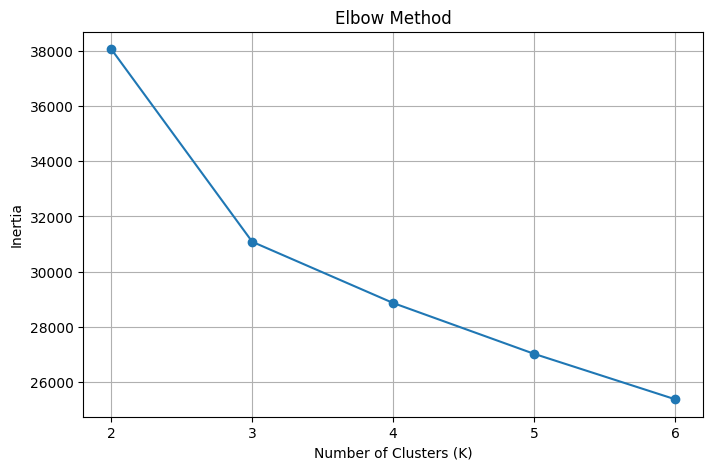

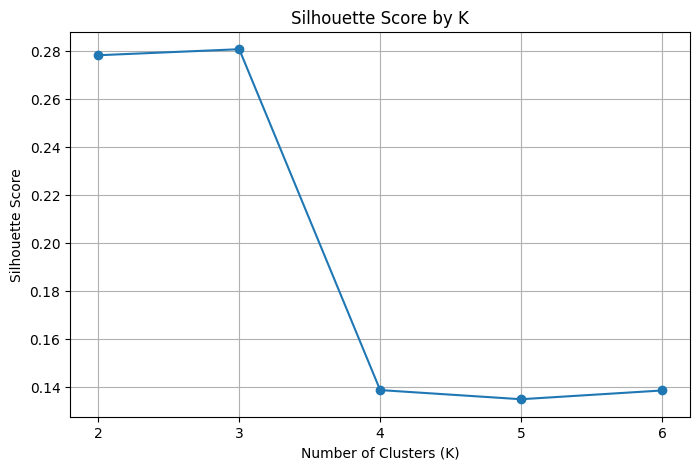

In [ ]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
import matplotlib.pyplot as plt

k_values = range(2, 7)

inertias = []
silhouette_scores = []

for k in k_values:
    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=20
    )

    labels = kmeans.fit_predict(X_scaled)

    inertias.append(kmeans.inertia_)
    silhouette_scores.append(silhouette_score(X_scaled, labels))

print("=" * 60)
print("K-MEANS CLUSTER EVALUATION")
print("=" * 60)

for k, inertia, score in zip(k_values, inertias, silhouette_scores):
    print(f"K={k} | Inertia={inertia:.2f} | Silhouette Score={score:.4f}")

best_k = k_values[silhouette_scores.index(max(silhouette_scores))]

print("\nRecommended K based on highest silhouette score:", best_k)

plt.figure(figsize=(8, 5))
plt.plot(k_values, inertias, marker="o")
plt.xlabel("Number of Clusters (K)")
plt.ylabel("Inertia")
plt.title("Elbow Method")
plt.xticks(list(k_values))
plt.grid(True)
plt.show()

plt.figure(figsize=(8, 5))
plt.plot(k_values, silhouette_scores, marker="o")
plt.xlabel("Number of Clusters (K)")
plt.ylabel("Silhouette Score")
plt.title("Silhouette Score by K")
plt.xticks(list(k_values))
plt.grid(True)
plt.show()

In [ ]:
from sklearn.cluster import KMeans
import pandas as pd

kmeans = KMeans(
    n_clusters=3,
    random_state=42,
    n_init=20
)

market_df["Regime"] = kmeans.fit_predict(X_scaled)

print("=" * 60)
print("3-REGIME K-MEANS RESULTS")
print("=" * 60)

print("\nRegime Distribution:")
print(market_df["Regime"].value_counts().sort_index())

print("\nRegime Percentage:")
print(
    (market_df["Regime"].value_counts(normalize=True).sort_index() * 100)
    .round(2)
)

regime_summary = market_df.groupby("Regime")[regime_features].mean().round(4)

print("\nRegime Characteristics:")
print(regime_summary)

print("\nRegime Date Range:")
for regime in sorted(market_df["Regime"].unique()):
    temp = market_df[market_df["Regime"] == regime]
    print(
        f"Regime {regime}: "
        f"{temp['Date'].min().date()} → {temp['Date'].max().date()} "
        f"({len(temp)} days)"
    )

3-REGIME K-MEANS RESULTS

Regime Distribution:
Regime
0     965
1    3625
2    1151
Name: count, dtype: int64

Regime Percentage:
Regime
0    16.81
1    63.14
2    20.05
Name: proportion, dtype: float64

Regime Characteristics:
        Market_Return  Market_Volatility  Market_Breadth  Return_5D  \
Regime                                                                
0              0.0668             0.1354          0.4284     0.0772   
1             -0.0024             0.0359         -0.0983    -0.0072   
2             -0.0576             0.1048         -0.4232    -0.0943   

        Return_20D  Volatility_5D  Volatility_20D  Volume_Relative  
Regime                                                              
0           0.0129         0.0740          0.0629           1.3907  
1          -0.0330         0.0180          0.0418           0.9956  
2          -0.1230         0.0868          0.0704           0.8274  

Regime Date Range:
Regime 0: 2000-01-11 → 2024-08-11 (965 days)
Regime

In [ ]:
import pandas as pd

print("=" * 60)
print("REGIME PERSISTENCE ANALYSIS")
print("=" * 60)

market_df = market_df.sort_values("Date").reset_index(drop=True)

market_df["Next_Regime"] = market_df["Regime"].shift(-1)

transition_matrix = pd.crosstab(
    market_df["Regime"],
    market_df["Next_Regime"],
    normalize="index"
).round(4)

print("\nRegime Transition Probability:")
print(transition_matrix)

print("\nRegime Transition Count:")
print(
    pd.crosstab(
        market_df["Regime"],
        market_df["Next_Regime"]
    )
)

market_df["Regime_Changed"] = (
    market_df["Regime"] != market_df["Regime"].shift(1)
)

print("\nTotal regime changes:")
print(market_df["Regime_Changed"].sum())

print("\nRegime change percentage:")
print(
    round(market_df["Regime_Changed"].mean() * 100, 2),
    "%"
)

REGIME PERSISTENCE ANALYSIS

Regime Transition Probability:
Next_Regime     0.0     1.0     2.0
Regime                             
0            0.3762  0.2601  0.3637
1            0.0734  0.8687  0.0579
2            0.2911  0.1964  0.5126

Regime Transition Count:
Next_Regime  0.0   1.0  2.0
Regime                     
0            363   251  351
1            266  3148  210
2            335   226  590

Total regime changes:
1640

Regime change percentage:
28.57 %


In [ ]:
import pandas as pd

model_df = market_df.copy()

model_df["Target_Regime"] = model_df["Regime"].shift(-1)

model_df = model_df.dropna(subset=["Target_Regime"]).copy()

model_df["Target_Regime"] = model_df["Target_Regime"].astype(int)

X = model_df[regime_features].copy()
y = model_df["Target_Regime"].copy()

print("=" * 60)
print("XGBOOST DATASET")
print("=" * 60)

print("Total samples:", len(model_df))
print("Number of features:", X.shape[1])

print("\nFeatures:")
print(list(X.columns))

print("\nTarget distribution:")
print(y.value_counts().sort_index())

print("\nTarget percentage:")
print((y.value_counts(normalize=True).sort_index() * 100).round(2))

print("\nDate range:")
print(model_df["Date"].min().date(), "→", model_df["Date"].max().date())

print("\nMissing values:")
print(X.isna().sum().sum())
print("Target missing:", y.isna().sum())

XGBOOST DATASET
Total samples: 5740
Number of features: 8

Features:
['Market_Return', 'Market_Volatility', 'Market_Breadth', 'Return_5D', 'Return_20D', 'Volatility_5D', 'Volatility_20D', 'Volume_Relative']

Target distribution:
Target_Regime
0     964
1    3625
2    1151
Name: count, dtype: int64

Target percentage:
Target_Regime
0    16.79
1    63.15
2    20.05
Name: proportion, dtype: float64

Date range:
2000-01-11 → 2025-04-07

Missing values:
0
Target missing: 0


In [ ]:
import pandas as pd

n = len(model_df)

train_end = int(n * 0.70)
val_end = int(n * 0.85)

X_train = X.iloc[:train_end].copy()
y_train = y.iloc[:train_end].copy()

X_val = X.iloc[train_end:val_end].copy()
y_val = y.iloc[train_end:val_end].copy()

X_test = X.iloc[val_end:].copy()
y_test = y.iloc[val_end:].copy()

print("=" * 60)
print("TIME-BASED DATA SPLIT")
print("=" * 60)

print("\nTraining:")
print("Samples:", len(X_train))
print("Date:", model_df["Date"].iloc[0].date(), "→", model_df["Date"].iloc[train_end - 1].date())

print("\nValidation:")
print("Samples:", len(X_val))
print("Date:", model_df["Date"].iloc[train_end].date(), "→", model_df["Date"].iloc[val_end - 1].date())

print("\nTesting:")
print("Samples:", len(X_test))
print("Date:", model_df["Date"].iloc[val_end].date(), "→", model_df["Date"].iloc[-1].date())

print("\nTarget distribution:")

print("\nTraining:")
print(y_train.value_counts(normalize=True).sort_index().round(4))

print("\nValidation:")
print(y_val.value_counts(normalize=True).sort_index().round(4))

print("\nTesting:")
print(y_test.value_counts(normalize=True).sort_index().round(4))

TIME-BASED DATA SPLIT

Training:
Samples: 4017
Date: 2000-01-11 → 2017-11-26

Validation:
Samples: 862
Date: 2017-11-27 → 2021-08-19

Testing:
Samples: 861
Date: 2021-08-22 → 2025-04-07

Target distribution:

Training:
Target_Regime
0    0.1957
1    0.5703
2    0.2340
Name: proportion, dtype: float64

Validation:
Target_Regime
0    0.1671
1    0.6125
2    0.2204
Name: proportion, dtype: float64

Testing:
Target_Regime
0    0.0395
1    0.9361
2    0.0244
Name: proportion, dtype: float64


In [ ]:
print("=" * 60)
print("REGIME DISTRIBUTION BY TIME PERIOD")
print("=" * 60)

temp = market_df.copy()

temp["Year"] = temp["Date"].dt.year

yearly_regime = pd.crosstab(
    temp["Year"],
    temp["Regime"],
    normalize="index"
).fillna(0) * 100

yearly_regime = yearly_regime.round(2)

print("\nRegime percentage by year:")
print(yearly_regime)

print("\nRecent 10 years:")
print(yearly_regime.tail(10))

print("\nRegime counts by year:")
yearly_counts = pd.crosstab(
    temp["Year"],
    temp["Regime"]
)

print(yearly_counts.tail(10))

REGIME DISTRIBUTION BY TIME PERIOD

Regime percentage by year:
Regime      0       1      2
Year                        
2000    16.78   68.53  14.69
2001    24.14   68.97   6.90
2002    16.52   77.23   6.25
2003    12.36   77.82   9.82
2004    31.62   45.85  22.53
2005    20.70   59.38  19.92
2006    17.98   70.18  11.84
2007    23.31   39.83  36.86
2008    16.02   40.26  43.72
2009    27.87   41.39  30.74
2010    25.00   47.54  27.46
2011    23.61   20.60  55.79
2012    27.85   27.43  44.73
2013    23.95   52.94  23.11
2014    13.03   62.61  24.37
2015    14.75   68.03  17.21
2016    10.79   82.57   6.64
2017     8.06   90.32   1.61
2018    11.16   72.31  16.53
2019    14.35   58.23  27.43
2020    22.60   55.77  21.63
2021    22.08   54.17  23.75
2022     6.09   92.17   1.74
2023     0.00  100.00   0.00
2024     0.85   99.15   0.00
2025     0.00  100.00   0.00

Recent 10 years:
Regime      0       1      2
Year                        
2016    10.79   82.57   6.64
2017     8.06   90.3

In [ ]:
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
import pandas as pd

print("=" * 60)
print("LEAKAGE-FREE REGIME DISCOVERY")
print("=" * 60)

regime_features = [
    "Market_Return",
    "Market_Volatility",
    "Market_Breadth",
    "Return_5D",
    "Return_20D",
    "Volatility_5D",
    "Volatility_20D",
    "Volume_Relative"
]

regime_df = market_df.sort_values("Date").reset_index(drop=True).copy()

n = len(regime_df)

train_end = int(n * 0.70)
val_end = int(n * 0.85)

train_regime = regime_df.iloc[:train_end].copy()
val_regime = regime_df.iloc[train_end:val_end].copy()
test_regime = regime_df.iloc[val_end:].copy()

X_train_regime = train_regime[regime_features]
X_val_regime = val_regime[regime_features]
X_test_regime = test_regime[regime_features]

scaler_train = StandardScaler()

X_train_scaled = scaler_train.fit_transform(X_train_regime)
X_val_scaled = scaler_train.transform(X_val_regime)
X_test_scaled = scaler_train.transform(X_test_regime)

kmeans_train = KMeans(
    n_clusters=3,
    random_state=42,
    n_init=20
)

train_labels = kmeans_train.fit_predict(X_train_scaled)
val_labels = kmeans_train.predict(X_val_scaled)
test_labels = kmeans_train.predict(X_test_scaled)

train_regime["Regime"] = train_labels
val_regime["Regime"] = val_labels
test_regime["Regime"] = test_labels

print("\nTraining:")
print(
    train_regime["Regime"]
    .value_counts()
    .sort_index()
)

print("\nValidation:")
print(
    val_regime["Regime"]
    .value_counts()
    .sort_index()
)

print("\nTesting:")
print(
    test_regime["Regime"]
    .value_counts()
    .sort_index()
)

print("\nTraining percentage:")
print(
    (train_regime["Regime"]
     .value_counts(normalize=True)
     .sort_index() * 100).round(2)
)

print("\nValidation percentage:")
print(
    (val_regime["Regime"]
     .value_counts(normalize=True)
     .sort_index() * 100).round(2)
)

print("\nTesting percentage:")
print(
    (test_regime["Regime"]
     .value_counts(normalize=True)
     .sort_index() * 100).round(2)
)

print("\nDate ranges:")
print(
    "Training:",
    train_regime["Date"].min().date(),
    "→",
    train_regime["Date"].max().date()
)

print(
    "Validation:",
    val_regime["Date"].min().date(),
    "→",
    val_regime["Date"].max().date()
)

print(
    "Testing:",
    test_regime["Date"].min().date(),
    "→",
    test_regime["Date"].max().date()
)


LEAKAGE-FREE REGIME DISCOVERY

Training:
Regime
0     782
1    2492
2     744
Name: count, dtype: int64

Validation:
Regime
0    137
1    592
2    132
Name: count, dtype: int64

Testing:
Regime
0     14
1    815
2     33
Name: count, dtype: int64

Training percentage:
Regime
0    19.46
1    62.02
2    18.52
Name: proportion, dtype: float64

Validation percentage:
Regime
0    15.91
1    68.76
2    15.33
Name: proportion, dtype: float64

Testing percentage:
Regime
0     1.62
1    94.55
2     3.83
Name: proportion, dtype: float64

Date ranges:
Training: 2000-01-11 → 2017-11-27
Validation: 2017-11-28 → 2021-08-19
Testing: 2021-08-22 → 2025-04-08


In [ ]:
print("=" * 60)
print("LEAKAGE-FREE REGIME CHARACTERISTICS")
print("=" * 60)

train_characteristics = train_regime.groupby("Regime")[regime_features].mean().round(4)

print("\nTraining Regime Characteristics:")
print(train_characteristics)

print("\nTraining Regime Percentages:")
print(
    (train_regime["Regime"]
     .value_counts(normalize=True)
     .sort_index() * 100).round(2)
)

print("\nValidation Regime Characteristics:")
print(
    val_regime.groupby("Regime")[regime_features]
    .mean()
    .round(4)
)

print("\nTesting Regime Characteristics:")
print(
    test_regime.groupby("Regime")[regime_features]
    .mean()
    .round(4)
)

print("\nK-Means Cluster Centers:")
cluster_centers = pd.DataFrame(
    scaler_train.inverse_transform(kmeans_train.cluster_centers_),
    columns=regime_features
)

cluster_centers.index.name = "Regime"
print(cluster_centers.round(4))

LEAKAGE-FREE REGIME CHARACTERISTICS

Training Regime Characteristics:
        Market_Return  Market_Volatility  Market_Breadth  Return_5D  \
Regime                                                                
0             -0.0641             0.1072         -0.4209    -0.1085   
1             -0.0034             0.0422         -0.0880    -0.0060   
2              0.0702             0.1389          0.4434     0.0812   

        Return_20D  Volatility_5D  Volatility_20D  Volume_Relative  
Regime                                                              
0          -0.1333         0.0997          0.0770           0.8279  
1          -0.0294         0.0229          0.0513           1.0007  
2           0.0155         0.0752          0.0647           1.3706  

Training Regime Percentages:
Regime
0    19.46
1    62.02
2    18.52
Name: proportion, dtype: float64

Validation Regime Characteristics:
        Market_Return  Market_Volatility  Market_Breadth  Return_5D  \
Regime             

In [ ]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

print("=" * 60)
print("TRAINING-ONLY K-MEANS EVALUATION")
print("=" * 60)

results = []

for k in range(2, 7):
    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=20
    )

    labels = kmeans.fit_predict(X_train_scaled)

    inertia = kmeans.inertia_
    silhouette = silhouette_score(X_train_scaled, labels)

    results.append({
        "K": k,
        "Inertia": inertia,
        "Silhouette": silhouette
    })

results_df = pd.DataFrame(results)

print("\nK-Means Evaluation:")
print(results_df.round(4))

best_k = results_df.loc[
    results_df["Silhouette"].idxmax(), "K"
]

print("\nBest K based on training silhouette:", int(best_k))

TRAINING-ONLY K-MEANS EVALUATION

K-Means Evaluation:
   K     Inertia  Silhouette
0  2  26652.6616      0.2520
1  3  22028.1900      0.2649
2  4  20508.7554      0.2563
3  5  19029.6601      0.1350
4  6  17848.5145      0.1399

Best K based on training silhouette: 3


In [ ]:
print("=" * 60)
print("PREPARING XGBOOST TARGET")
print("=" * 60)

labeled_market_df = pd.concat(
    [train_regime, val_regime, test_regime],
    ignore_index=True
).sort_values("Date").reset_index(drop=True)

labeled_market_df["Target_Regime"] = (
    labeled_market_df["Regime"].shift(-1)
)

model_df = labeled_market_df.dropna(
    subset=["Target_Regime"]
).copy()

model_df["Target_Regime"] = (
    model_df["Target_Regime"].astype(int)
)

X = model_df[regime_features].copy()
y = model_df["Target_Regime"].copy()

print("\nDataset shape:", model_df.shape)
print("Features:", X.shape)
print("Target:", y.shape)

print("\nTarget distribution:")
print(y.value_counts().sort_index())

print("\nTarget percentage:")
print(
    (y.value_counts(normalize=True).sort_index() * 100).round(2)
)

print("\nDate range:")
print(
    model_df["Date"].min().date(),
    "→",
    model_df["Date"].max().date()
)

print("\nMissing values:")
print(X.isna().sum().sum() + y.isna().sum())

print("\nFirst 5 rows:")
print(
    model_df[
        ["Date", "Regime", "Target_Regime"]
        + regime_features
    ].head()
)

PREPARING XGBOOST TARGET

Dataset shape: (5740, 22)
Features: (5740, 8)
Target: (5740,)

Target distribution:
Target_Regime
0     933
1    3899
2     908
Name: count, dtype: int64

Target percentage:
Target_Regime
0    16.25
1    67.93
2    15.82
Name: proportion, dtype: float64

Date range:
2000-01-11 → 2025-04-07

Missing values:
0

First 5 rows:
        Date  Regime  Target_Regime  Market_Return  Market_Volatility  \
0 2000-01-11       2              1       0.008600           0.134373   
1 2000-01-19       1              1      -0.004906           0.024912   
2 2000-02-05       1              2      -0.003724           0.093214   
3 2000-02-08       2              2       0.133489           0.145301   
4 2000-02-09       2              2       0.030450           0.094649   

   Market_Breadth  Return_5D  Return_20D  Volatility_5D  Volatility_20D  \
0        0.183673   0.201547    0.122031       0.077904        0.048128   
1       -0.333333  -0.167292    0.072863       0.070987     

In [ ]:
print("=" * 60)
print("CREATING CHRONOLOGICAL XGBOOST SPLITS")
print("=" * 60)

train_end_date = train_regime["Date"].max()
val_end_date = val_regime["Date"].max()

train_model = model_df[
    model_df["Date"] <= train_end_date
].copy()

val_model = model_df[
    (model_df["Date"] > train_end_date) &
    (model_df["Date"] <= val_end_date)
].copy()

test_model = model_df[
    model_df["Date"] > val_end_date
].copy()

X_train = train_model[regime_features]
y_train = train_model["Target_Regime"]

X_val = val_model[regime_features]
y_val = val_model["Target_Regime"]

X_test = test_model[regime_features]
y_test = test_model["Target_Regime"]

print("\nDataset sizes:")
print("Training:", X_train.shape)
print("Validation:", X_val.shape)
print("Testing:", X_test.shape)

print("\nDate ranges:")
print(
    "Training:",
    train_model["Date"].min().date(),
    "→",
    train_model["Date"].max().date()
)

print(
    "Validation:",
    val_model["Date"].min().date(),
    "→",
    val_model["Date"].max().date()
)

print(
    "Testing:",
    test_model["Date"].min().date(),
    "→",
    test_model["Date"].max().date()
)

print("\nTarget distribution:")

print("\nTraining:")
print(y_train.value_counts().sort_index())

print("\nValidation:")
print(y_val.value_counts().sort_index())

print("\nTesting:")
print(y_test.value_counts().sort_index())

print("\nTarget percentages:")

print("\nTraining:")
print(
    (y_train.value_counts(normalize=True).sort_index() * 100).round(2)
)

print("\nValidation:")
print(
    (y_val.value_counts(normalize=True).sort_index() * 100).round(2)
)

print("\nTesting:")
print(
    (y_test.value_counts(normalize=True).sort_index() * 100).round(2)
)

CREATING CHRONOLOGICAL XGBOOST SPLITS

Dataset sizes:
Training: (4018, 8)
Validation: (861, 8)
Testing: (861, 8)

Date ranges:
Training: 2000-01-11 → 2017-11-27
Validation: 2017-11-28 → 2021-08-19
Testing: 2021-08-22 → 2025-04-07

Target distribution:

Training:
Target_Regime
0     782
1    2493
2     743
Name: count, dtype: int64

Validation:
Target_Regime
0    137
1    592
2    132
Name: count, dtype: int64

Testing:
Target_Regime
0     14
1    814
2     33
Name: count, dtype: int64

Target percentages:

Training:
Target_Regime
0    19.46
1    62.05
2    18.49
Name: proportion, dtype: float64

Validation:
Target_Regime
0    15.91
1    68.76
2    15.33
Name: proportion, dtype: float64

Testing:
Target_Regime
0     1.63
1    94.54
2     3.83
Name: proportion, dtype: float64


In [ ]:
from sklearn.utils.class_weight import compute_class_weight
import numpy as np

classes = np.unique(y_train)

class_weights = compute_class_weight(
    class_weight="balanced",
    classes=classes,
    y=y_train
)

class_weight_dict = dict(zip(classes, class_weights))

sample_weights = y_train.map(class_weight_dict)

print("=" * 60)
print("CLASS WEIGHTS")
print("=" * 60)

for cls, weight in class_weight_dict.items():
    print(f"Regime {cls}: {weight:.4f}")

print("\nSample weight summary:")
print(sample_weights.describe().round(4))

CLASS WEIGHTS
Regime 0: 1.7127
Regime 1: 0.5372
Regime 2: 1.8026

Sample weight summary:
count    4018.0000
mean        1.0000
std         0.5924
min         0.5372
25%         0.5372
50%         0.5372
75%         1.7127
max         1.8026
Name: Target_Regime, dtype: float64


In [ ]:
from xgboost import XGBClassifier
from sklearn.metrics import accuracy_score, f1_score, classification_report, confusion_matrix

print("=" * 60)
print("XGBOOST BASELINE MODEL")
print("=" * 60)

xgb_model = XGBClassifier(
    objective="multi:softprob",
    num_class=3,
    n_estimators=300,
    max_depth=5,
    learning_rate=0.05,
    subsample=0.8,
    colsample_bytree=0.8,
    random_state=42,
    eval_metric="mlogloss"
)

xgb_model.fit(
    X_train,
    y_train,
    sample_weight=sample_weights,
    eval_set=[(X_val, y_val)],
    verbose=False
)

y_val_pred = xgb_model.predict(X_val)

val_accuracy = accuracy_score(y_val, y_val_pred)
val_macro_f1 = f1_score(y_val, y_val_pred, average="macro")

print("\nValidation Accuracy:", round(val_accuracy, 4))
print("Validation Macro F1:", round(val_macro_f1, 4))

print("\nClassification Report:")
print(
    classification_report(
        y_val,
        y_val_pred,
        target_names=["Bear", "Neutral", "Bull"],
        digits=4
    )
)

print("\nConfusion Matrix:")
print(
    confusion_matrix(
        y_val,
        y_val_pred
    )
)

XGBOOST BASELINE MODEL

Validation Accuracy: 0.6818
Validation Macro F1: 0.5261

Classification Report:
              precision    recall  f1-score   support

        Bear     0.4412    0.3285    0.3766       137
     Neutral     0.8856    0.8108    0.8466       592
        Bull     0.2857    0.4697    0.3553       132

    accuracy                         0.6818       861
   macro avg     0.5375    0.5363    0.5261       861
weighted avg     0.7229    0.6818    0.6965       861


Confusion Matrix:
[[ 45  22  70]
 [ 27 480  85]
 [ 30  40  62]]


In [6]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [7]:
!find /content/drive/MyDrive -iname "*DSE*" -type f

/content/drive/MyDrive/DSE_Data.csv
/content/drive/MyDrive/DSE_Data_Cleaned.csv
/content/drive/MyDrive/DSE_Data_Final.csv


In [8]:
import pandas as pd
import numpy as np

file_path = "/content/drive/MyDrive/DSE_Data_Final.csv"

df = pd.read_csv(file_path)

df["Date"] = pd.to_datetime(df["Date"])

print("=" * 60)
print("DSE FINAL DATA LOADED")
print("=" * 60)
print("Shape:", df.shape)
print("Date Range:", df["Date"].min().date(), "to", df["Date"].max().date())
print("Columns:", df.columns.tolist())
print("\nMissing Values:")
print(df.isnull().sum())


DSE FINAL DATA LOADED
Shape: (1432599, 7)
Date Range: 1999-01-02 to 2025-04-08
Columns: ['Trading_Code', 'Date', 'Open', 'High', 'Low', 'Close', 'Volume']

Missing Values:
Trading_Code    0
Date            0
Open            0
High            0
Low             0
Close           0
Volume          2
dtype: int64


In [9]:
df = df.dropna(subset=["Volume"]).copy()

print("=" * 60)
print("DATA VALIDATION")
print("=" * 60)
print("Shape after removing missing Volume:", df.shape)
print("Missing Values:")
print(df.isnull().sum().sum())


DATA VALIDATION
Shape after removing missing Volume: (1432597, 7)
Missing Values:
0


In [10]:
df = df.sort_values(["Trading_Code", "Date"]).reset_index(drop=True)

df["Return"] = df.groupby("Trading_Code")["Close"].pct_change()
df["Return"] = df["Return"].replace([np.inf, -np.inf], np.nan)

market_return_df = df[
    df["Return"].between(-0.50, 0.50)
].copy()

market_df = market_return_df.groupby("Date").agg(
    Market_Return=("Return", "median"),
    Market_Volatility=("Return", "std"),
    Return_Dispersion=("Return", "std"),
    Total_Volume=("Volume", "sum"),
    Number_of_Stocks=("Trading_Code", "nunique")
).reset_index()

daily_direction = market_return_df.copy()
daily_direction["Direction"] = np.select(
    [
        daily_direction["Return"] > 0,
        daily_direction["Return"] < 0
    ],
    [
        "Advance",
        "Decline"
    ],
    default="Unchanged"
)

direction_counts = (
    daily_direction
    .groupby(["Date", "Direction"])
    .size()
    .unstack(fill_value=0)
    .reset_index()
)

for col in ["Advance", "Decline", "Unchanged"]:
    if col not in direction_counts.columns:
        direction_counts[col] = 0

direction_counts = direction_counts.rename(
    columns={
        "Advance": "Advancing",
        "Decline": "Declining"
    }
)

market_df = market_df.merge(
    direction_counts[
        ["Date", "Advancing", "Declining", "Unchanged"]
    ],
    on="Date",
    how="left"
)

market_df["Advance_Decline_Ratio"] = (
    market_df["Advancing"] /
    market_df["Declining"].replace(0, np.nan)
)

market_df["Market_Breadth"] = (
    (market_df["Advancing"] - market_df["Declining"]) /
    market_df["Number_of_Stocks"]
)

market_df = market_df.sort_values("Date").reset_index(drop=True)

market_df["Return_5D"] = market_df["Market_Return"].rolling(5).sum()
market_df["Return_20D"] = market_df["Market_Return"].rolling(20).sum()

market_df["Volatility_5D"] = (
    market_df["Market_Return"].rolling(5).std()
)

market_df["Volatility_20D"] = (
    market_df["Market_Return"].rolling(20).std()
)

market_df["Volume_Change"] = (
    market_df["Total_Volume"].pct_change()
)

market_df["Volume_MA_20"] = (
    market_df["Total_Volume"].rolling(20).mean()
)

market_df["Volume_Relative"] = (
    market_df["Total_Volume"] /
    market_df["Volume_MA_20"]
)

market_df = market_df.dropna().reset_index(drop=True)

print("=" * 60)
print("MARKET FEATURES REBUILT")
print("=" * 60)
print("Shape:", market_df.shape)
print("Date Range:",
      market_df["Date"].min().date(),
      "to",
      market_df["Date"].max().date())

print("\nColumns:")
print(market_df.columns.tolist())

print("\nNumber of Stocks:")
print(market_df["Number_of_Stocks"].describe())

MARKET FEATURES REBUILT
Shape: (6391, 18)
Date Range: 1999-02-10 to 2025-04-08

Columns:
['Date', 'Market_Return', 'Market_Volatility', 'Return_Dispersion', 'Total_Volume', 'Number_of_Stocks', 'Advancing', 'Declining', 'Unchanged', 'Advance_Decline_Ratio', 'Market_Breadth', 'Return_5D', 'Return_20D', 'Volatility_5D', 'Volatility_20D', 'Volume_Change', 'Volume_MA_20', 'Volume_Relative']

Number of Stocks:
count    6391.000000
mean      220.238147
std       122.038685
min         2.000000
25%        81.000000
50%       248.000000
75%       330.000000
max       399.000000
Name: Number_of_Stocks, dtype: float64


In [11]:
market_df = market_df[
    market_df["Number_of_Stocks"] >= 50
].copy()

market_df = market_df.sort_values("Date").reset_index(drop=True)

print("=" * 60)
print("MARKET COVERAGE FILTER")
print("=" * 60)
print("Minimum Stocks per Day: 50")
print("Remaining Market Days:", len(market_df))
print("Date Range:",
      market_df["Date"].min().date(),
      "to",
      market_df["Date"].max().date())

print("\nNumber of Stocks Statistics:")
print(market_df["Number_of_Stocks"].describe())


MARKET COVERAGE FILTER
Minimum Stocks per Day: 50
Remaining Market Days: 5742
Date Range: 2000-01-11 to 2025-04-08

Number of Stocks Statistics:
count    5742.000000
mean      240.117903
std       112.612166
min        50.000000
25%       105.000000
50%       261.000000
75%       334.000000
max       399.000000
Name: Number_of_Stocks, dtype: float64


In [12]:
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

regime_features = [
    "Market_Return",
    "Market_Volatility",
    "Market_Breadth",
    "Return_5D",
    "Return_20D",
    "Volatility_5D",
    "Volatility_20D",
    "Volume_Relative"
]

n = len(market_df)

train_end = int(n * 0.70)
val_end = int(n * 0.85)

train_market = market_df.iloc[:train_end].copy()
val_market = market_df.iloc[train_end:val_end].copy()
test_market = market_df.iloc[val_end:].copy()

print("=" * 60)
print("CHRONOLOGICAL MARKET SPLIT")
print("=" * 60)

print("\nTrain:")
print("Rows:", len(train_market))
print("Dates:", train_market["Date"].min().date(), "to",
      train_market["Date"].max().date())

print("\nValidation:")
print("Rows:", len(val_market))
print("Dates:", val_market["Date"].min().date(), "to",
      val_market["Date"].max().date())

print("\nTest:")
print("Rows:", len(test_market))
print("Dates:", test_market["Date"].min().date(), "to",
      test_market["Date"].max().date())

print("\nRegime Features:")
print(regime_features)

scaler = StandardScaler()

X_train_regime = scaler.fit_transform(
    train_market[regime_features]
)

X_val_regime = scaler.transform(
    val_market[regime_features]
)

X_test_regime = scaler.transform(
    test_market[regime_features]
)

print("\nScaler fitted on training data only.")
print("Train feature matrix:", X_train_regime.shape)
print("Validation feature matrix:", X_val_regime.shape)
print("Test feature matrix:", X_test_regime.shape)

CHRONOLOGICAL MARKET SPLIT

Train:
Rows: 4019
Dates: 2000-01-11 to 2017-11-27

Validation:
Rows: 861
Dates: 2017-11-28 to 2021-08-19

Test:
Rows: 862
Dates: 2021-08-22 to 2025-04-08

Regime Features:
['Market_Return', 'Market_Volatility', 'Market_Breadth', 'Return_5D', 'Return_20D', 'Volatility_5D', 'Volatility_20D', 'Volume_Relative']

Scaler fitted on training data only.
Train feature matrix: (4019, 8)
Validation feature matrix: (861, 8)
Test feature matrix: (862, 8)


In [13]:
k_results = []

print("=" * 60)
print("TRAINING-ONLY K-MEANS EVALUATION")
print("=" * 60)

for k in range(2, 7):
    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=20
    )

    train_labels = kmeans.fit_predict(X_train_regime)

    inertia = kmeans.inertia_
    silhouette = silhouette_score(X_train_regime, train_labels)

    k_results.append({
        "K": k,
        "Inertia": inertia,
        "Silhouette_Score": silhouette
    })

    print(
        f"K={k} | "
        f"Inertia={inertia:.4f} | "
        f"Silhouette={silhouette:.4f}"
    )

k_results_df = pd.DataFrame(k_results)

best_k = k_results_df.loc[
    k_results_df["Silhouette_Score"].idxmax(),
    "K"
]

print("\n" + "=" * 60)
print("BEST K BASED ON TRAINING SILHOUETTE SCORE:", int(best_k))
print("=" * 60)

print("\nResults Table:")
print(k_results_df)


TRAINING-ONLY K-MEANS EVALUATION
K=2 | Inertia=26626.4639 | Silhouette=0.2522
K=3 | Inertia=21971.1268 | Silhouette=0.2683
K=4 | Inertia=20433.1327 | Silhouette=0.2594
K=5 | Inertia=19027.2948 | Silhouette=0.1327
K=6 | Inertia=17843.5552 | Silhouette=0.1429

BEST K BASED ON TRAINING SILHOUETTE SCORE: 3

Results Table:
   K       Inertia  Silhouette_Score
0  2  26626.463926          0.252193
1  3  21971.126831          0.268299
2  4  20433.132696          0.259395
3  5  19027.294829          0.132715
4  6  17843.555177          0.142888


In [14]:
final_k = 3

kmeans_final = KMeans(
    n_clusters=final_k,
    random_state=42,
    n_init=20
)

train_market["Regime"] = kmeans_final.fit_predict(X_train_regime)

val_market["Regime"] = kmeans_final.predict(X_val_regime)

test_market["Regime"] = kmeans_final.predict(X_test_regime)

print("=" * 60)
print("FINAL LEAKAGE-FREE K-MEANS REGIMES")
print("=" * 60)

print("\nTraining Regime Distribution:")
print(
    train_market["Regime"]
    .value_counts()
    .sort_index()
)

print("\nValidation Regime Distribution:")
print(
    val_market["Regime"]
    .value_counts()
    .sort_index()
)

print("\nTest Regime Distribution:")
print(
    test_market["Regime"]
    .value_counts()
    .sort_index()
)


FINAL LEAKAGE-FREE K-MEANS REGIMES

Training Regime Distribution:
Regime
0     729
1    2503
2     787
Name: count, dtype: int64

Validation Regime Distribution:
Regime
0    128
1    591
2    142
Name: count, dtype: int64

Test Regime Distribution:
Regime
0     30
1    818
2     14
Name: count, dtype: int64


In [15]:
cluster_profile = train_market.groupby("Regime")[regime_features].mean()

print("=" * 60)
print("TRAINING REGIME CHARACTERISTICS")
print("=" * 60)
print(cluster_profile.round(4))


TRAINING REGIME CHARACTERISTICS
        Market_Return  Market_Volatility  Market_Breadth  Return_5D  \
Regime                                                                
0              0.0716             0.1392          0.4462     0.0831   
1             -0.0033             0.0427         -0.0813    -0.0060   
2             -0.0638             0.1070         -0.4150    -0.1079   

        Return_20D  Volatility_5D  Volatility_20D  Volume_Relative  
Regime                                                              
0           0.0157         0.0755          0.0650           1.3696  
1          -0.0293         0.0229          0.0512           1.0028  
2          -0.1324         0.0997          0.0771           0.8298  


In [16]:
labeled_market_df = pd.concat(
    [
        train_market,
        val_market,
        test_market
    ],
    ignore_index=True
).sort_values("Date").reset_index(drop=True)

labeled_market_df["Target_Regime"] = (
    labeled_market_df["Regime"].shift(-1)
)

model_df = labeled_market_df.dropna(
    subset=["Target_Regime"]
).copy()

model_df["Target_Regime"] = (
    model_df["Target_Regime"].astype(int)
)

X = model_df[regime_features].copy()
y = model_df["Target_Regime"].copy()

print("=" * 60)
print("NEXT-DAY REGIME TARGET")
print("=" * 60)

print("Dataset Shape:", model_df.shape)
print("Feature Shape:", X.shape)
print("Target Shape:", y.shape)

print("\nTarget Distribution:")
print(
    y.value_counts()
     .sort_index()
)

print("\nDate Range:",
      model_df["Date"].min().date(),
      "to",
      model_df["Date"].max().date())

print("\nFirst 5 Rows:")
print(
    model_df[
        ["Date", "Regime", "Target_Regime"]
    ].head()
)

NEXT-DAY REGIME TARGET
Dataset Shape: (5741, 20)
Feature Shape: (5741, 8)
Target Shape: (5741,)

Target Distribution:
Target_Regime
0     886
1    3912
2     943
Name: count, dtype: int64

Date Range: 2000-01-11 to 2025-04-07

First 5 Rows:
        Date  Regime  Target_Regime
0 2000-01-11       0              1
1 2000-01-19       1              1
2 2000-02-05       1              0
3 2000-02-08       0              0
4 2000-02-09       0              0


In [17]:
n = len(model_df)

train_end = int(n * 0.70)
val_end = int(n * 0.85)

X_train = X.iloc[:train_end].copy()
X_val = X.iloc[train_end:val_end].copy()
X_test = X.iloc[val_end:].copy()

y_train = y.iloc[:train_end].copy()
y_val = y.iloc[train_end:val_end].copy()
y_test = y.iloc[val_end:].copy()

train_model = model_df.iloc[:train_end].copy()
val_model = model_df.iloc[train_end:val_end].copy()
test_model = model_df.iloc[val_end:].copy()

print("=" * 60)
print("CHRONOLOGICAL XGBOOST SPLIT")
print("=" * 60)

print("\nTrain:")
print("X:", X_train.shape)
print("Dates:", train_model["Date"].min().date(), "to",
      train_model["Date"].max().date())

print("\nValidation:")
print("X:", X_val.shape)
print("Dates:", val_model["Date"].min().date(), "to",
      val_model["Date"].max().date())

print("\nTest:")
print("X:", X_test.shape)
print("Dates:", test_model["Date"].min().date(), "to",
      test_model["Date"].max().date())

print("\nTarget Distribution:")
print("\nTrain:")
print(y_train.value_counts().sort_index())

print("\nValidation:")
print(y_val.value_counts().sort_index())

print("\nTest:")
print(y_test.value_counts().sort_index())


CHRONOLOGICAL XGBOOST SPLIT

Train:
X: (4018, 8)
Dates: 2000-01-11 to 2017-11-26

Validation:
X: (861, 8)
Dates: 2017-11-27 to 2021-08-18

Test:
X: (862, 8)
Dates: 2021-08-19 to 2025-04-07

Target Distribution:

Train:
Target_Regime
0     728
1    2503
2     787
Name: count, dtype: int64

Validation:
Target_Regime
0    128
1    591
2    142
Name: count, dtype: int64

Test:
Target_Regime
0     30
1    818
2     14
Name: count, dtype: int64


In [18]:
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    classification_report,
    confusion_matrix
)

y_val_persistence = val_model["Regime"].values

persistence_accuracy = accuracy_score(
    y_val,
    y_val_persistence
)

persistence_macro_f1 = f1_score(
    y_val,
    y_val_persistence,
    average="macro"
)

print("=" * 60)
print("PERSISTENCE BASELINE")
print("=" * 60)

print("\nValidation Accuracy:",
      round(persistence_accuracy, 4))

print("Validation Macro F1:",
      round(persistence_macro_f1, 4))

print("\nClassification Report:")
print(
    classification_report(
        y_val,
        y_val_persistence,
        target_names=["Bull", "Neutral", "Bear"],
        digits=4
    )
)

print("\nConfusion Matrix:")
print(
    confusion_matrix(
        y_val,
        y_val_persistence
    )
)

PERSISTENCE BASELINE

Validation Accuracy: 0.6922
Validation Macro F1: 0.5327

Classification Report:
              precision    recall  f1-score   support

        Bull     0.3359    0.3359    0.3359       128
     Neutral     0.8325    0.8325    0.8325       591
        Bear     0.4296    0.4296    0.4296       142

    accuracy                         0.6922       861
   macro avg     0.5327    0.5327    0.5327       861
weighted avg     0.6922    0.6922    0.6922       861


Confusion Matrix:
[[ 43  50  35]
 [ 53 492  46]
 [ 32  49  61]]


In [19]:
from sklearn.utils.class_weight import compute_class_weight
from xgboost import XGBClassifier
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    classification_report,
    confusion_matrix
)

classes = np.unique(y_train)

class_weights = compute_class_weight(
    class_weight="balanced",
    classes=classes,
    y=y_train
)

class_weight_dict = dict(
    zip(classes, class_weights)
)

sample_weights = y_train.map(class_weight_dict).values

print("=" * 60)
print("CLASS WEIGHTS")
print("=" * 60)

for cls, weight in class_weight_dict.items():
    print(f"Regime {cls}: {weight:.4f}")

xgb_model = XGBClassifier(
    objective="multi:softprob",
    num_class=3,
    n_estimators=300,
    max_depth=5,
    learning_rate=0.05,
    subsample=0.8,
    colsample_bytree=0.8,
    random_state=42,
    eval_metric="mlogloss"
)

xgb_model.fit(
    X_train,
    y_train,
    sample_weight=sample_weights,
    eval_set=[(X_val, y_val)],
    verbose=False
)

y_val_pred = xgb_model.predict(X_val)

xgb_val_accuracy = accuracy_score(
    y_val,
    y_val_pred
)

xgb_val_macro_f1 = f1_score(
    y_val,
    y_val_pred,
    average="macro"
)

print("\n" + "=" * 60)
print("XGBOOST BASELINE")
print("=" * 60)

print("\nValidation Accuracy:",
      round(xgb_val_accuracy, 4))

print("Validation Macro F1:",
      round(xgb_val_macro_f1, 4))

print("\nClassification Report:")
print(
    classification_report(
        y_val,
        y_val_pred,
        target_names=["Bull", "Neutral", "Bear"],
        digits=4
    )
)

print("\nConfusion Matrix:")
print(
    confusion_matrix(
        y_val,
        y_val_pred
    )
)

CLASS WEIGHTS
Regime 0: 1.8397
Regime 1: 0.5351
Regime 2: 1.7018

XGBOOST BASELINE

Validation Accuracy: 0.6899
Validation Macro F1: 0.5361

Classification Report:
              precision    recall  f1-score   support

        Bull     0.2814    0.4375    0.3425       128
     Neutral     0.8850    0.8206    0.8516       591
        Bear     0.4649    0.3732    0.4141       142

    accuracy                         0.6899       861
   macro avg     0.5438    0.5438    0.5361       861
weighted avg     0.7260    0.6899    0.7038       861


Confusion Matrix:
[[ 56  38  34]
 [ 79 485  27]
 [ 64  25  53]]


In [20]:
from sklearn.metrics import accuracy_score, f1_score
from xgboost import XGBClassifier

configs = [
    {
        "name": "Baseline",
        "n_estimators": 300,
        "max_depth": 5,
        "learning_rate": 0.05,
        "subsample": 0.8,
        "colsample_bytree": 0.8
    },
    {
        "name": "Shallow",
        "n_estimators": 400,
        "max_depth": 3,
        "learning_rate": 0.05,
        "subsample": 0.8,
        "colsample_bytree": 0.8
    },
    {
        "name": "Deeper",
        "n_estimators": 300,
        "max_depth": 7,
        "learning_rate": 0.05,
        "subsample": 0.8,
        "colsample_bytree": 0.8
    },
    {
        "name": "Lower LR",
        "n_estimators": 500,
        "max_depth": 5,
        "learning_rate": 0.03,
        "subsample": 0.8,
        "colsample_bytree": 0.8
    },
    {
        "name": "Higher Sampling",
        "n_estimators": 300,
        "max_depth": 5,
        "learning_rate": 0.05,
        "subsample": 1.0,
        "colsample_bytree": 1.0
    }
]

results = []

for config in configs:
    model = XGBClassifier(
        objective="multi:softprob",
        num_class=3,
        n_estimators=config["n_estimators"],
        max_depth=config["max_depth"],
        learning_rate=config["learning_rate"],
        subsample=config["subsample"],
        colsample_bytree=config["colsample_bytree"],
        random_state=42,
        eval_metric="mlogloss"
    )

    model.fit(
        X_train,
        y_train,
        sample_weight=sample_weights,
        eval_set=[(X_val, y_val)],
        verbose=False
    )

    pred = model.predict(X_val)

    accuracy = accuracy_score(y_val, pred)
    macro_f1 = f1_score(y_val, pred, average="macro")

    results.append({
        "Model": config["name"],
        "Accuracy": accuracy,
        "Macro_F1": macro_f1
    })

results_df = pd.DataFrame(results)

results_df = results_df.sort_values(
    "Macro_F1",
    ascending=False
).reset_index(drop=True)

print("=" * 60)
print("XGBOOST VALIDATION TUNING")
print("=" * 60)
print(results_df.round(4))

XGBOOST VALIDATION TUNING
             Model  Accuracy  Macro_F1
0         Baseline    0.6899    0.5361
1         Lower LR    0.6887    0.5286
2           Deeper    0.6992    0.5280
3          Shallow    0.6713    0.5239
4  Higher Sampling    0.6760    0.5158


In [21]:
print("=" * 60)
print("SELECTED XGBOOST MODEL - VALIDATION ANALYSIS")
print("=" * 60)

print("\nClassification Report:")
print(
    classification_report(
        y_val,
        y_val_pred,
        target_names=["Bull", "Neutral", "Bear"],
        digits=4
    )
)

print("\nConfusion Matrix:")
print(
    confusion_matrix(
        y_val,
        y_val_pred
    )
)

feature_importance = pd.DataFrame({
    "Feature": regime_features,
    "Importance": xgb_model.feature_importances_
}).sort_values(
    "Importance",
    ascending=False
).reset_index(drop=True)

print("\nFeature Importance:")
print(feature_importance.round(4))

SELECTED XGBOOST MODEL - VALIDATION ANALYSIS

Classification Report:
              precision    recall  f1-score   support

        Bull     0.2814    0.4375    0.3425       128
     Neutral     0.8850    0.8206    0.8516       591
        Bear     0.4649    0.3732    0.4141       142

    accuracy                         0.6899       861
   macro avg     0.5438    0.5438    0.5361       861
weighted avg     0.7260    0.6899    0.7038       861


Confusion Matrix:
[[ 56  38  34]
 [ 79 485  27]
 [ 64  25  53]]

Feature Importance:
             Feature  Importance
0  Market_Volatility      0.2032
1      Volatility_5D      0.1815
2     Volatility_20D      0.1388
3         Return_20D      0.1077
4          Return_5D      0.0958
5      Market_Return      0.0934
6     Market_Breadth      0.0908
7    Volume_Relative      0.0888


In [22]:
y_test_pred = xgb_model.predict(X_test)

test_accuracy = accuracy_score(
    y_test,
    y_test_pred
)

test_macro_f1 = f1_score(
    y_test,
    y_test_pred,
    average="macro"
)

print("=" * 60)
print("FINAL TEST EVALUATION")
print("=" * 60)

print("\nTest Accuracy:",
      round(test_accuracy, 4))

print("Test Macro F1:",
      round(test_macro_f1, 4))

print("\nClassification Report:")
print(
    classification_report(
        y_test,
        y_test_pred,
        target_names=["Bull", "Neutral", "Bear"],
        digits=4
    )
)

print("\nConfusion Matrix:")
print(
    confusion_matrix(
        y_test,
        y_test_pred
    )
)

FINAL TEST EVALUATION

Test Accuracy: 0.935
Test Macro F1: 0.4876

Classification Report:
              precision    recall  f1-score   support

        Bull     0.2500    0.2667    0.2581        30
     Neutral     0.9815    0.9707    0.9760       818
        Bear     0.1905    0.2857    0.2286        14

    accuracy                         0.9350       862
   macro avg     0.4740    0.5077    0.4876       862
weighted avg     0.9432    0.9350    0.9389       862


Confusion Matrix:
[[  8  11  11]
 [ 18 794   6]
 [  6   4   4]]


In [23]:
y_test_persistence = test_model["Regime"].values

persistence_test_accuracy = accuracy_score(
    y_test,
    y_test_persistence
)

persistence_test_macro_f1 = f1_score(
    y_test,
    y_test_persistence,
    average="macro"
)

print("=" * 60)
print("PERSISTENCE BASELINE - TEST")
print("=" * 60)

print("\nTest Accuracy:",
      round(persistence_test_accuracy, 4))

print("Test Macro F1:",
      round(persistence_test_macro_f1, 4))

print("\nClassification Report:")
print(
    classification_report(
        y_test,
        y_test_persistence,
        target_names=["Bull", "Neutral", "Bear"],
        digits=4
    )
)

print("\nConfusion Matrix:")
print(
    confusion_matrix(
        y_test,
        y_test_persistence
    )
)

PERSISTENCE BASELINE - TEST

Test Accuracy: 0.9455
Test Macro F1: 0.5669

Classification Report:
              precision    recall  f1-score   support

        Bull     0.3667    0.3667    0.3667        30
     Neutral     0.9768    0.9768    0.9768       818
        Bear     0.3571    0.3571    0.3571        14

    accuracy                         0.9455       862
   macro avg     0.5669    0.5669    0.5669       862
weighted avg     0.9455    0.9455    0.9455       862


Confusion Matrix:
[[ 11  13   6]
 [ 16 799   3]
 [  3   6   5]]
